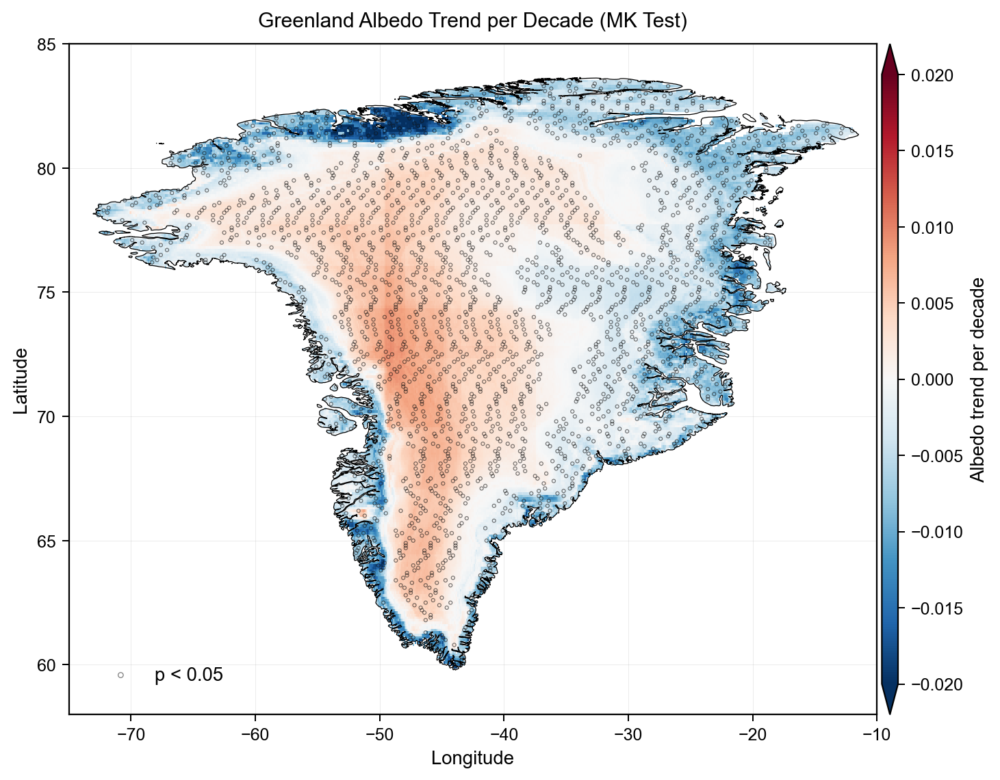

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
csv_path = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
shp_path  = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 读数据与处理 =====
df = pd.read_csv(csv_path, sep=None, engine="python",
                 usecols=["lat","lon","trend_per_decade","significant_95pct"])
df["lat"] = np.round(df["lat"].astype(float), 1)
df["lon"] = np.round(df["lon"].astype(float), 1)
df["significant_95pct"] = df["significant_95pct"].astype(str).str.upper().isin(
    ["TRUE","T","1","YES","Y"]
)
df = df.groupby(["lat","lon"], as_index=False).agg(
    trend_per_decade=("trend_per_decade","mean"),
    significant_95pct=("significant_95pct","max")
)

# ===== 构造网格（不插值）=====
lats = np.sort(df["lat"].unique())
lons = np.sort(df["lon"].unique())
dlat = np.median(np.diff(lats))
dlon = np.median(np.diff(lons))
lat_edges = np.arange(lats.min()-dlat/2, lats.max()+dlat/2+dlat*0.01, dlat)
lon_edges = np.arange(lons.min()-dlon/2, lons.max()+dlon/2+dlon*0.01, dlon)

grid = df.pivot(index="lat", columns="lon", values="trend_per_decade")
grid = grid.reindex(index=lats, columns=lons)
Z = np.ma.masked_invalid(grid.values)

# 显著点（抽稀）
sig = df[df["significant_95pct"]].iloc[::20]

# ===== 边界 =====
gld = gpd.read_file(shp_path)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 绘图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

fig, ax = plt.subplots(figsize=(8, 16), dpi=180)  # 保持比例与尺寸

# 色阶（红正蓝负，对称0）
norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)
pcm = ax.pcolormesh(lon_edges, lat_edges, Z, cmap="RdBu_r", norm=norm,
                    shading="flat", zorder=2)

# 显著性点
ax.scatter(sig["lon"], sig["lat"], s=4, facecolors="none", edgecolors="#111",
           linewidths=0.5, alpha=0.55, zorder=2.6, label="p < 0.05 ")

# 边界线
gld.boundary.plot(ax=ax, color="black", linewidth=0.5, zorder=4)

# 范围与比例（保持不变）
ax.set_xlim(-75, -10); ax.set_ylim(58, 85)
ax.set_aspect(2, adjustable="box")

# 网格
ax.grid(True, linewidth=0.4, alpha=0.25)

# 轴与标题
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Greenland Albedo Trend per Decade (MK Test)", pad=10)

# ===== 色条贴近主图（不改主图比例）=====
cax = inset_axes(
    ax, width="2.0%", height="100%",
    loc="lower left",
    bbox_to_anchor=(1.006, 0.0, 1.0, 1.0),  # 调第一个数微调间距：1.004更近/1.010更远
    bbox_transform=ax.transAxes,
    borderpad=0
)
cbar = plt.colorbar(pcm, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade")

# ===== 图例：放到图框内左下角 =====
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.02, 0.02),      # 轴坐标(0~1)内偏移，确保在图框内
    bbox_transform=ax.transAxes,
    frameon=False, fontsize=11, markerscale=1.5
)

# 避免裁切（不动主图比例）
plt.subplots_adjust(left=0.10, right=0.92, top=0.94, bottom=0.08)
plt.show()


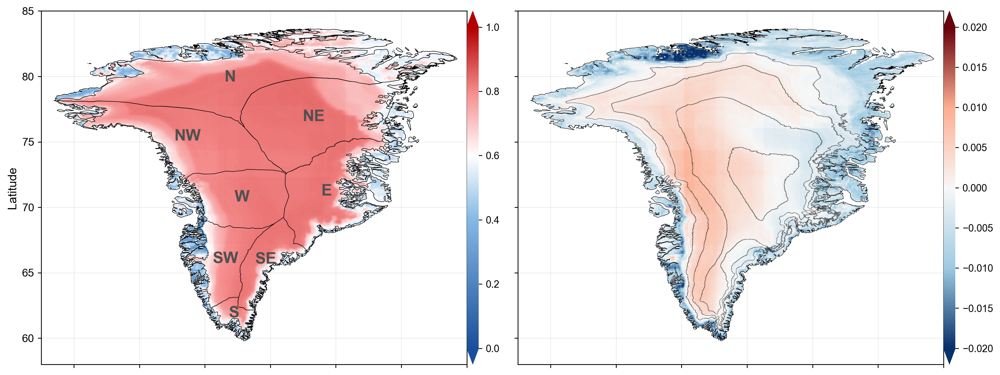

In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd

# ===== 路径 =====
albedo_nc = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
trend_csv = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend.csv"
contour_path = r"C:\greenland\Greenland_shp\等间距等值线.shp"
basin_dir = r"C:\greenland\Greenland_shp\流域冰盖"
boundary_shp = r"C:\greenland\Greenland_shp\Gboundry.shp"

# ===== 1. 读取 albedo 数据并计算长期平均 =====
ds = xr.open_dataset(albedo_nc)
varname = [v for v in ds.data_vars if 'albedo' in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim='time', skipna=True)

lats = albedo_mean['lat'].values
lons = albedo_mean['lon'].values
Z_mean = np.ma.masked_invalid(albedo_mean.values)

# ===== 2. 读取趋势数据 =====
df = pd.read_csv(trend_csv, sep=None, engine="python",
                 usecols=["lat", "lon", "trend_per_decade"])
df["lat"] = np.round(df["lat"].astype(float), 1)
df["lon"] = np.round(df["lon"].astype(float), 1)
df = df.groupby(["lat", "lon"], as_index=False).agg(
    trend_per_decade=("trend_per_decade", "mean")
)
lats_tr = np.sort(df["lat"].unique())
lons_tr = np.sort(df["lon"].unique())
grid = df.pivot(index="lat", columns="lon", values="trend_per_decade")
grid = grid.reindex(index=lats_tr, columns=lons_tr)
Z_trend = np.ma.masked_invalid(grid.values)

# ===== 3. 读取流域（主路径下的9个shp文件）=====
basin_files = [f for f in os.listdir(basin_dir) if f.endswith(".shp")]
basins_list = []
for f in basin_files:
    gdf = gpd.read_file(os.path.join(basin_dir, f))
    # 添加文件名作为标识
    gdf['filename'] = f.replace('.shp', '')
    basins_list.append(gdf)

basins = gpd.GeoDataFrame(pd.concat(basins_list, ignore_index=True), crs="EPSG:4326")

# ===== 流域标签映射（根据实际文件名）=====
label_mapping = {
    'East': 'E',
    'EastNorth': 'NE',
    'EastSouth': 'SE',
    'Melt': ' ',
    'North': 'N',
    'South': 'S',
    'West': 'W',
    'WestNorth': 'NW',
    'WestSouth': 'SW'
}

gld = gpd.read_file(boundary_shp)
gld = gld.to_crs(epsg=4326) if gld.crs else gld.set_crs(epsg=4326)

# ===== 4. 读取等高线并筛选500m线 =====
contours = gpd.read_file(contour_path)
contours = contours.to_crs(epsg=4326) if contours.crs else contours.set_crs(epsg=4326)
elev_field = None
for field in ['contour', 'CONTOUR', 'elev', 'ELEV', 'elevation', 'ELEVATION',
              'height', 'HEIGHT', 'Z', 'z']:
    if field in contours.columns:
        elev_field = field
        break
if elev_field:
    contours['elev_num'] = pd.to_numeric(contours[elev_field], errors='coerce')
    contours_500m = contours[contours['elev_num'] % 500 == 0].dropna(subset=['elev_num'])
else:
    contours_500m = contours

# ===== 5. 自定义色图 =====
colors_left = [
    (0.00, "#1a4f9b"),
    (0.40, "#85b8e3"),
    (0.60, "#ffffff"),
    (0.80, "#f58b8b"),
    (1.00, "#b30000")
]
cmap_left = LinearSegmentedColormap.from_list("mean_albedo_bluewhite", colors_left, N=256)

colors_right = [
    (0.00, "#08306b"),
    (0.25, "#9ecae1"),
    (0.50, "#f7f7f7"),
    (0.75, "#fcae91"),
    (1.00, "#67000d")
]
cmap_right = LinearSegmentedColormap.from_list("trend_stronger", colors_right, N=256)

# ===== 6. npj 风格参数 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

fig, axes = plt.subplots(1, 2, figsize=(15, 8), dpi=250, sharey=True)
(ax1, ax2) = axes

# ===== 左图：多年平均 Albedo =====
pcm1 = ax1.pcolormesh(lons, lats, Z_mean,
                      cmap=cmap_left, shading="gouraud",
                      vmin=0.0, vmax=1.0,
                      rasterized=True, zorder=2)
basins.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=3)
gld.boundary.plot(ax=ax1, color='black', linewidth=0.4, zorder=4)

# 添加流域标签（无边框，灰色Arial字体）
for idx, row in basins.iterrows():
    centroid = row.geometry.centroid
    filename = row['filename']
    
    # 查找对应的标签
    label = label_mapping.get(filename, None)
    
    if label:
        ax1.text(centroid.x, centroid.y, label,
                fontsize=16, fontweight='bold',
                family='Arial',
                ha='center', va='center',
                color='#505050',  # 灰色
                zorder=5)

ax1.set_xlim(-75, -10)
ax1.set_ylim(58, 85)
ax1.set_aspect(2)
ax1.set_ylabel("Latitude", fontsize=12)
ax1.tick_params(labelbottom=False)

# ===== 右图：Trend + DEM 等高线 =====
vmin, vmax = -0.020, 0.020
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
pcm2 = ax2.pcolormesh(lons_tr, lats_tr, Z_trend,
                      cmap=cmap_right, norm=norm,
                      shading="auto", rasterized=True, zorder=2)
contours_500m.plot(ax=ax2, color='black', linewidth=0.4, alpha=0.6, zorder=3)
gld.boundary.plot(ax=ax2, color='black', linewidth=0.4, zorder=4)
ax2.set_xlim(-75, -10)
ax2.set_ylim(58, 85)
ax2.set_aspect(2)
ax2.tick_params(labelbottom=False)

# ===== 色条：紧贴右边框 =====
# 左色条
cax_left = inset_axes(ax1, width="2.8%", height="100%",
                      loc="lower left",
                      bbox_to_anchor=(1.0, 0.0, 1.0, 1.0),
                      bbox_transform=ax1.transAxes, borderpad=0)
cbar_left = plt.colorbar(pcm1, cax=cax_left, extend="both")
cbar_left.outline.set_visible(False)
cbar_left.ax.tick_params(labelsize=10)

# 右色条
cax = inset_axes(ax2, width="2.8%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.0, 0.0, 1.0, 1.0),
                 bbox_transform=ax2.transAxes, borderpad=0)
cbar = plt.colorbar(pcm2, cax=cax, extend="both")
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=10)

# ===== 网格与布局 =====
for ax in axes:
    ax.grid(True, linewidth=0.4, alpha=0.25, color='gray', linestyle='-')

plt.subplots_adjust(left=0.08, right=0.92, top=0.96, bottom=0.08, wspace=0.12)
plt.show()

✅ Data range: 1950–2024 (75 years)


C:\Users\11823\AppData\Local\Temp\ipykernel_24328\3220741145.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


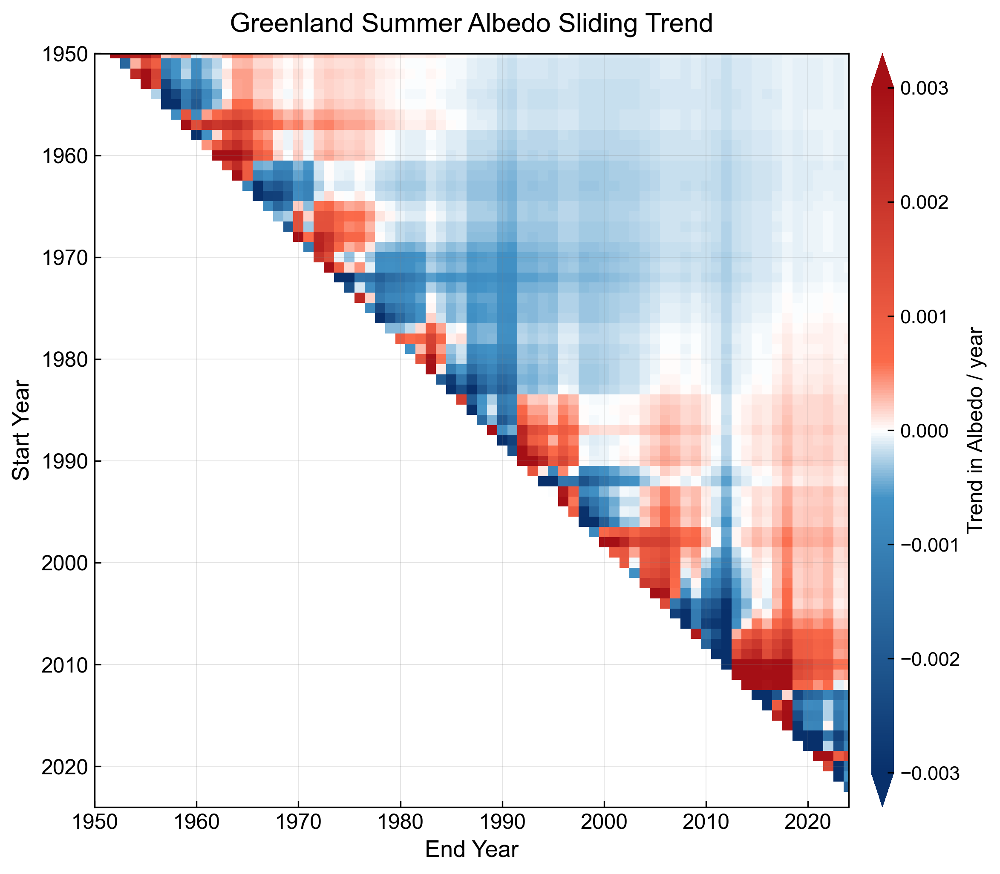

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 (Path - 请根据你的实际路径修改) =====
# 注意：你需要确保这个文件路径是正确的，并且文件存在
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
# 假设文件路径存在且数据结构正确
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含“albedo”的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 核心修改：计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 自定义色图（蓝-白-红，用于趋势） =====
# 这种色图非常适合 Nature 家族期刊风格，清晰地展示了正负趋势。
colors = [
    (0.00, "#08306b"),  # Darkest Blue
    (0.40, "#4292c6"),  # Light Blue
    (0.50, "#ffffff"),  # White Center (0)
    (0.60, "#fb6a4a"),  # Light Red
    (1.00, "#a50f15")   # Darkest Red
]
cmap = LinearSegmentedColormap.from_list("bluewhite_red_trend", colors, N=256)

# ===== 5. 绘图样式参数设置 =====
# 字体设置，推荐使用 Arial 或 Times New Roman 等通用字体
FONT_SIZE = 12 
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in", # 刻度线向内
    "ytick.direction": "in", # 刻度线向内
})

# ===== 6. 绘图 =====
# 调整 figsize 让图表看起来更宽敞
fig, ax = plt.subplots(figsize=(8.0, 7.0), dpi=300) 

# 设置颜色条的范围和中心点（对称色条的规范做法）
vmin, vmax = -0.003, 0.003
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

# 绘制热力图。由于 trend_matrix[i, j] 存储的是 i: Start Year, j: End Year，
# 且 Y 轴反转，所以数据显示在右上角。
pcm = ax.pcolormesh(years, years, trend_matrix,
                    cmap=cmap, norm=norm,
                    shading="auto", rasterized=True)

# ===== 7. 坐标与方向控制与刻度设置 =====
ax.set_xlim(years.min(), years.max())
# 关键：设置 Y 轴从上到下 (1950 在顶部)，与右图一致
ax.set_ylim(years.max(), years.min()) 
ax.set_aspect("equal")
ax.set_facecolor("white") # 背景色保持白色

ax.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 3, pad=12)

# 设置主要刻度（每隔10年）
tick_years = np.arange(years.min(), years.max() + 1, 10)
ax.set_xticks(tick_years)
ax.set_yticks(tick_years)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

# ===== 8. 色条（右侧对齐，等高） =====
# 使用 inset_axes 精确控制色条位置和大小
cax = inset_axes(ax, width="3%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
                 bbox_transform=ax.transAxes, borderpad=0)
# extend="both" 表示色条两端有三角，用于超范围的值
cbar = plt.colorbar(pcm, cax=cax, extend="both", 
                    ticks=np.linspace(vmin, vmax, 7)) # 增加刻度数量，更精细
cbar.set_label("Trend in Albedo / year", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-1)
cbar.outline.set_visible(False) # 移除边框，更简洁

# ===== 9. 网格与版面 =====
# 移除网格线，Nature 风格图表通常不使用网格线，或使用极浅色网格
# ax.grid(False) 
# 如果需要网格，使用以下设置：
ax.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

ds.close() # 关闭 xarray 数据集


✅ 数据读取成功，形状: (75, 75)
✅ 年份范围: 1950–2024
✅ 起始年份范围: 1950–2024


C:\Users\11823\AppData\Local\Temp\ipykernel_24328\2849176811.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


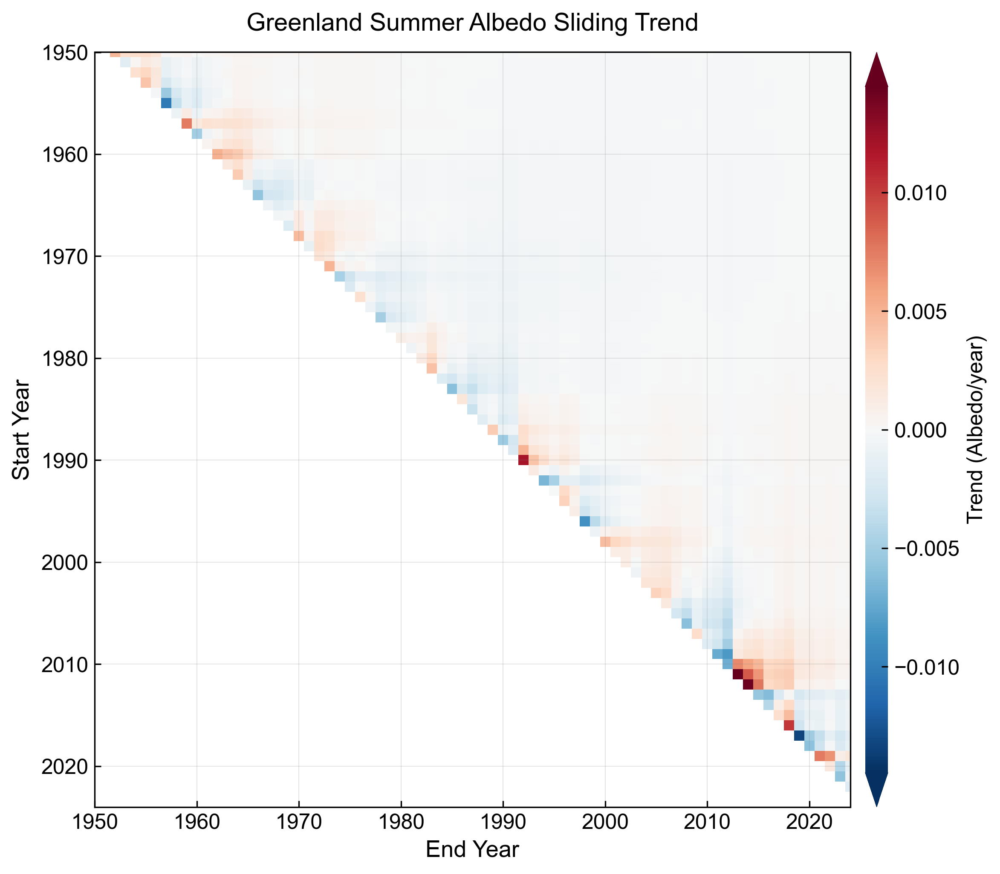

✅ 图片已保存


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径设置 =====
csv_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取 CSV 文件 =====
df = pd.read_csv(csv_path, index_col=0)
print(f"✅ 数据读取成功，形状: {df.shape}")

# ===== 2. 提取年份和数据 =====
years = df.columns.astype(int).values  # 列名转为年份数组
slide_years = df.index.astype(int).values  # 行索引转为年份数组
vals_masked = df.values  # 趋势矩阵

print(f"✅ 年份范围: {years.min()}–{years.max()}")
print(f"✅ 起始年份范围: {slide_years.min()}–{slide_years.max()}")

# ===== 3. 绘图参数设置 =====
FONT_SIZE = 12
CBAR_WIDTH = "3%"
CBAR_PAD = 0.05
UNIT_SLIDE = "Trend (Albedo/year)"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# ===== 4. 创建图形 =====
fig, ax2 = plt.subplots(figsize=(8, 7), dpi=300)

# ===== 5. (3) 滑动趋势热力图 =====
vmax_slide = np.nanmax(np.abs(vals_masked))
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, 
                     cmap="RdBu_r", 
                     norm=norm_slide, 
                     shading="auto",
                     rasterized=True)
ax2.invert_yaxis()

# 色条设置
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), 
                    bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax, extend='both')
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)

# ===== 6. 样式设置 =====
ax2.tick_params(labelsize=FONT_SIZE)
ax2.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax2.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax2.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 2, pad=12)

ax2.set_xticks(np.arange(1950, 2030, 10))
ax2.set_yticks(np.arange(1950, 2030, 10))
ax2.set_aspect('equal')

# 设置坐标轴范围
ax2.set_xlim(years.min(), years.max())
ax2.set_ylim(slide_years.max(), slide_years.min())

# 添加网格（可选）
ax2.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.savefig(r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.png", 
            dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ 图片已保存")

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import pymannkendall as mk

# --- 1. 文件路径和变量设置 ---
input_file = r"C:\greenland\1995bu\RACMO_greenland_albedo.nc"
csv_output_file = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv"
variable_name = 'alb' 
time_dim_name = 'time' 
trend_factor = 10  # 趋势乘以 10 得到每十年变化量
alpha = 0.05       # 95% 置信度

# --- 2. Mann-Kendall (MK) 核心函数 ---
def mann_kendall_test(data):
    """
    对一维时间序列数据执行 Mann-Kendall 和 Sen's Slope 测试。
    """
    # 移除 NaN 值
    data_clean = data[~np.isnan(data)]
    
    # 如果有效数据点少于 3 个,则无法计算趋势
    if len(data_clean) < 3:
        # 返回 Sen's Slope, P-value
        return np.nan, np.nan
    
    # 使用 pyMannKendall 的 original_test
    result = mk.original_test(data_clean)
    
    # 返回 Sen's Slope 和 P-value
    return result.slope, result.p

# --- 3. 空间计算 (使用 apply_ufunc) ---
try:
    ds = xr.open_dataset(input_file)
    data_array = ds[variable_name]
    
    # 确保时间维度名称存在
    if time_dim_name not in data_array.dims:
        raise ValueError(f"错误: DataArray 的维度中找不到 '{time_dim_name}'。实际维度有: {data_array.dims}")
    
    print(f"成功加载数据,变量: {variable_name},维度: {data_array.dims}")
    
except Exception as e:
    print(f"加载数据时发生错误: {e}")
    exit()

# 使用 apply_ufunc 沿时间维度对每个空间点进行计算
print("开始执行 Mann-Kendall 逐点计算...")
trend_results = xr.apply_ufunc(
    mann_kendall_test,
    data_array,
    input_core_dims=[[time_dim_name]],
    output_core_dims=[[], []],  
    vectorize=True,
    dask='parallelized', 
    output_dtypes=[np.float64, np.float64]
)

# 拆分结果：第一个结果是斜率,第二个是 P-值
trend_slope = trend_results[0].rename('trend_slope_per_year')
p_value = trend_results[1].rename('p_value')

# 计算每十年趋势
trend_per_decade = (trend_slope * trend_factor).rename('trend_per_decade')

# 创建显著性标记 (1 = 显著, 0 = 不显著)
is_significant = (p_value < alpha).astype(int).rename('significant_95pct')

# --- 4. 转换为 CSV 并保存 ---
# 准备用于 CSV 的结果 Dataset
results_ds = xr.Dataset({
    'trend_per_decade': trend_per_decade,
    'p_value': p_value,
    'significant_95pct': is_significant
})

# 将空间数据扁平化并转换为 Pandas DataFrame
df = results_ds.to_dataframe().reset_index()

# 筛选掉 NaN 值（无法计算趋势的格网点）
df = df.dropna(subset=['trend_per_decade'])

# 保存为 CSV 文件
df.to_csv(csv_output_file, index=False)

print(f"\n✅ 趋势计算完成。结果已保存到 CSV: {csv_output_file}")

成功加载数据,变量: alb,维度: ('time', 'height', 'rlat', 'rlon')
开始执行 Mann-Kendall 逐点计算...

✅ 趋势计算完成。结果已保存到 CSV: C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv


正在从NC文件提取真实经纬度坐标...
有效数据点数: 69988
显著点数量: 21451


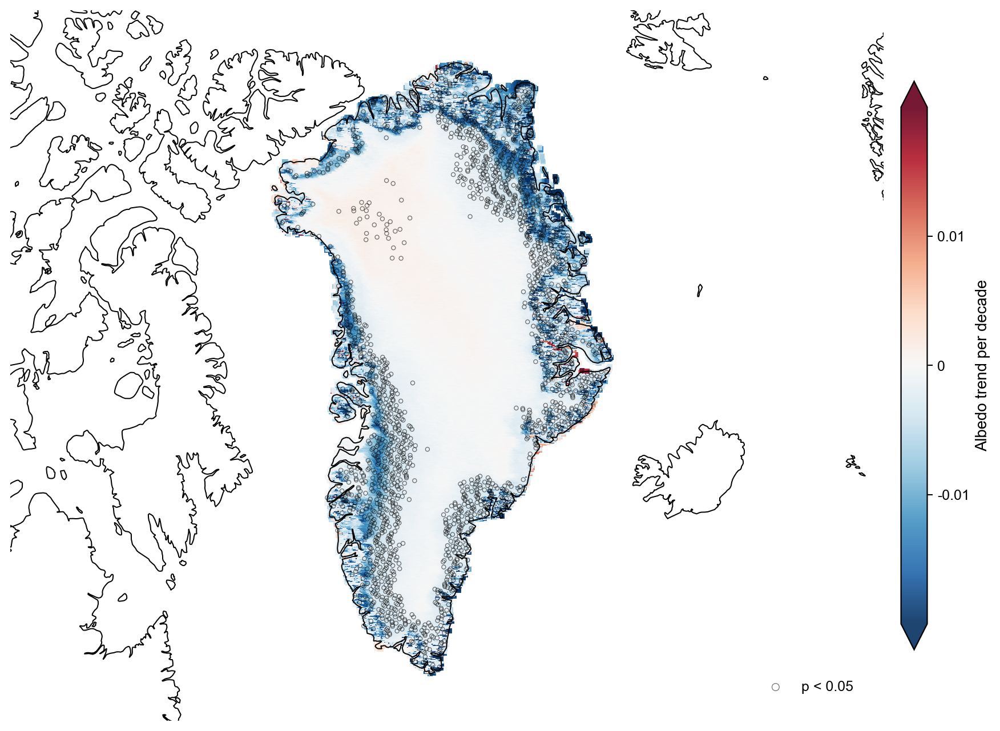

In [ ]:
# ====================================MK_Trend_RACMO====================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===== 路径 =====
csv_path = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv"
nc_path  = r"C:\greenland\1995bu\RACMO_greenland_albedo.nc"

# ===== 第1步: 从NC文件提取真实经纬度 =====
print("正在从NC文件提取真实经纬度坐标...")
ds = xr.open_dataset(nc_path)

if 'lat' in ds.coords or 'lat' in ds.data_vars:
    lat_2d = ds['lat'].values
    lon_2d = ds['lon'].values
else:
    raise KeyError("NC文件中未找到 'lat' 和 'lon' 变量")

# ===== 第2步: 读取CSV并匹配真实坐标 =====
df = pd.read_csv(csv_path)

# 匹配真实经纬度
df['lat'] = lat_2d[df['rlat'].astype(int), df['rlon'].astype(int)]
df['lon'] = lon_2d[df['rlat'].astype(int), df['rlon'].astype(int)]

# 只保留需要的列
df = df[["lat", "lon", "trend_per_decade", "significant_95pct"]].copy()
df["significant_95pct"] = df["significant_95pct"].astype(bool)

print(f"有效数据点数: {len(df)}")
print(f"显著点数量: {df['significant_95pct'].sum()}")

# 显著点（抽稀）
sig = df[df["significant_95pct"]].iloc[::10]

# ===== 第3步: 设置投影 =====
# 北极立体投影，中央经度 -45°W
proj = ccrs.NorthPolarStereo(central_longitude=-45)
data_crs = ccrs.PlateCarree()  # 原始数据是经纬度

# ===== 第4步: 绘图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
})

fig = plt.figure(figsize=(10, 10), dpi=180)
ax = fig.add_subplot(1, 1, 1, projection=proj)

# 设置地图范围（格陵兰区域，投影坐标）
ax.set_extent([-75, -10, 58, 85], crs=data_crs)

# 添加 Natural Earth 陆地边界
land = cfeature.NaturalEarthFeature(
    'physical', 'land', '50m',
    edgecolor='black',
    facecolor='none',
    linewidth=0.8
)
ax.add_feature(land, zorder=4)

# 色阶（红正蓝负，对称0）
norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)

# 用scatter绘制趋势（方形点填充）
sc = ax.scatter(
    df["lon"], df["lat"], 
    c=df["trend_per_decade"], 
    cmap="RdBu_r", 
    norm=norm, 
    s=12,  # 稍大以填充投影后的空间
    marker='s',
    edgecolors='none', 
    alpha=0.9, 
    transform=data_crs,  # 关键：告知数据是经纬度
    zorder=2
)

# 显著性点（空心圆）
ax.scatter(
    sig["lon"], sig["lat"], 
    s=8, 
    facecolors="none", 
    edgecolors="#111", 
    linewidths=0.5, 
    alpha=0.6,
    transform=data_crs,
    zorder=3,
    label="p < 0.05"
)

# 删除经纬度刻度和标签
ax.set_xticks([])
ax.set_yticks([])

# 删除图框（所有边框）
for spine in ax.spines.values():
    spine.set_visible(False)

# ===== 色条 =====
cax = inset_axes(
    ax, width="3%", height="80%",
    loc="lower left",
    bbox_to_anchor=(1.02, 0.1, 1.0, 1.0),
    bbox_transform=ax.transAxes,
    borderpad=0
)
cbar = plt.colorbar(sc, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade", fontsize=11)

# 色标刻度简化为 -0.1, 0, 0.1
cbar.set_ticks([-0.01, 0, 0.01])
cbar.set_ticklabels(['-0.01', '0', '0.01'])

# ===== 图例 =====
ax.legend(
    loc="lower right",
    bbox_to_anchor=(0.98, 0.02),
    bbox_transform=ax.transAxes,
    frameon=False, 
    fontsize=10, 
    markerscale=1.8
)

plt.subplots_adjust(left=0.05, right=0.90, top=0.98, bottom=0.02)
plt.show()

In [ ]:
import xarray as xr
import numpy as np
from datetime import datetime
import pandas as pd

def merge_nc_files(file1_path, file2_path, output_path):
    """
    合并两个NC文件：将file2的albedo变量添加到file1中
    
    参数:
        file1_path: 主文件路径 (ERA5LAND特征文件)
        file2_path: 要添加的文件路径 (albedo文件)
        output_path: 输出文件路径
    """
    
    print("=" * 80)
    print("开始合并NC文件")
    print("=" * 80)
    
    # 1. 读取两个文件
    print("\n[1/6] 读取文件...")
    ds1 = xr.open_dataset(file1_path)
    ds2 = xr.open_dataset(file2_path)
    
    print(f"  文件1: {ds1.dims}")
    print(f"  文件2: {ds2.dims}")
    
    # 2. 统一维度名称
    print("\n[2/6] 统一维度名称...")
    ds2 = ds2.rename({'lat': 'latitude', 'lon': 'longitude'})
    print(f"  文件2重命名后: {ds2.dims}")
    
    # 3. 处理空间分辨率差异
    print("\n[3/6] 检查空间网格...")
    
    lat1 = ds1['latitude'].values
    lon1 = ds1['longitude'].values
    lat2 = ds2['latitude'].values
    lon2 = ds2['longitude'].values
    
    print(f"  文件1纬度: {len(lat1)} 点, 范围 [{lat1.min():.2f}, {lat1.max():.2f}]")
    print(f"  文件2纬度: {len(lat2)} 点, 范围 [{lat2.min():.2f}, {lat2.max():.2f}]")
    print(f"  文件1经度: {len(lon1)} 点, 范围 [{lon1.min():.2f}, {lon1.max():.2f}]")
    print(f"  文件2经度: {len(lon2)} 点, 范围 [{lon2.min():.2f}, {lon2.max():.2f}]")
    
    # 插值文件2到文件1的空间网格
    if len(lat1) != len(lat2) or not np.allclose(lat1, lat2, atol=0.01):
        print("\n  ⚠️  空间网格不完全一致，将文件2插值到文件1的网格...")
        ds2_interp = ds2.interp(latitude=lat1, longitude=lon1, method='linear')
        print("  ✓ 插值完成")
    else:
        print("  ✓ 空间网格一致，无需插值")
        ds2_interp = ds2
    
    # 4. 处理时间维度
    print("\n[4/6] 处理时间维度...")
    
    # 将时间转换为datetime
    time1 = pd.to_datetime(ds1['time'].values, unit='s', origin='unix')
    time2 = pd.to_datetime(ds2_interp['time'].values, origin=pd.Timestamp('1950-01-01'), unit='D')
    
    print(f"  文件1时间范围: {time1.min()} 至 {time1.max()}")
    print(f"  文件2时间范围: {time2.min()} 至 {time2.max()}")
    
    # 更新文件2的时间坐标为datetime格式
    ds2_interp['time'] = time2
    
    # 找到时间交集或使用文件1的时间范围
    print("\n  选择合并策略:")
    print("  选项1: 仅保留时间重叠部分")
    print("  选项2: 保留文件1的所有时间，文件2缺失部分填充NaN")
    
    # 这里默认使用选项2：保留文件1的所有时间
    strategy = 2
    
    if strategy == 1:
        # 只保留重叠时间
        time_overlap = np.intersect1d(time1, time2)
        ds1_aligned = ds1.sel(time=time_overlap)
        ds2_aligned = ds2_interp.sel(time=time_overlap)
        print(f"  ✓ 使用策略1: 保留{len(time_overlap)}个重叠时间点")
    else:
        # 保留文件1的所有时间
        ds1_aligned = ds1
        ds2_aligned = ds2_interp.reindex(time=time1, method=None)  # 不匹配的时间填NaN
        print(f"  ✓ 使用策略2: 保留文件1的{len(time1)}个时间点")
        
        # 统计覆盖率
        valid_count = (~ds2_aligned['albedo'].isel(latitude=0, longitude=0).isnull()).sum().item()
        coverage = valid_count / len(time1) * 100
        print(f"  albedo数据覆盖率: {valid_count}/{len(time1)} ({coverage:.1f}%)")
    
    # 5. 合并变量
    print("\n[5/6] 合并变量...")
    
    # 提取albedo变量并添加到文件1
    ds_merged = ds1_aligned.copy()
    ds_merged['albedo'] = ds2_aligned['albedo']
    
    # 添加albedo变量的属性
    ds_merged['albedo'].attrs.update({
        'long_name': 'Surface Albedo',
        'units': '1',
        'source': 'Greenland_albedo1950-2024.nc',
        'description': 'Monthly surface albedo from Greenland albedo project'
    })
    
    print(f"  ✓ 已添加变量: albedo")
    print(f"  合并后的变量列表: {list(ds_merged.data_vars)}")
    
    # 6. 保存合并后的文件
    print(f"\n[6/6] 保存合并文件到: {output_path}")
    
    # 更新全局属性
    ds_merged.attrs['merged_date'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    ds_merged.attrs['merged_from'] = f"ERA5LAND + Greenland_albedo"
    ds_merged.attrs['merge_note'] = f"Added albedo variable from {file2_path}"
    
    # 设置编码参数以优化文件大小
    encoding = {}
    for var in ds_merged.data_vars:
        if var in ds_merged:
            encoding[var] = {
                'zlib': True,
                'complevel': 4,
                'dtype': 'float32' if ds_merged[var].dtype == np.float64 else ds_merged[var].dtype
            }
    
    ds_merged.to_netcdf(output_path, encoding=encoding)
    
    print("  ✓ 保存完成!")
    
    # 7. 验证结果
    print("\n" + "=" * 80)
    print("合并结果验证")
    print("=" * 80)
    
    ds_check = xr.open_dataset(output_path)
    print(f"\n文件维度: {ds_check.dims}")
    print(f"\n变量列表 ({len(ds_check.data_vars)} 个):")
    for var in ds_check.data_vars:
        shape_str = 'x'.join(map(str, ds_check[var].shape))
        print(f"  {var:20s} [{shape_str}]")
    
    # 检查albedo数据
    albedo_valid = (~ds_check['albedo'].isnull()).sum().item()
    albedo_total = ds_check['albedo'].size
    print(f"\nalbedo有效数据: {albedo_valid:,} / {albedo_total:,} ({albedo_valid/albedo_total*100:.1f}%)")
    
    if albedo_valid > 0:
        print(f"albedo值范围: [{float(ds_check['albedo'].min()):.3f}, {float(ds_check['albedo'].max()):.3f}]")
    
    ds_check.close()
    ds1.close()
    ds2.close()
    
    print("\n" + "=" * 80)
    print("✓ 合并完成!")
    print("=" * 80)


# 主程序
if __name__ == "__main__":
    # 文件路径
    file1 = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc"
    file2 = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"
    output = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LAND_with_albedo.nc"
    
    # 执行合并
    merge_nc_files(file1, file2, output)

NC文件信息检查

【文件1】: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc
--------------------------------------------------------------------------------

【维度信息】
  time: 902 
  latitude: 239 
  longitude: 612 

【变量列表】(16 个变量)
  number               int64      () []
  time                 int64      (time) [902]
  expver               <class 'str'> (time) [902]
  spatial_ref          int64      () []
  t2m                  float32    (time, latitude, longitude) [902x239x612]
  asn                  float32    (time, latitude, longitude) [902x239x612]
  fal                  float32    (time, latitude, longitude) [902x239x612]
  slhf                 float32    (time, latitude, longitude) [902x239x612]
  str                  float32    (time, latitude, longitude) [902x239x612]
  ssrd                 float32    (time, latitude, longitude) [902x239x612]
  strd                 float32    (time, latitude, longitude) [902x239x612]
  u10                  float32    (time

正在从NC文件提取真实经纬度坐标...
有效数据点数: 69988
显著点数量: 21451


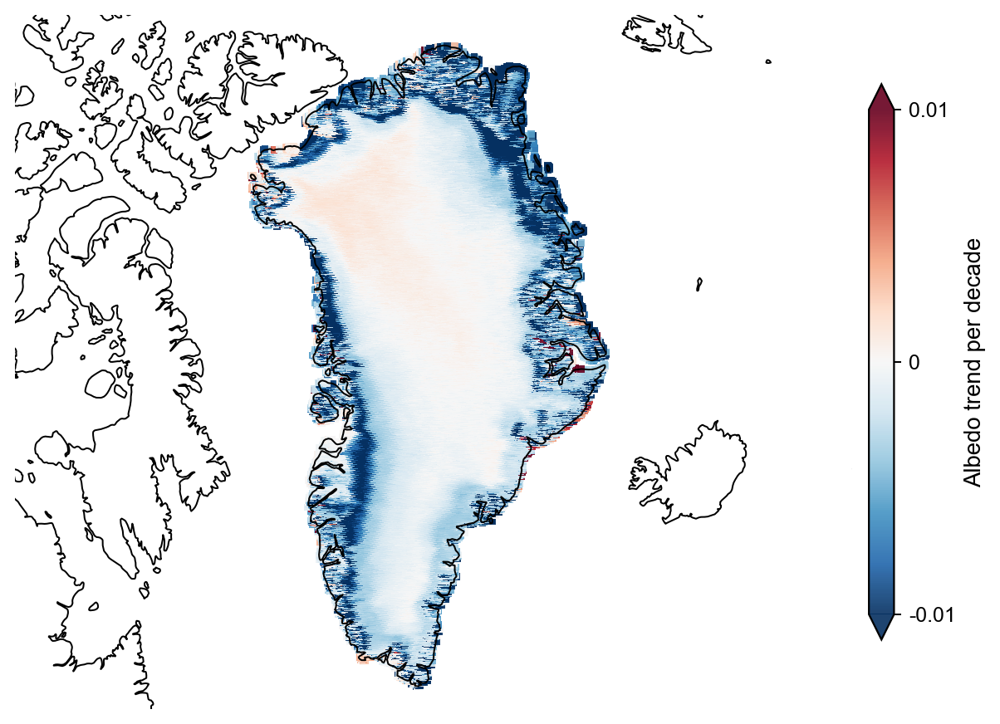

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import geopandas as gpd
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===== 路径 =====
csv_path = r"C:\greenland\1995bu\Greenland_albedo_MK_Trend_RACMO.csv"
nc_path  = r"C:\greenland\1995bu\RACMO_greenland_albedo.nc"

# ===== 第1步: 从NC文件提取真实经纬度 =====
print("正在从NC文件提取真实经纬度坐标...")
ds = xr.open_dataset(nc_path)

if 'lat' in ds.coords or 'lat' in ds.data_vars:
    lat_2d = ds['lat'].values
    lon_2d = ds['lon'].values
else:
    raise KeyError("NC文件中未找到 'lat' 和 'lon' 变量")

# ===== 第2步: 读取CSV并匹配真实坐标 =====
df = pd.read_csv(csv_path)

# 匹配真实经纬度
df['lat'] = lat_2d[df['rlat'].astype(int), df['rlon'].astype(int)]
df['lon'] = lon_2d[df['rlat'].astype(int), df['rlon'].astype(int)]

# 只保留需要的列
df = df[["lat", "lon", "trend_per_decade", "significant_95pct"]].copy()
df["significant_95pct"] = df["significant_95pct"].astype(bool)

print(f"有效数据点数: {len(df)}")
print(f"显著点数量: {df['significant_95pct'].sum()}")

# 显著点（抽稀）
sig = df[df["significant_95pct"]].iloc[::10]

# ===== 第3步: 设置投影 =====
# 北极立体投影，中央经度 -45°W
proj = ccrs.NorthPolarStereo(central_longitude=-45)
data_crs = ccrs.PlateCarree()  # 原始数据是经纬度

# ===== 第4步: 绘图 =====
plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.9,
})

fig = plt.figure(figsize=(7, 11), dpi=180)
ax = fig.add_subplot(1, 1, 1, projection=proj)

# 缩小地图范围，只显示格陵兰核心区域
ax.set_extent([-73, -12, 59, 84], crs=data_crs)

# 添加 Natural Earth 陆地边界
land = cfeature.NaturalEarthFeature(
    'physical', 'land', '50m',
    edgecolor='black',
    facecolor='none',
    linewidth=0.8
)
ax.add_feature(land, zorder=4)

# 色阶（红正蓝负，对称0）- 修正范围匹配刻度
norm = TwoSlopeNorm(vmin=-0.01, vcenter=0.0, vmax=0.01)

# 过滤数据：只保留格陵兰范围内的点
mask = (df["lon"] >= -73) & (df["lon"] <= -12) & (df["lat"] >= 59) & (df["lat"] <= 84)
df_filtered = df[mask]

# 用scatter绘制趋势（方形点填充）
sc = ax.scatter(
    df_filtered["lon"], df_filtered["lat"], 
    c=df_filtered["trend_per_decade"], 
    cmap="RdBu_r", 
    norm=norm, 
    s=12,  # 稍大以填充投影后的空间
    marker='s',
    edgecolors='none', 
    alpha=0.9, 
    transform=data_crs,  # 关键：告知数据是经纬度
    zorder=2
)

# 删除经纬度刻度和标签
ax.set_xticks([])
ax.set_yticks([])

# 删除图框（所有边框）
for spine in ax.spines.values():
    spine.set_visible(False)

# ===== 色条 =====
cax = inset_axes(
    ax, width="3%", height="80%",
    loc="lower left",
    bbox_to_anchor=(1.02, 0.1, 1.0, 1.0),
    bbox_transform=ax.transAxes,
    borderpad=0
)
cbar = plt.colorbar(sc, cax=cax, extend="both")
cbar.set_label("Albedo trend per decade", fontsize=11)

# 色标刻度简化为 -0.01, 0, 0.01
cbar.set_ticks([-0.01, 0, 0.01])
cbar.set_ticklabels(['-0.01', '0', '0.01'])

plt.subplots_adjust(left=0.08, right=0.88, top=0.98, bottom=0.02)
plt.show()

🚀 开始大规模时空回归分析
数据清洗: 原始样本 65,269,800 -> 有效样本 27,947,700

分析 strd 与 albedo 的回归关系...
  - 回归系数 (Slope): -2.1886e-08
  - 决定系数 (R²): 0.3896
  - P-value: 0.0000e+00 (显著)

分析 ssrd 与 albedo 的回归关系...
  - 回归系数 (Slope): 6.2996e-10
  - 决定系数 (R²): 0.0024
  - P-value: 0.0000e+00 (显著)

分析 t2m 与 albedo 的回归关系...
  - 回归系数 (Slope): -7.8889e-03
  - 决定系数 (R²): 0.4043
  - P-value: 0.0000e+00 (显著)

[可视化] 正在生成相关性散图...


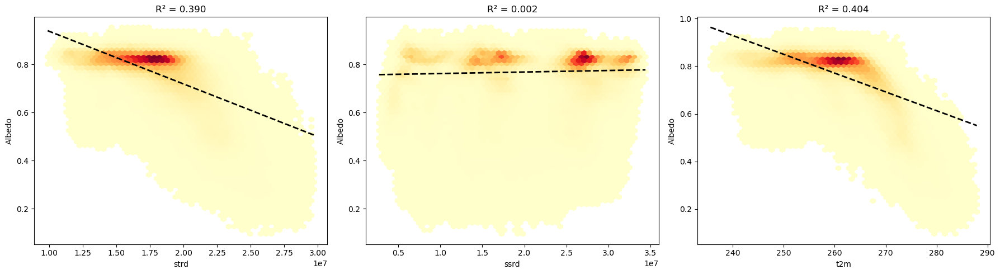

In [3]:
import xarray as xr
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

def analyze_albedo_regression(file_path):
    print("=" * 60)
    print("🚀 开始大规模时空回归分析")
    print("=" * 60)

    # 1. 读取数据
    ds = xr.open_dataset(file_path)
    
    # 2. 准备变量并扁平化 (Stacking all dimensions into one)
    # 这样会将 (time, lat, lon) 转换为一个巨大的索引
    vars_to_extract = ['albedo', 'strd', 'ssrd', 't2m']
    df = ds[vars_to_extract].to_dataframe().reset_index()

    # 3. 清洗数据 (关键：剔除 NaN 值)
    # 格陵兰岛周围大面积是海洋，NaN 必须剔除，否则回归无法运行
    initial_count = len(df)
    df = df.dropna(subset=vars_to_extract)
    print(f"数据清洗: 原始样本 {initial_count:,} -> 有效样本 {len(df):,}")

    # 4. 定义回归函数
    def run_regression(x_name, y_name='albedo'):
        print(f"\n分析 {x_name} 与 {y_name} 的回归关系...")
        
        X = df[x_name].values
        Y = df[y_name].values
        
        # 统计学回归 (增加常数项)
        X_with_const = sm.add_constant(X)
        model = sm.OLS(Y, X_with_const).fit()
        
        coef = model.params[1]    # 斜率
        p_val = model.pvalues[1]  # P值
        r2 = model.rsquared       # R方
        
        print(f"  - 回归系数 (Slope): {coef:.4e}")
        print(f"  - 决定系数 (R²): {r2:.4f}")
        print(f"  - P-value: {p_val:.4e} ({'显著' if p_val < 0.05 else '不显著'})")
        
        return X, Y, model

    # 5. 执行分析
    results = {}
    for x_var in ['strd', 'ssrd', 't2m']:
        results[x_var] = run_regression(x_var)

    # 6. 可视化 (由于点太多，使用十六进制箱图 Hexbin 或 采样绘制)
    print("\n[可视化] 正在生成相关性散图...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, x_var in enumerate(['strd', 'ssrd', 't2m']):
        X, Y, model = results[x_var]
        # 使用 hexbin 绘制密度，避免几百万个点堆叠导致卡顿
        hb = axes[i].hexbin(X, Y, gridsize=50, cmap='YlOrRd', mincnt=1)
        axes[i].set_xlabel(x_var)
        axes[i].set_ylabel('Albedo')
        axes[i].set_title(f'R² = {model.rsquared:.3f}')
        
        # 绘制回归线
        x_range = np.linspace(X.min(), X.max(), 100)
        axes[i].plot(x_range, model.params[0] + model.params[1]*x_range, 'k--', lw=2)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_Final_Features.nc"
    analyze_albedo_regression(path)

In [2]:
import xarray as xr

def force_all_to_time(input_path, output_path):
    print("=" * 60)
    print("🚀 强制统一：所有时间维都变成 time（忽略 valid_time 的具体取值）")

    ds = xr.open_dataset(input_path, chunks={})

    if "time" not in ds.coords and "time" not in ds.dims:
        raise ValueError("文件里根本没有 'time'，无法强制统一到 time。")

    # 1) 先把 valid_time 改成临时名，避免与已有 time 冲突
    if "valid_time" in ds.dims or "valid_time" in ds.coords:
        ds = ds.rename({"valid_time": "_vtime"})

    time_coord = ds["time"]

    # 2) 把所有带 _vtime 的变量：维度名改成 time，并强制挂到 ds['time'] 这个坐标
    new_vars = {}
    for v in ds.data_vars:
        da = ds[v]
        if "_vtime" in da.dims:
            da2 = da.rename({"_vtime": "time"})
            # 强制使用已有 time 坐标（不 align，不检查长度以外的东西）
            if da2.sizes["time"] != time_coord.sizes["time"]:
                # 你说步长不重要，但维度长度必须一致才能硬挂
                # 这里直接截断/补齐到与 ds['time'] 同长度（取最简单粗暴的截断）
                n = min(da2.sizes["time"], time_coord.sizes["time"])
                da2 = da2.isel(time=slice(0, n))
                # 如果 ds['time'] 更长，就同步截断 time_coord（保持一致）
                # 更推荐：你自己先决定以哪个长度为准
                time_coord2 = time_coord.isel(time=slice(0, n))
            else:
                time_coord2 = time_coord

            da2 = da2.assign_coords(time=time_coord2)

            new_vars[v] = da2
        else:
            new_vars[v] = da

    ds2 = xr.Dataset(new_vars, coords={k: ds.coords[k] for k in ds.coords if k != "_vtime"})
    ds2 = ds2.drop_vars("_vtime", errors="ignore")

    print(f"写入文件: {output_path}")
    ds2.to_netcdf(output_path)

    ds.close()
    print("=" * 60)
    print("✅ 完成：所有变量只存在 time 这一套时间维。")

if __name__ == "__main__":
    SRC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_Full_Features_v2.nc"
    DST = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"
    force_all_to_time(SRC, DST)


🚀 强制统一：所有时间维都变成 time（忽略 valid_time 的具体取值）
写入文件: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc
✅ 完成：所有变量只存在 time 这一套时间维。


In [ ]:
# -*- coding: utf-8 -*-
"""
Step 1 — 检查9个流域分区合并后是否与全冰盖边界一致
"""

import geopandas as gpd
import os, glob
from shapely.ops import unary_union

# ========= 路径 =========
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"   # 只用这一层
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_DIFF  = r"C:\greenland\Greenland_shp\check_merge_diff.shp"

# ========= 读取9个分区 =========
basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
print(f"检测到 {len(basin_shps)} 个分区文件：")
for shp in basin_shps:
    print("  -", os.path.basename(shp))

gdfs = []
for shp in basin_shps:
    g = gpd.read_file(shp)
    if g.crs is None:
        g.set_crs("EPSG:4326", inplace=True)
    else:
        g = g.to_crs("EPSG:4326")
    g = g.dissolve().reset_index(drop=True)
    gdfs.append(g)

# ========= 合并9个分区 =========
merged = gpd.GeoDataFrame(geometry=[unary_union([geom for g in gdfs for geom in g.geometry])], crs="EPSG:4326")

# ========= 读入全冰盖边界 =========
full = gpd.read_file(FULL_SHP)
if full.crs is None:
    full.set_crs("EPSG:4326", inplace=True)
else:
    full = full.to_crs("EPSG:4326")

# ========= 比较差异 =========
diff = full.overlay(merged, how="difference")

print("\n===== 检查结果 =====")
print(f"差异多边形数量: {len(diff)}")

# 输出面积比较（km²）
full_area = full.to_crs("EPSG:3413").area.sum()/1e6
merged_area = merged.to_crs("EPSG:3413").area.sum()/1e6
diff_area = abs(full_area - merged_area)

print(f"全冰盖面积: {full_area:.2f} km²")
print(f"合并9分区面积: {merged_area:.2f} km²")
print(f"面积差异: {diff_area:.2f} km²")

if len(diff) > 0:
    diff.to_file(OUT_DIFF)
    print(f"⚠ 检测到不完全一致，差异区域已输出: {OUT_DIFF}")
else:
    print("✅ 分区合并结果与主冰盖边界一致。")


检测到 9 个分区文件：
  - East.shp
  - EastNorth.shp
  - EastSouth.shp
  - North.shp
  - South.shp
  - West.shp
  - WestNorth.shp
  - WestSouth.shp
  - melt.shp

===== 检查结果 =====
差异多边形数量: 0
全冰盖面积: 2143693.92 km²
合并9分区面积: 2144891.12 km²
面积差异: 1197.20 km²
✅ 分区合并结果与主冰盖边界一致。


In [1]:
# -*- coding: utf-8 -*-
import os
import gc
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import linregress
import geopandas as gpd
from rasterio import features
from rasterio.transform import from_origin
from numba import jit

# ===================== 0) 工具:识别时间坐标名 =====================
def _get_time_coord_name(ds: xr.Dataset) -> str:
    for cand in ["time", "valid_time"]:
        if cand in ds.coords or cand in ds.dims:
            return cand
    raise ValueError("No time coordinate/dimension found.")

def _get_lat_lon_names(ds: xr.Dataset):
    lat_name = "latitude" if "latitude" in ds.coords else ("lat" if "lat" in ds.coords else None)
    lon_name = "longitude" if "longitude" in ds.coords else ("lon" if "lon" in ds.coords else None)
    if lat_name is None or lon_name is None:
        raise ValueError("No lat/lon coords found.")
    return lat_name, lon_name

# ===================== 1) 工具:时间筛选(优化) =====================
def subset_by_year_month(ds: xr.Dataset, start_year: int, end_year: int, months=(4,5,6,7,8,9)) -> xr.Dataset:
    tname = _get_time_coord_name(ds)
    t = ds[tname]
    
    # 直接使用向量化操作
    year = t.dt.year.values
    month = t.dt.month.values
    
    mask = (year >= start_year) & (year <= end_year) & np.isin(month, months)
    return ds.isel({tname: mask})

# ===================== 2) 栅格化:shp -> 2D mask(优化) =====================
def shp_to_mask(shp_path, lats_1d, lons_1d, target_crs="EPSG:4326", all_touched=False):
    gdf = gpd.read_file(shp_path)
    if gdf.crs is None:
        gdf = gdf.set_crs(target_crs)
    elif str(gdf.crs) != target_crs:
        gdf = gdf.to_crs(target_crs)
    
    geom = gdf.geometry.buffer(0).union_all()
    
    # 确保是numpy数组且连续内存
    lons = np.ascontiguousarray(lons_1d)
    lats = np.ascontiguousarray(lats_1d)
    
    dx = float(np.abs(lons[1] - lons[0])) if len(lons) > 1 else 0.1
    dy = float(np.abs(lats[1] - lats[0])) if len(lats) > 1 else 0.1
    
    lon_min, lon_max = float(lons.min()), float(lons.max())
    lat_min, lat_max = float(lats.min()), float(lats.max())
    
    transform = from_origin(lon_min - dx/2, lat_max + dy/2, dx, dy)
    out_shape = (len(lats), len(lons))
    
    mask = features.rasterize(
        [(geom, 1)],
        out_shape=out_shape,
        transform=transform,
        fill=0,
        dtype=np.uint8,
        all_touched=all_touched
    ).astype(bool)
    
    if lats[0] < lats[-1]:
        mask = np.flipud(mask)
    
    return mask

# ===================== 3) 快速回归计算(使用numba加速) =====================
@jit(nopython=True, cache=True)
def fast_linregress(x, y):
    """使用numba加速的线性回归"""
    n = len(x)
    if n < 2:
        return 0.0, 0.0, 0
    
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    
    # 计算协方差和方差
    xy_cov = np.sum((x - x_mean) * (y - y_mean))
    x_var = np.sum((x - x_mean) ** 2)
    y_var = np.sum((y - y_mean) ** 2)
    
    if x_var == 0 or y_var == 0:
        return 0.0, 0.0, n
    
    slope = xy_cov / x_var
    r2 = (xy_cov ** 2) / (x_var * y_var)
    
    return slope, r2, n

# ===================== 4) 核心回归(批量优化) =====================
def regress_for_mask_optimized(ds, albedo_np, mask_2d, features_list):
    """优化版:一次性提取所有变量数据,减少重复计算"""
    # 提取y值(一次性完成)
    y_masked = albedo_np[:, mask_2d]  # (time, n_pixels)
    
    # 找出所有时空点都有效的索引
    valid_pixels = ~np.isnan(y_masked).any(axis=0)
    if not valid_pixels.any():
        return []
    
    y_data = y_masked[:, valid_pixels].ravel()  # 展平
    valid_y = ~np.isnan(y_data)
    
    if valid_y.sum() < 100:
        return []
    
    y_final = y_data[valid_y]
    n_samples = len(y_final)
    
    rows = []
    for var in features_list:
        if var not in ds:
            continue
        
        # 直接获取numpy数组(避免xarray开销)
        x_var = ds[var].values
        x_masked = x_var[:, mask_2d][:, valid_pixels].ravel()
        x_filtered = x_masked[valid_y]
        
        # 去除NaN
        valid_idx = ~np.isnan(x_filtered)
        if valid_idx.sum() < 100:
            continue
        
        x_clean = x_filtered[valid_idx]
        y_clean = y_final[valid_idx]
        
        # 使用快速回归
        slope, r2, n = fast_linregress(x_clean, y_clean)
        
        rows.append({
            "var": var,
            "slope": float(slope),
            "r2": float(r2),
            "n": int(n),
        })
    
    return rows

# ===================== 5) 主函数(优化版) =====================
def analyze_regression_altitude_and_basins(
    file_path,
    basin_dir,
    start_year=1950,
    end_year=2024,
    months=(4,5,6,7,8,9),
    all_touched=False,
    save_csv=False,
    out_csv_path=None
):
    print("=" * 120)
    print(f"🚀 分析文件: {file_path}")
    print(f"时间筛选: {start_year}-{end_year}, months={tuple(months)}")
    print("=" * 120)
    
    # 使用chunks参数优化内存加载
    ds0 = xr.open_dataset(file_path, chunks={'time': 100})
    ds = subset_by_year_month(ds0, start_year, end_year, months)
    
    # 变量列表
    features_list = ['t2m','slhf','str','ssrd','strd','u10','v10','sp','tcc','sf','tp','rf']
    
    # 坐标
    lat_name, lon_name = _get_lat_lon_names(ds)
    lats = ds[lat_name].values
    lons = ds[lon_name].values
    
    # 一次性加载albedo到内存(避免重复I/O)
    print("📊 加载 albedo 数据到内存...")
    albedo = ds["albedo"].values
    
    # 预加载所有特征变量到内存(关键优化!)
    print("📊 预加载所有特征变量到内存...")
    for var in features_list:
        if var in ds:
            ds[var].load()
    
    results_all = []
    
    # ---------------- A) 海拔分箱 ----------------
    if "altitude" not in ds:
        raise ValueError("Dataset has no 'altitude' variable.")
    
    altitude = ds["altitude"].values
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, 5000]
    labels = ['0-500m','500-1000m','1000-1500m','1500-2000m','2000-2500m','2500-3000m','3000m+']
    
    print("\n" + "=" * 120)
    print("A) 按海拔分箱回归")
    print(f"{'海拔区间':<12} | {'样本总数':<12} | {'变量':<6} | {'回归斜率 (Slope)':<15} | {'R2'}")
    print("-" * 120)
    
    for i in range(len(bins) - 1):
        mask = (altitude >= bins[i]) & (altitude < bins[i+1])
        if not mask.any():
            continue
        
        rows = regress_for_mask_optimized(ds, albedo, mask, features_list)
        if not rows:
            continue
        
        first = True
        for r in rows:
            prefix = f"{labels[i]:<12} | {r['n']:<12,}" if first else f"{'':<12} | {'':<12}"
            first = False
            print(f"{prefix} | {r['var']:<6} | {r['slope']:<15.4e} | {r['r2']:.4f}")
            results_all.append({
                "group_type": "altitude",
                "group": labels[i],
                **r
            })
        print("-" * 120)
    
    # ---------------- B) 9 流域分区 ----------------
    regions = [
        ("East.shp", "E"),
        ("EastNorth.shp", "NE"),
        ("EastSouth.shp", "SE"),
        ("North.shp", "N"),
        ("South.shp", "S"),
        ("West.shp", "W"),
        ("WestNorth.shp", "NW"),
        ("WestSouth.shp", "SW"),
        ("melt.shp", "Melt"),
    ]
    
    print("\n" + "=" * 120)
    print("B) 按9流域分区回归")
    print(f"{'分区':<6} | {'样本总数':<12} | {'变量':<6} | {'回归斜率 (Slope)':<15} | {'R2'}")
    print("-" * 120)
    
    # 预先栅格化所有分区
    region_masks = {}
    for shp_file, name in regions:
        shp_path = os.path.join(basin_dir, shp_file)
        if not os.path.exists(shp_path):
            print(f"[跳过] 找不到 {shp_path}")
            continue
        region_masks[name] = shp_to_mask(shp_path, lats, lons, all_touched=all_touched)
    
    for name, mask in region_masks.items():
        if not mask.any():
            print(f"[跳过] {name} mask 为空")
            continue
        
        rows = regress_for_mask_optimized(ds, albedo, mask, features_list)
        if not rows:
            continue
        
        first = True
        for r in rows:
            prefix = f"{name:<6} | {r['n']:<12,}" if first else f"{'':<6} | {'':<12}"
            first = False
            print(f"{prefix} | {r['var']:<6} | {r['slope']:<15.4e} | {r['r2']:.4f}")
            results_all.append({
                "group_type": "basin",
                "group": name,
                **r
            })
        print("-" * 120)
    
    ds.close()
    ds0.close()
    gc.collect()
    
    print("=" * 120)
    print("✅ 完成:已输出海拔分箱 + 9流域分区 两套结果。")
    
    # 保存CSV
    if save_csv and results_all:
        df = pd.DataFrame(results_all)
        if out_csv_path is None:
            month_str = ''.join(map(str, months))
            out_csv_path = os.path.join(
                basin_dir, 
                f"regression_altitude_and_basins_{start_year}_{end_year}_m{month_str}.csv"
            )
        df.to_csv(out_csv_path, index=False, encoding="utf-8-sig")
        print(f"💾 已保存 CSV: {out_csv_path}")
    
    return results_all


if __name__ == "__main__":
    FINAL_NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"
    BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
    
    # 运行分析
    analyze_regression_altitude_and_basins(
        file_path=FINAL_NC,
        basin_dir=BASIN_DIR,
        start_year=1950,
        end_year=2024,
        months=(6,7,8),  # JJA
        all_touched=False,
        save_csv=True
    )

🚀 分析文件: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc
时间筛选: 1950-2024, months=(6, 7, 8)


C:\Users\11823\AppData\Local\Temp\ipykernel_23276\1032441235.py:167: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds0 = xr.open_dataset(file_path, chunks={'time': 100})


📊 加载 albedo 数据到内存...
📊 预加载所有特征变量到内存...

A) 按海拔分箱回归
海拔区间         | 样本总数         | 变量     | 回归斜率 (Slope)    | R2
------------------------------------------------------------------------------------------------------------------------
0-500m       | 1,165,050    | t2m    | -2.4343e-02     | 0.5067
             |              | slhf   | 5.8525e-08      | 0.4261
             |              | str    | 3.2302e-08      | 0.1976
             |              | ssrd   | 1.0027e-08      | 0.2194
             |              | strd   | -4.3683e-08     | 0.3416
             |              | u10    | 1.2711e-02      | 0.0124
             |              | v10    | -8.4388e-03     | 0.0051
             |              | sp     | 2.0701e-07      | 0.0000
             |              | tcc    | -1.9246e-01     | 0.0398
             |              | sf     | -1.0260e+00     | 0.0001
             |              | tp     | -3.2941e+00     | 0.0013
             |              | rf     | -4.8564e+01     | 0.0139


In [19]:
# -*- coding: utf-8 -*-
import os
import gc
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from rasterio import features
from rasterio.transform import from_origin
from numba import jit

# ===================== 0) 工具:识别时间坐标名 =====================
def _get_time_coord_name(ds: xr.Dataset) -> str:
    for cand in ["time", "valid_time"]:
        if cand in ds.coords or cand in ds.dims:
            return cand
    raise ValueError("No time coordinate/dimension found (time/valid_time).")

def _get_lat_lon_names(ds: xr.Dataset):
    lat_name = "latitude" if "latitude" in ds.coords else ("lat" if "lat" in ds.coords else None)
    lon_name = "longitude" if "longitude" in ds.coords else ("lon" if "lon" in ds.coords else None)
    if lat_name is None or lon_name is None:
        raise ValueError("No lat/lon coords found.")
    return lat_name, lon_name

def _ensure_time_lat_lon_3d(da: xr.DataArray, tname: str, lat_name: str, lon_name: str) -> xr.DataArray:
    """
    把变量强制为 (tname, lat_name, lon_name)
    - 允许 time/valid_time 混用，自动统一到 tname
    - squeeze 掉 size=1 的多余维度
    - 若仍有额外维度（如 level/expver），这里会报错，提示你需要先选取
    """
    # 统一时间维命名到 tname
    if tname not in da.dims:
        if "time" in da.dims and tname == "valid_time":
            da = da.rename({"time": "valid_time"})
        elif "valid_time" in da.dims and tname == "time":
            da = da.rename({"valid_time": "time"})

    da = da.squeeze(drop=True)

    need = {tname, lat_name, lon_name}
    if not need.issubset(set(da.dims)):
        raise ValueError(f"Variable {da.name} dims={da.dims} do not contain required {need}")

    # 如果还有别的维度，直接报错（避免 silently broadcast）
    extra = [d for d in da.dims if d not in [tname, lat_name, lon_name]]
    if extra:
        raise ValueError(f"Variable {da.name} has extra dims {extra}. Please select/squeeze them first.")

    return da.transpose(tname, lat_name, lon_name)

def _get_2d_latlon(da: xr.DataArray, lat_name: str, lon_name: str) -> xr.DataArray:
    """把2D变量强制为 (lat, lon)"""
    da = da.squeeze(drop=True)
    need = {lat_name, lon_name}
    if not need.issubset(set(da.dims)):
        raise ValueError(f"2D Variable {da.name} dims={da.dims} do not contain required {need}")
    extra = [d for d in da.dims if d not in [lat_name, lon_name]]
    if extra:
        raise ValueError(f"2D Variable {da.name} has extra dims {extra}. Please select/squeeze them first.")
    return da.transpose(lat_name, lon_name)

# ===================== 1) 时间筛选 =====================
def subset_by_year_month(ds: xr.Dataset, start_year: int, end_year: int, months=(4,5,6,7,8,9)) -> xr.Dataset:
    tname = _get_time_coord_name(ds)
    t = ds[tname]
    year = t.dt.year.values
    month = t.dt.month.values
    mask = (year >= start_year) & (year <= end_year) & np.isin(month, months)
    return ds.isel({tname: mask})

# ===================== 2) shp -> mask =====================
def shp_to_mask(shp_path, lats_1d, lons_1d, target_crs="EPSG:4326", all_touched=False):
    gdf = gpd.read_file(shp_path)
    if gdf.crs is None:
        gdf = gdf.set_crs(target_crs)
    elif str(gdf.crs) != target_crs:
        gdf = gdf.to_crs(target_crs)

    geom = gdf.geometry.buffer(0).union_all()

    lons = np.ascontiguousarray(lons_1d)
    lats = np.ascontiguousarray(lats_1d)

    dx = float(np.abs(lons[1] - lons[0])) if len(lons) > 1 else 0.1
    dy = float(np.abs(lats[1] - lats[0])) if len(lats) > 1 else 0.1

    lon_min = float(lons.min())
    lat_max = float(lats.max())

    transform = from_origin(lon_min - dx/2, lat_max + dy/2, dx, dy)
    out_shape = (len(lats), len(lons))

    mask = features.rasterize(
        [(geom, 1)],
        out_shape=out_shape,
        transform=transform,
        fill=0,
        dtype=np.uint8,
        all_touched=all_touched
    ).astype(bool)

    if lats[0] < lats[-1]:
        mask = np.flipud(mask)
    return mask

# ===================== 3) 单变量回归（numba） =====================
@jit(nopython=True, cache=True)
def fast_linregress(x, y):
    n = len(x)
    if n < 2:
        return 0.0, 0.0, 0.0, 0
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    xy_cov = np.sum((x - x_mean) * (y - y_mean))
    x_var = np.sum((x - x_mean) ** 2)
    y_var = np.sum((y - y_mean) ** 2)
    if x_var == 0.0 or y_var == 0.0:
        return 0.0, 0.0, 0.0, n
    slope = xy_cov / x_var
    r2 = (xy_cov ** 2) / (x_var * y_var)
    r = xy_cov / np.sqrt(x_var * y_var)
    return slope, r2, r, n

# ===================== 4) 多变量：β_std + partial R² =====================
def multivar_beta_partialr2(X, y, varnames, min_n=5000):
    n = int(y.shape[0])
    p = int(X.shape[1])
    if n < max(min_n, p + 10):
        return []

    y = y.astype(np.float64, copy=False)
    X = X.astype(np.float64, copy=False)

    y_mean = y.mean()
    y_std = y.std()
    if y_std == 0:
        return []
    y_z = (y - y_mean) / y_std

    X_mean = X.mean(axis=0)
    X_std = X.std(axis=0)
    keep = X_std > 0
    if not np.all(keep):
        X = X[:, keep]
        X_mean = X_mean[keep]
        X_std = X_std[keep]
        varnames = [v for v, k in zip(varnames, keep) if k]
        p = X.shape[1]
        if p == 0:
            return []

    X_z = (X - X_mean) / X_std

    X_design = np.concatenate([np.ones((n, 1), dtype=np.float64), X_z], axis=1)
    XtX = X_design.T @ X_design
    Xty = X_design.T @ y_z
    XtX += np.eye(p + 1) * 1e-10

    try:
        XtX_inv = np.linalg.inv(XtX)
    except np.linalg.LinAlgError:
        return []

    coef = XtX_inv @ Xty
    y_hat = X_design @ coef
    resid = y_z - y_hat
    sse = float(resid.T @ resid)
    df = max(n - (p + 1), 1)
    sigma2 = sse / df

    se = np.sqrt(np.diag(XtX_inv) * sigma2)
    tvals = coef / se

    beta = coef[1:]
    t_beta = tvals[1:]
    partial_r2 = (t_beta**2) / (t_beta**2 + df)

    out = []
    for j, v in enumerate(varnames):
        out.append({"var": v, "beta_std": float(beta[j]), "t": float(t_beta[j]),
                    "partial_r2": float(partial_r2[j]), "n": int(n)})
    return out

# ===================== 5) 对mask计算：单变量 + 多变量 =====================
def regress_for_mask_with_attribution(
    ds, tname, lat_name, lon_name,
    albedo_da, mask_2d,
    features_list, multivar_list,
    min_samples=1000,
    max_multi_n=200000,
    seed=0
):
    rng = np.random.default_rng(seed)

    # 基准：albedo (time, lat, lon)
    y3 = _ensure_time_lat_lon_3d(albedo_da, tname, lat_name, lon_name)
    T = y3.sizes[tname]

    y = y3.values[:, mask_2d].reshape(T, -1)          # (T, n_pix)
    valid_pix = ~np.isnan(y).any(axis=0)              # 剔除时间上有NaN的像元
    if not valid_pix.any():
        return [], []

    yv = y[:, valid_pix].ravel()                      # 基准扁平向量，长度固定
    base_valid = ~np.isnan(yv)
    if base_valid.sum() < min_samples:
        return [], []

    y_base = yv[base_valid].astype(np.float32, copy=False)

    # ---------- 单变量 ----------
    univar_rows = []
    for var in features_list:
        if var not in ds:
            continue
        da = _ensure_time_lat_lon_3d(ds[var], tname, lat_name, lon_name)
        x = da.values[:, mask_2d].reshape(T, -1)[:, valid_pix].ravel()
        x = x[base_valid]  # 与 y_base 同长度

        ok = ~np.isnan(x)
        if ok.sum() < min_samples:
            continue

        slope, r2, r, n = fast_linregress(x[ok].astype(np.float32, copy=False),
                                          y_base[ok].astype(np.float32, copy=False))
        univar_rows.append({"var": var, "slope": float(slope), "r2": float(r2), "r": float(r), "n": int(n)})

    # ---------- 多变量 ----------
    present = [v for v in multivar_list if v in ds]
    if len(present) < 2:
        return univar_rows, []

    X_cols = []
    for v in present:
        da = _ensure_time_lat_lon_3d(ds[v], tname, lat_name, lon_name)
        x = da.values[:, mask_2d].reshape(T, -1)[:, valid_pix].ravel()
        x = x[base_valid]
        X_cols.append(x.astype(np.float32, copy=False))

    X = np.stack(X_cols, axis=1)  # (n, p)
    yv2 = y_base

    row_ok = ~np.isnan(yv2) & ~np.isnan(X).any(axis=1)
    if row_ok.sum() < 5000:
        del X, X_cols
        return univar_rows, []

    X = X[row_ok, :]
    yv2 = yv2[row_ok]

    n = yv2.size
    if n > max_multi_n:
        idx = rng.choice(n, size=max_multi_n, replace=False)
        X = X[idx, :]
        yv2 = yv2[idx]

    multi_rows = multivar_beta_partialr2(X, yv2, present, min_n=5000)

    del X, X_cols, yv2
    return univar_rows, multi_rows

# ===================== 6) 主函数 =====================
def analyze_regression_altitude_and_basins(
    file_path,
    basin_dir,
    start_year=1950,
    end_year=2024,
    months=(4,5,6,7,8,9),
    all_touched=False,
    save_csv=False,
    out_csv_path=None
):
    print("=" * 120)
    print(f"🚀 分析文件: {file_path}")
    print(f"时间筛选: {start_year}-{end_year}, months={tuple(months)}")
    print("=" * 120)

    ds0 = xr.open_dataset(file_path, chunks={})
    ds = subset_by_year_month(ds0, start_year, end_year, months)

    tname = _get_time_coord_name(ds)
    lat_name, lon_name = _get_lat_lon_names(ds)
    lats = ds[lat_name].values
    lons = ds[lon_name].values

    if "albedo" not in ds:
        raise ValueError("Dataset has no 'albedo' variable.")
    if "altitude" not in ds:
        raise ValueError("Dataset has no 'altitude' variable.")

    # 单变量列表
    features_list = ['t2m','slhf','str','ssrd','strd','u10','v10','sp','tcc','sf','tp','rf']
    # 多变量归因核心
    MULTI_VARS = ['t2m','strd','tcc','ssrd','slhf']

    albedo_da = ds["albedo"]

    # altitude：严格按2D取出 (lat, lon)
    alt2d = _get_2d_latlon(ds["altitude"], lat_name, lon_name).values

    results_all = []

    # ---------------- A) 海拔分箱 ----------------
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, 5000]
    labels = ['0-500m','500-1000m','1000-1500m','1500-2000m','2000-2500m','2500-3000m','3000m+']

    print("\n" + "=" * 120)
    print("A) 按海拔分箱回归（单变量：slope/R2/r；多变量：beta_std/partialR2）")
    print("-" * 120)

    for i in range(len(bins) - 1):
        mask = (alt2d >= bins[i]) & (alt2d < bins[i+1])
        if not mask.any():
            continue

        univar_rows, multi_rows = regress_for_mask_with_attribution(
            ds, tname, lat_name, lon_name,
            albedo_da, mask,
            features_list, MULTI_VARS,
            min_samples=1000,
            max_multi_n=200000,
            seed=0
        )
        if not univar_rows:
            continue

        print(f"\n[Altitude {labels[i]}] --- Univariate")
        print(f"{'变量':<6} | {'slope':>12} | {'R2':>6} | {'r':>7} | {'n':>10}")
        for r in univar_rows:
            print(f"{r['var']:<6} | {r['slope']:>12.4e} | {r['r2']:>6.4f} | {r['r']:>7.4f} | {r['n']:>10,}")
            results_all.append({"group_type":"altitude","group":labels[i],"method":"univariate", **r})

        if multi_rows:
            print(f"[Altitude {labels[i]}] --- Multivariate (β_std + partialR2), vars={MULTI_VARS}")
            print(f"{'变量':<6} | {'beta_std':>10} | {'partialR2':>10} | {'t':>9} | {'n':>10}")
            for mr in multi_rows:
                print(f"{mr['var']:<6} | {mr['beta_std']:>10.4f} | {mr['partial_r2']:>10.4f} | {mr['t']:>9.2f} | {mr['n']:>10,}")
                results_all.append({"group_type":"altitude","group":labels[i],"method":"multivariate", **mr})

        gc.collect()

    # ---------------- B) 9 流域分区 ----------------
    regions = [
        ("East.shp", "E"),
        ("EastNorth.shp", "NE"),
        ("EastSouth.shp", "SE"),
        ("North.shp", "N"),
        ("South.shp", "S"),
        ("West.shp", "W"),
        ("WestNorth.shp", "NW"),
        ("WestSouth.shp", "SW"),
        ("melt.shp", "Melt"),
    ]

    print("\n" + "=" * 120)
    print("B) 按9流域分区回归（单变量：slope/R2/r；多变量：beta_std/partialR2）")
    print("-" * 120)

    region_masks = {}
    for shp_file, name in regions:
        shp_path = os.path.join(basin_dir, shp_file)
        if not os.path.exists(shp_path):
            print(f"[跳过] 找不到 {shp_path}")
            continue
        region_masks[name] = shp_to_mask(shp_path, lats, lons, all_touched=all_touched)

    for name, mask in region_masks.items():
        if not mask.any():
            print(f"[跳过] {name} mask 为空")
            continue

        univar_rows, multi_rows = regress_for_mask_with_attribution(
            ds, tname, lat_name, lon_name,
            albedo_da, mask,
            features_list, MULTI_VARS,
            min_samples=1000,
            max_multi_n=200000,
            seed=0
        )
        if not univar_rows:
            continue

        print(f"\n[Basin {name}] --- Univariate")
        print(f"{'变量':<6} | {'slope':>12} | {'R2':>6} | {'r':>7} | {'n':>10}")
        for r in univar_rows:
            print(f"{r['var']:<6} | {r['slope']:>12.4e} | {r['r2']:>6.4f} | {r['r']:>7.4f} | {r['n']:>10,}")
            results_all.append({"group_type":"basin","group":name,"method":"univariate", **r})

        if multi_rows:
            print(f"[Basin {name}] --- Multivariate (β_std + partialR2), vars={MULTI_VARS}")
            print(f"{'变量':<6} | {'beta_std':>10} | {'partialR2':>10} | {'t':>9} | {'n':>10}")
            for mr in multi_rows:
                print(f"{mr['var']:<6} | {mr['beta_std']:>10.4f} | {mr['partial_r2']:>10.4f} | {mr['t']:>9.2f} | {mr['n']:>10,}")
                results_all.append({"group_type":"basin","group":name,"method":"multivariate", **mr})

        gc.collect()

    ds.close()
    ds0.close()
    gc.collect()

    print("\n" + "=" * 120)
    print("✅ 完成: 海拔分箱 + 9流域分区：单变量(slope/R2/r) + 多变量(β_std/partialR2)")
    print("=" * 120)

    if save_csv and results_all:
        df = pd.DataFrame(results_all)
        if out_csv_path is None:
            month_str = ''.join(map(str, months))
            out_csv_path = os.path.join(
                basin_dir,
                f"regression_attribution_altitude_basins_{start_year}_{end_year}_m{month_str}.csv"
            )
        df.to_csv(out_csv_path, index=False, encoding="utf-8-sig")
        print(f"💾 已保存 CSV: {out_csv_path}")

    return results_all


if __name__ == "__main__":
    FINAL_NC = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"
    BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"

    analyze_regression_altitude_and_basins(
        file_path=FINAL_NC,
        basin_dir=BASIN_DIR,
        start_year=1950,
        end_year=2024,
        months=(6,7,8),  # JJA
        all_touched=False,
        save_csv=True
    )


🚀 分析文件: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc
时间筛选: 1950-2024, months=(6, 7, 8)

A) 按海拔分箱回归（单变量：slope/R2/r；多变量：beta_std/partialR2）
------------------------------------------------------------------------------------------------------------------------

[Altitude 0-500m] --- Univariate
变量     |        slope |     R2 |       r |          n
t2m    |  -2.4343e-02 | 0.5067 | -0.7118 |  1,165,050
slhf   |   5.8525e-08 | 0.4261 |  0.6528 |  1,165,050
str    |   3.2302e-08 | 0.1976 |  0.4446 |  1,165,050
ssrd   |   1.0027e-08 | 0.2194 |  0.4684 |  1,165,050
strd   |  -4.3683e-08 | 0.3416 | -0.5845 |  1,165,050
u10    |   1.2711e-02 | 0.0124 |  0.1113 |  1,165,050
v10    |  -8.4388e-03 | 0.0051 | -0.0714 |  1,165,050
sp     |   2.0701e-07 | 0.0000 |  0.0032 |  1,165,050
tcc    |  -1.9246e-01 | 0.0398 | -0.1994 |  1,472,400
sf     |  -1.0260e+00 | 0.0001 | -0.0102 |  1,207,350
tp     |  -3.2941e+00 | 0.0013 | -0.0358 |  1,207,350
rf     |  -4.8564e+01 | 

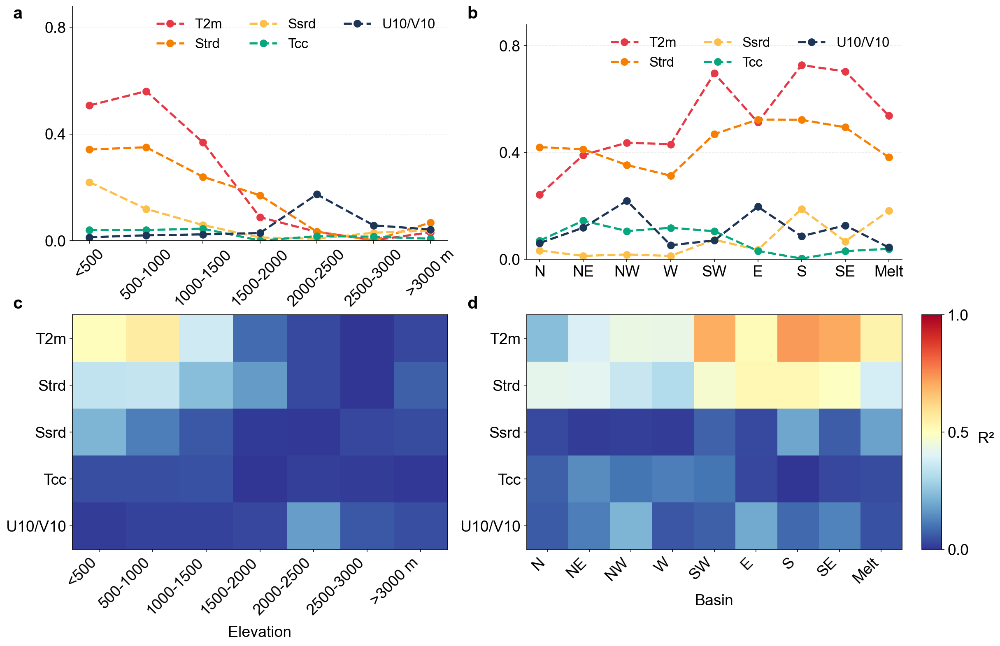


✓ 四子图可视化已生成：r2_four_panels.png


In [18]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# =========================
# 数据准备
# =========================
elev_bins = ["<500", "500-1000", "1000-1500", "1500-2000", "2000-2500", "2500-3000", ">3000 m"]
elev_r2 = {
    "T2m": [0.5067, 0.5605, 0.3679, 0.0876, 0.0327, 0.0012, 0.0306],
    "Strd": [0.3416, 0.3501, 0.2391, 0.1697, 0.0335, 0.0010, 0.0673],
    "Ssrd": [0.2194, 0.1188, 0.0579, 0.0116, 0.0067, 0.0294, 0.0378],
    "Tcc": [0.0398, 0.0396, 0.0444, 0.0001, 0.0163, 0.0145, 0.0068],
    "u10": [0.0124, 0.0197, 0.0070, 0.0078, 0.1734, 0.0288, 0.0414],
    "v10": [0.0051, 0.0007, 0.0232, 0.0281, 0.0262, 0.0571, 0.0241],
}
df_elev = pd.DataFrame(elev_r2, index=elev_bins)
df_elev["U10/V10"] = np.maximum(df_elev["u10"].values, df_elev["v10"].values)

# 流域重新排序：N NE NW E W SW S SE Melt
basins_new_order = ["N", "NE", "NW", "W", "SW","E", "S", "SE", "Melt"]
basin_r2_original = {
    "N": {"T2m": 0.2411, "Strd": 0.4201, "Ssrd": 0.0321, "Tcc": 0.0691, "u10": 0.0298, "v10": 0.0600},
    "NE": {"T2m": 0.3907, "Strd": 0.4117, "Ssrd": 0.0120, "Tcc": 0.1441, "u10": 0.0067, "v10": 0.1178},
    "SE": {"T2m": 0.7040, "Strd": 0.4947, "Ssrd": 0.0664, "Tcc": 0.0297, "u10": 0.1265, "v10": 0.0097},
    "S": {"T2m": 0.7280, "Strd": 0.5224, "Ssrd": 0.1876, "Tcc": 0.0019, "u10": 0.0857, "v10": 0.0031},
    "SW": {"T2m": 0.6971, "Strd": 0.4691, "Ssrd": 0.0725, "Tcc": 0.1046, "u10": 0.0698, "v10": 0.0119},
    "E": {"T2m": 0.5131, "Strd": 0.5232, "Ssrd": 0.0346, "Tcc": 0.0307, "u10": 0.0147, "v10": 0.1964},
    "W": {"T2m": 0.4309, "Strd": 0.3130, "Ssrd": 0.0119, "Tcc": 0.1174, "u10": 0.0521, "v10": 0.0033},
    "NW": {"T2m": 0.4366, "Strd": 0.3528, "Ssrd": 0.0170, "Tcc": 0.1051, "u10": 0.1378, "v10": 0.2189},
    "Melt": {"T2m": 0.5384, "Strd": 0.3817, "Ssrd": 0.1809, "Tcc": 0.0384, "u10": 0.0436, "v10": 0.0072},
}
basin_r2_reordered = {var: [basin_r2_original[b][var] for b in basins_new_order] 
                      for var in ["T2m", "Strd", "Ssrd", "Tcc", "u10", "v10"]}
df_basin = pd.DataFrame(basin_r2_reordered, index=basins_new_order)
df_basin["U10/V10"] = np.maximum(df_basin["u10"].values, df_basin["v10"].values)

vars_main = ["T2m", "Strd", "Ssrd", "Tcc", "U10/V10"]

# =========================
# 四子图布局
# =========================
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 18

fig = plt.figure(figsize=(16, 10), dpi=150)

# 配色方案（NPJ风格）
colors = {
    "T2m": "#E63946",      # 红色
    "Strd": "#F77F00",     # 橙色
    "Ssrd": "#FCBF49",     # 黄色
    "Tcc": "#06A77D",      # 青色
    "U10/V10": "#1D3557"   # 深蓝
}

# 手动设置子图位置 [left, bottom, width, height]
# 左列
ax1 = fig.add_axes([0.08, 0.58, 0.38, 0.38])  # a
ax3 = fig.add_axes([0.08, 0.08, 0.38, 0.38])  # c

# 右列 - 与左列对齐
ax2 = fig.add_axes([0.54, 0.55, 0.38, 0.38])  # b
ax4 = fig.add_axes([0.54, 0.08, 0.38, 0.38])  # d

# --- (a) Elevation 折线图 ---
x = np.arange(len(df_elev.index))
for v in vars_main:
    ax1.plot(x, df_elev[v].values, marker="o", linewidth=2.5, linestyle="--", 
             markersize=8, label=v, color=colors[v])
ax1.set_xticks(x)
ax1.set_xticklabels(df_elev.index, rotation=45, fontsize=18)
ax1.set_yticks([0.0, 0.4, 0.8])
ax1.set_yticklabels(["0.0", "0.4", "0.8"], fontsize=18)
ax1.set_ylim(0, 0.88)
ax1.set_xlim(-0.3, len(x)-0.7)
ax1.grid(True, axis="y", alpha=0.25, linestyle="--")
ax1.legend(ncol=3, frameon=False, loc="upper right", fontsize=16)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- (b) Basins 折线图 ---
x = np.arange(len(df_basin.index))
for v in vars_main:
    ax2.plot(x, df_basin[v].values, marker="o", linewidth=2.5, linestyle="--", 
             markersize=8, label=v, color=colors[v])
ax2.set_xticks(x)
ax2.set_xticklabels(df_basin.index, rotation=0, fontsize=18)
ax2.set_yticks([0.0, 0.4, 0.8])
ax2.set_yticklabels(["0.0", "0.4", "0.8"], fontsize=18)
ax2.set_ylim(0, 0.88)
ax2.set_xlim(-0.3, len(x)-0.7)
ax2.grid(True, axis="y", alpha=0.25, linestyle="--")
ax2.legend(ncol=3, frameon=False, loc="upper right", fontsize=16)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# --- (c) Elevation 热图 ---
elev_matrix = df_elev[vars_main].T.values
im1 = ax3.imshow(elev_matrix, cmap="RdYlBu_r", aspect="auto", vmin=0, vmax=1.0)
ax3.set_xticks(np.arange(len(df_elev.index)))
ax3.set_xticklabels(df_elev.index, rotation=45, ha="right", fontsize=18)
ax3.set_yticks(np.arange(len(vars_main)))
ax3.set_yticklabels(vars_main, fontsize=18)
ax3.set_xlabel("Elevation", fontsize=18, labelpad=10)

# --- (d) Basin 热图 ---
basin_matrix = df_basin[vars_main].T.values
im2 = ax4.imshow(basin_matrix, cmap="RdYlBu_r", aspect="auto", vmin=0, vmax=1.0)
ax4.set_xticks(np.arange(len(df_basin.index)))
ax4.set_xticklabels(df_basin.index, rotation=45, ha="right", fontsize=18)
ax4.set_yticks(np.arange(len(vars_main)))
ax4.set_yticklabels(vars_main, fontsize=18)
ax4.set_xlabel("Basin", fontsize=18, labelpad=10)

# 添加colorbar (在d图右侧)
cbar_ax = fig.add_axes([0.94, 0.08, 0.02, 0.38])  # [left, bottom, width, height]
cbar = fig.colorbar(im2, cax=cbar_ax, ticks=[0, 0.5, 1.0])
cbar.set_label("R²", fontsize=18, rotation=0, labelpad=20)
cbar.ax.tick_params(labelsize=18)

# 添加面板标签 (在子图外部左上角)
fig.text(0.02, 0.96, "a", fontsize=20, weight="bold", va="top", ha="left")
fig.text(0.48, 0.96, "b", fontsize=20, weight="bold", va="top", ha="left")
fig.text(0.02, 0.49, "c", fontsize=20, weight="bold", va="top", ha="left")
fig.text(0.48, 0.49, "d", fontsize=20, weight="bold", va="top", ha="left")

plt.savefig("r2_four_panels.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n✓ 四子图可视化已生成：r2_four_panels.png")

C:\Users\11823\AppData\Local\Temp\ipykernel_55244\2980297377.py:168: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 0.98])


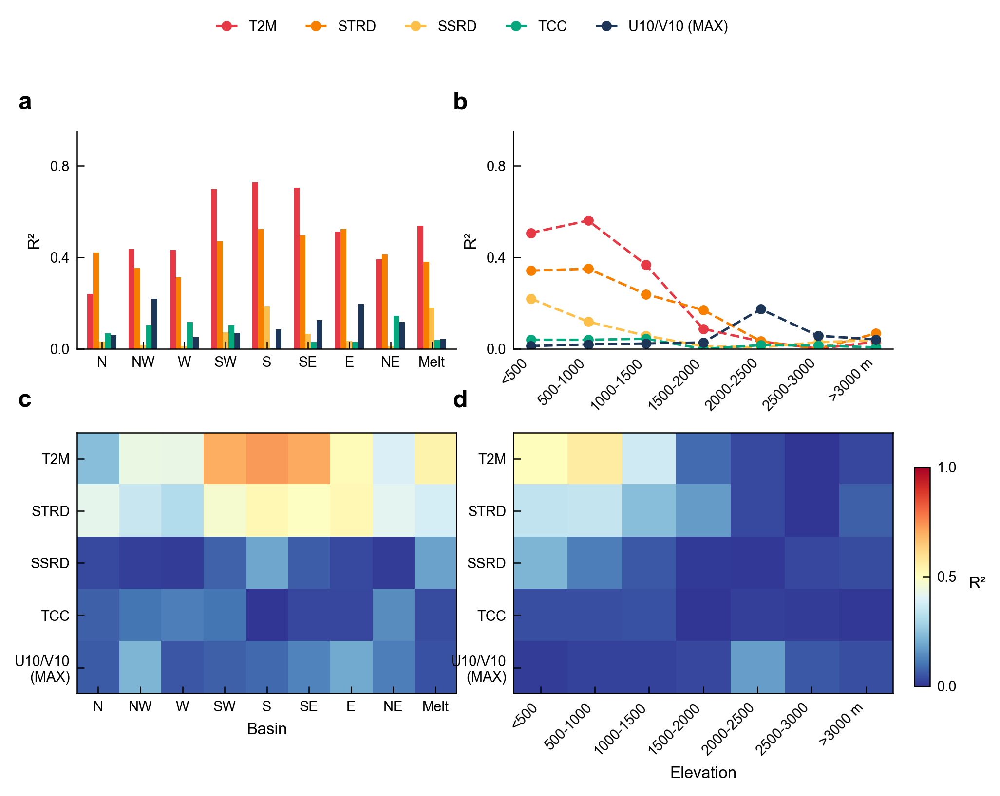


✓ 严格出版级绘图已生成：r2_panels_npj_style.pdf / .png


In [2]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# =========================
# 1. 全局出版级格式设置 (Nature/NPJ 标准)
# =========================
plt.rcParams.update({
    "font.family": "Arial",          # 无衬线字体
    "font.size": 8,                  # 基准字号
    "axes.labelsize": 8,             # 轴标签 8pt
    "xtick.labelsize": 7,            # 刻度值 7pt
    "ytick.labelsize": 7,            # 刻度值 7pt
    "legend.fontsize": 7,            # 图例 7pt
    "axes.linewidth": 0.6,           # 轴线宽 0.6pt (介于0.5-0.75之间)
    "xtick.major.width": 0.6,        # 刻度线宽
    "ytick.major.width": 0.6,
    "xtick.direction": "in",         # 刻度向内
    "ytick.direction": "in",
    "xtick.top": False,              # 顶部无刻度
    "ytick.right": False,            # 右侧无刻度
})

# =========================
# 2. 数据准备与重构
# =========================
elev_bins = ["<500", "500-1000", "1000-1500", "1500-2000", "2000-2500", "2500-3000", ">3000 m"]
elev_r2 = {
    "T2M": [0.5067, 0.5605, 0.3679, 0.0876, 0.0327, 0.0012, 0.0306],
    "STRD": [0.3416, 0.3501, 0.2391, 0.1697, 0.0335, 0.0010, 0.0673],
    "SSRD": [0.2194, 0.1188, 0.0579, 0.0116, 0.0067, 0.0294, 0.0378],
    "TCC": [0.0398, 0.0396, 0.0444, 0.0001, 0.0163, 0.0145, 0.0068],
    "U10": [0.0124, 0.0197, 0.0070, 0.0078, 0.1734, 0.0288, 0.0414],
    "V10": [0.0051, 0.0007, 0.0232, 0.0281, 0.0262, 0.0571, 0.0241],
}
df_elev = pd.DataFrame(elev_r2, index=elev_bins)
# 变量名全大写，过长则换行
df_elev["U10/V10\n(MAX)"] = np.maximum(df_elev["U10"].values, df_elev["V10"].values)

# 流域按要求重新排序
basins_new_order = ["N", "NW", "W", "SW", "S", "SE", "E", "NE", "Melt"]
basin_r2_original = {
    "N": {"T2M": 0.2411, "STRD": 0.4201, "SSRD": 0.0321, "TCC": 0.0691, "U10": 0.0298, "V10": 0.0600},
    "NE": {"T2M": 0.3907, "STRD": 0.4117, "SSRD": 0.0120, "TCC": 0.1441, "U10": 0.0067, "V10": 0.1178},
    "SE": {"T2M": 0.7040, "STRD": 0.4947, "SSRD": 0.0664, "TCC": 0.0297, "U10": 0.1265, "V10": 0.0097},
    "S": {"T2M": 0.7280, "STRD": 0.5224, "SSRD": 0.1876, "TCC": 0.0019, "U10": 0.0857, "V10": 0.0031},
    "SW": {"T2M": 0.6971, "STRD": 0.4691, "SSRD": 0.0725, "TCC": 0.1046, "U10": 0.0698, "V10": 0.0119},
    "E": {"T2M": 0.5131, "STRD": 0.5232, "SSRD": 0.0346, "TCC": 0.0307, "U10": 0.0147, "V10": 0.1964},
    "W": {"T2M": 0.4309, "STRD": 0.3130, "SSRD": 0.0119, "TCC": 0.1174, "U10": 0.0521, "V10": 0.0033},
    "NW": {"T2M": 0.4366, "STRD": 0.3528, "SSRD": 0.0170, "TCC": 0.1051, "U10": 0.1378, "V10": 0.2189},
    "Melt": {"T2M": 0.5384, "STRD": 0.3817, "SSRD": 0.1809, "TCC": 0.0384, "U10": 0.0436, "V10": 0.0072},
}

basin_r2_reordered = {var: [basin_r2_original[b][var] for b in basins_new_order] 
                      for var in ["T2M", "STRD", "SSRD", "TCC", "U10", "V10"]}
df_basin = pd.DataFrame(basin_r2_reordered, index=basins_new_order)
df_basin["U10/V10\n(MAX)"] = np.maximum(df_basin["U10"].values, df_basin["V10"].values)

vars_main = ["T2M", "STRD", "SSRD", "TCC", "U10/V10\n(MAX)"]

# =========================
# 3. 画布与布局 (双栏 183mm)
# =========================
# 183mm 约等于 7.2 英寸，设置合适的高宽比
fig_width_in = 183 / 25.4 
fig_height_in = 5.0
fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)

colors = {
    "T2M": "#E63946",       
    "STRD": "#F77F00",      
    "SSRD": "#FCBF49",      
    "TCC": "#06A77D",       
    "U10/V10\n(MAX)": "#1D3557"  
}

# 使用 GridSpec 实现精确对齐的紧凑布局
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1.2], 
                       wspace=0.15, hspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])  # a: Basin (Bar)
ax2 = fig.add_subplot(gs[0, 1])  # b: Elevation (Line)
ax3 = fig.add_subplot(gs[1, 0])  # c: Basin (Heatmap)
ax4 = fig.add_subplot(gs[1, 1])  # d: Elevation (Heatmap)

# 统一移除上方和右侧的边框线 (经典学术图表风格)
for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --- (a) Basin 簇状柱形图 ---
x_basin = np.arange(len(df_basin.index))
n_vars = len(vars_main)
bar_width = 0.14
offsets = np.linspace(-bar_width * (n_vars - 1) / 2, bar_width * (n_vars - 1) / 2, n_vars)

for i, v in enumerate(vars_main):
    ax1.bar(x_basin + offsets[i], df_basin[v].values, width=bar_width, 
            label=v if i < len(vars_main) else "", color=colors[v], 
            edgecolor='none') # 去除柱子边框更清爽

ax1.set_xticks(x_basin)
ax1.set_xticklabels(df_basin.index, rotation=0)
ax1.set_yticks([0.0, 0.4, 0.8])
ax1.set_ylim(0, 0.95)
ax1.set_xlim(-0.6, len(x_basin)-0.4)
ax1.set_ylabel("R²")

# --- (b) Elevation 折线图 (恢复为原要求) ---
x_elev = np.arange(len(df_elev.index))
for v in vars_main:
    ax2.plot(x_elev, df_elev[v].values, marker="o", linewidth=1.2, linestyle="--", 
             markersize=4, label=v, color=colors[v])

ax2.set_xticks(x_elev)
ax2.set_xticklabels(df_elev.index, rotation=45, ha="right")
ax2.set_yticks([0.0, 0.4, 0.8])
ax2.set_ylim(0, 0.95)
ax2.set_xlim(-0.3, len(x_elev)-0.7)
ax2.set_ylabel("R²")

# 提取唯一的图例放在图的顶部中央 (节省子图内部空间)
handles, labels = ax2.get_legend_handles_labels()
# 由于 U10/V10(MAX) 包含换行符，在水平图例中替换为空格以节省高度
labels_flat = [l.replace('\n', ' ') for l in labels]
fig.legend(handles, labels_flat, loc='upper center', bbox_to_anchor=(0.5, 1.05),
           ncol=5, frameon=False, fontsize=7, handlelength=1.5)

# --- (c) Basin 热图 ---
basin_matrix = df_basin[vars_main].T.values
im1 = ax3.imshow(basin_matrix, cmap="RdYlBu_r", aspect="auto", vmin=0, vmax=1.0)
ax3.set_xticks(np.arange(len(df_basin.index)))
ax3.set_xticklabels(df_basin.index, rotation=0)
ax3.set_yticks(np.arange(len(vars_main)))
ax3.set_yticklabels(vars_main)
ax3.set_xlabel("Basin")

# --- (d) Elevation 热图 ---
elev_matrix = df_elev[vars_main].T.values
im2 = ax4.imshow(elev_matrix, cmap="RdYlBu_r", aspect="auto", vmin=0, vmax=1.0)
ax4.set_xticks(np.arange(len(df_elev.index)))
ax4.set_xticklabels(df_elev.index, rotation=45, ha="right")
ax4.set_yticks(np.arange(len(vars_main)))
ax4.set_yticklabels(vars_main)
ax4.set_xlabel("Elevation")

# 添加统一的 Colorbar
cbar_ax = fig.add_axes([0.92, 0.12, 0.015, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im2, cax=cbar_ax, ticks=[0, 0.5, 1.0])
cbar.set_label("R²", rotation=0, labelpad=10)
cbar.outline.set_linewidth(0.6) # Colorbar 边框线宽也保持一致

# =========================
# 4. 子图标签 (12pt, 无衬线加粗)
# =========================
labels_panels = ["a", "b", "c", "d"]
axes_list = [ax1, ax2, ax3, ax4]
for ax, label in zip(axes_list, labels_panels):
    # 锚点定在子图坐标系的左上角偏外侧，确保不对齐产生遮挡
    ax.text(-0.12, 1.08, label, transform=ax.transAxes,
            fontsize=12, fontweight="bold", fontfamily="Arial",
            va="bottom", ha="right")

# 启用 tight_layout 自动处理边缘与重叠
# rect=[left, bottom, right, top] 留出顶部图例和右侧 colorbar 的空间
plt.tight_layout(rect=[0, 0, 0.9, 0.98]) 

# 保存为支持矢量编辑的高清 PDF 和 PNG
plt.savefig("r2_panels_npj_style.pdf", format="pdf", bbox_inches="tight")
plt.savefig("r2_panels_npj_style.png", dpi=300, bbox_inches="tight")
plt.show()

print("\n✓ 严格出版级绘图已生成：r2_panels_npj_style.pdf / .png")

C:\Users\11823\AppData\Local\Temp\ipykernel_36156\3616935035.py:219: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.



✓ 成功生成正文 Fig2：
  PDF: C:\Users\11823\era5land\Fig2.pdf
  EPS: C:\Users\11823\era5land\Fig2.eps


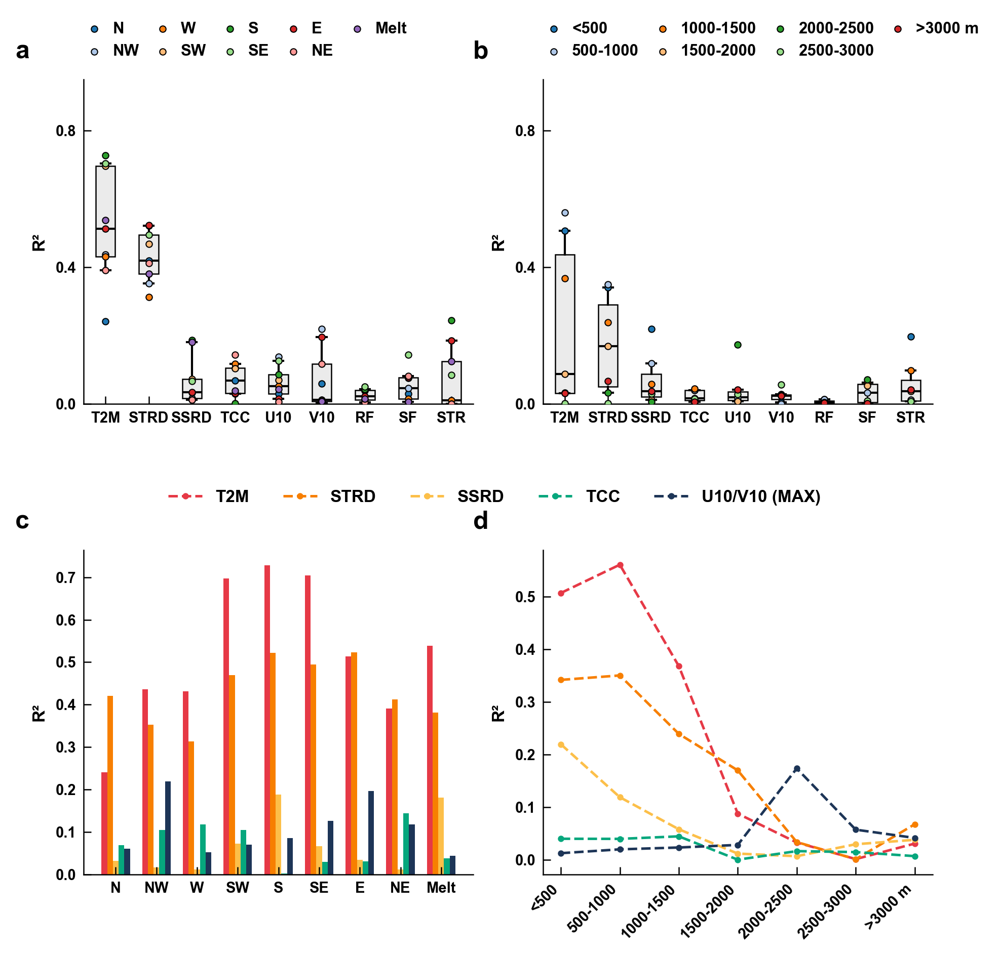

In [11]:
# -*- coding: utf-8 -*-
import re, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# =========================
# 1. 全局出版级格式设置 (NPJ 标准)
# =========================
plt.rcParams.update({
    "font.family": "Arial",          
    "font.size": 8,                  
    "axes.labelsize": 8,             
    "xtick.labelsize": 7,            
    "ytick.labelsize": 7,            
    "legend.fontsize": 8,            # 统一调大1号 (原为7/6.5)
    "axes.linewidth": 0.6,           
    "xtick.major.width": 0.6,        
    "ytick.major.width": 0.6,
    "xtick.direction": "in",         
    "ytick.direction": "in",
    "xtick.top": False,              
    "ytick.right": False,
    "font.weight": "bold",           
    "axes.labelweight": "bold",      
    "axes.titleweight": "bold",      
})

# =========================
# 2. 路径与基础配置
# =========================
TXT_PATH = r"C:\Users\11823\Desktop\regression_output.txt"
OUT_DIR  = r"C:\Users\11823\era5land"  # 已更新路径

if not os.path.exists(OUT_DIR):
    os.makedirs(OUT_DIR)

DROP_VARS = {"sp", "slhf", "tp"}
PRIORITY = ["t2m", "strd", "ssrd", "tcc", "u10", "v10"]
BOTTOM_VARS = ["T2M", "STRD", "SSRD", "TCC", "U10/V10\n(MAX)"]
BASIN_ORDER = ["N", "NW", "W", "SW", "S", "SE", "E", "NE", "Melt"]
ALTITUDE_ORDER = ["0-500m", "500-1000m", "1000-1500m", "1500-2000m", 
                  "2000-2500m", "2500-3000m", "3000m+"]
ALTITUDE_LABELS = ["<500", "500-1000", "1000-1500", "1500-2000", 
                   "2000-2500", "2500-3000", ">3000 m"]
PALETTE = "tab20"

# =========================
# 3. 解析 txt 与 变量排序 (保持逻辑不变)
# =========================
def parse_univariate_blocks(txt: str):
    block_pat = re.compile(
        r"^\[(?P<kind>Altitude|Basin)\s+(?P<group>[^\]]+)\]\s+---\s+Univariate\s*\n"
        r"^变量\s*\|\s*slope\s*\|\s*R2\s*\|\s*r\s*\|\s*n\s*\n"
        r"(?P<body>(?:.*\n)*?)(?=^\[|\Z|^=+|^-{5,})",
        flags=re.MULTILINE
    )
    row_pat = re.compile(
        r"^\s*(?P<var>\S+)\s*\|\s*(?P<slope>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<R2>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<r>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<n>\d[\d,]*)\s*$",
        flags=re.MULTILINE
    )
    rows = []
    for bm in block_pat.finditer(txt):
        kind = bm.group("kind")
        group = bm.group("group")
        for rm in row_pat.finditer(bm.group("body")):
            rows.append({
                "kind": kind, "group": group,
                "var": rm.group("var"), "R2": float(rm.group("R2"))
            })
    df = pd.DataFrame(rows)
    return df[df.kind=="Altitude"], df[df.kind=="Basin"]

def build_var_order(df):
    d = df.copy()
    d["var_l"] = d["var"].str.lower()
    d = d[~d["var_l"].isin(DROP_VARS)]
    allv = list(pd.unique(d["var_l"]))
    ordered = [v for v in PRIORITY if v in allv]
    ordered += sorted(v for v in allv if v not in ordered)
    return ordered

def format_altitude_label(g):
    g = g.lower().replace(" ", "")
    if g.endswith("m+"): return f">{g.replace('m+','')} m"
    a, b = g.replace("m","").split("-")
    return f"<{b}" if a=="0" else f"{a}-{b}"

# =========================
# 4. 底部图表固定数据
# =========================
elev_r2 = {
    "T2M": [0.5067, 0.5605, 0.3679, 0.0876, 0.0327, 0.0012, 0.0306],
    "STRD": [0.3416, 0.3501, 0.2391, 0.1697, 0.0335, 0.0010, 0.0673],
    "SSRD": [0.2194, 0.1188, 0.0579, 0.0116, 0.0067, 0.0294, 0.0378],
    "TCC": [0.0398, 0.0396, 0.0444, 0.0001, 0.0163, 0.0145, 0.0068],
    "U10": [0.0124, 0.0197, 0.0070, 0.0078, 0.1734, 0.0288, 0.0414],
    "V10": [0.0051, 0.0007, 0.0232, 0.0281, 0.0262, 0.0571, 0.0241],
}
df_elev = pd.DataFrame(elev_r2, index=ALTITUDE_LABELS)
df_elev["U10/V10\n(MAX)"] = np.maximum(df_elev["U10"].values, df_elev["V10"].values)

basin_r2_original = {
    "N": {"T2M": 0.2411, "STRD": 0.4201, "SSRD": 0.0321, "TCC": 0.0691, "U10": 0.0298, "V10": 0.0600},
    "NE": {"T2M": 0.3907, "STRD": 0.4117, "SSRD": 0.0120, "TCC": 0.1441, "U10": 0.0067, "V10": 0.1178},
    "SE": {"T2M": 0.7040, "STRD": 0.4947, "SSRD": 0.0664, "TCC": 0.0297, "U10": 0.1265, "V10": 0.0097},
    "S": {"T2M": 0.7280, "STRD": 0.5224, "SSRD": 0.1876, "TCC": 0.0019, "U10": 0.0857, "V10": 0.0031},
    "SW": {"T2M": 0.6971, "STRD": 0.4691, "SSRD": 0.0725, "TCC": 0.1046, "U10": 0.0698, "V10": 0.0119},
    "E": {"T2M": 0.5131, "STRD": 0.5232, "SSRD": 0.0346, "TCC": 0.0307, "U10": 0.0147, "V10": 0.1964},
    "W": {"T2M": 0.4309, "STRD": 0.3130, "SSRD": 0.0119, "TCC": 0.1174, "U10": 0.0521, "V10": 0.0033},
    "NW": {"T2M": 0.4366, "STRD": 0.3528, "SSRD": 0.0170, "TCC": 0.1051, "U10": 0.1378, "V10": 0.2189},
    "Melt": {"T2M": 0.5384, "STRD": 0.3817, "SSRD": 0.1809, "TCC": 0.0384, "U10": 0.0436, "V10": 0.0072},
}
basin_r2_reordered = {var: [basin_r2_original[b][var] for b in BASIN_ORDER] for var in ["T2M", "STRD", "SSRD", "TCC", "U10", "V10"]}
df_basin = pd.DataFrame(basin_r2_reordered, index=BASIN_ORDER)
df_basin["U10/V10\n(MAX)"] = np.maximum(df_basin["U10"].values, df_basin["V10"].values)

colors_bottom = {"T2M": "#E63946", "STRD": "#F77F00", "SSRD": "#FCBF49", "TCC": "#06A77D", "U10/V10\n(MAX)": "#1D3557"}

# =========================
# 5. 画图辅助函数
# =========================
def set_tick_bold(ax):
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

def draw_boxplot_panel(ax, df, kind, var_order, legend_label_func=None):
    if df.empty: return
    d = df.copy()
    d["var_l"] = d["var"].str.lower()
    d = d[~d["var_l"].isin(DROP_VARS)]
    d = d[d["var_l"].isin(var_order)]
    groups = ALTITUDE_ORDER if kind=="Altitude" else BASIN_ORDER
    groups = [g for g in groups if g in d.group.unique()]
    cmap = plt.get_cmap(PALETTE)
    g2c = {g: cmap(i % cmap.N) for i,g in enumerate(groups)}
    data = [d[d.var_l==v].R2.values for v in var_order]
    bp = ax.boxplot(data, whis=(5,95), widths=0.45, patch_artist=True, showfliers=False)
    for b in bp["boxes"]: b.set(facecolor=(0,0,0,0.08), edgecolor="black", linewidth=0.6)
    for m in bp["medians"]: m.set(color="black", linewidth=1.0)
    xs = np.arange(1, len(var_order)+1)
    for g in groups:
        sg = d[d.group==g]
        for i,v in enumerate(var_order):
            vv = sg[sg.var_l==v].R2
            if len(vv):
                ax.scatter(xs[i], vv.iloc[0], s=9, color=g2c[g], edgecolors="black", linewidths=0.5, label=g, zorder=3)
    ax.set_xticks(xs)
    ax.set_xticklabels([v.upper() for v in var_order], fontweight="bold")
    ax.set_yticks([0, 0.4, 0.8])
    ax.set_ylim(0, 0.95)
    ax.set_ylabel("R²", fontweight="bold")
    set_tick_bold(ax)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels, handles))
    labels, handles = list(uniq.keys()), list(uniq.values())
    if legend_label_func: labels = [legend_label_func(l) for l in labels]
    ncol_calc = (len(labels) + 1) // 2 
    ax.legend(handles, labels, frameon=False, loc="lower left", bbox_to_anchor=(-0.05, 1.02),
              ncol=ncol_calc, fontsize=7.5, handletextpad=0.15, columnspacing=0.5,
              prop={"weight": "bold", "size": 7.5}) # 放大1号

# =========================
# 6. 主绘制逻辑
# =========================
def main():
    alt_df, bas_df = pd.DataFrame(), pd.DataFrame()
    box_vars = PRIORITY
    if os.path.exists(TXT_PATH):
        with open(TXT_PATH, "r", encoding="utf-8", errors="ignore") as f:
            txt = f.read()
        alt_df, bas_df = parse_univariate_blocks(txt)
        if not alt_df.empty or not bas_df.empty:
            box_vars = build_var_order(pd.concat([alt_df, bas_df]))

    fig_width_in, fig_height_in = 183 / 25.4, 6.8 
    fig = plt.figure(figsize=(fig_width_in, fig_height_in), dpi=300)
    gs = gridspec.GridSpec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1], wspace=0.18, hspace=0.45) 

    ax1, ax2, ax3, ax4 = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(2)]
    for ax in [ax1, ax2, ax3, ax4]:
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

    draw_boxplot_panel(ax1, bas_df, "Basin", box_vars)
    draw_boxplot_panel(ax2, alt_df, "Altitude", box_vars, legend_label_func=format_altitude_label)

    # (c) Basin Bar Chart
    x_basin = np.arange(len(df_basin.index))
    bar_width = 0.14
    offsets = np.linspace(-bar_width * 2, bar_width * 2, 5)
    for i, v in enumerate(BOTTOM_VARS):
        ax3.bar(x_basin + offsets[i], df_basin[v].values, width=bar_width, label=v, color=colors_bottom[v])
    ax3.set_xticks(x_basin)
    ax3.set_xticklabels(df_basin.index, fontweight="bold")
    ax3.set_ylabel("R²", fontweight="bold")
    set_tick_bold(ax3)

    # (d) Elevation Line Chart
    x_elev = np.arange(len(df_elev.index))
    for v in BOTTOM_VARS:
        ax4.plot(x_elev, df_elev[v].values, marker="o", linewidth=1.2, linestyle="--", markersize=2, label=v, color=colors_bottom[v])
    ax4.set_xticks(x_elev)
    ax4.set_xticklabels(df_elev.index, rotation=45, ha="right", fontweight="bold")
    ax4.set_ylabel("R²", fontweight="bold")
    set_tick_bold(ax4)

    # Shared legend for c, d - 放大至 8pt
    handles, labels = ax4.get_legend_handles_labels()
    fig.legend(handles, [l.replace('\n', ' ') for l in labels], loc='center', bbox_to_anchor=(0.5, 0.475),
               ncol=5, frameon=False, prop={"weight": "bold", "size": 8})

    for ax, label in zip([ax1, ax2, ax3, ax4], ["a", "b", "c", "d"]):
        ax.text(-0.14, 1.05, label, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom", ha="right")

    plt.tight_layout()
    
    # 保存为 Fig2.pdf 和 Fig2.eps
    pdf_path = os.path.join(OUT_DIR, "Fig2.pdf")
    eps_path = os.path.join(OUT_DIR, "Fig2.eps")
    fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
    fig.savefig(eps_path, format="eps", bbox_inches="tight")
    
    print(f"\n✓ 成功生成正文 Fig2：")
    print(f"  PDF: {pdf_path}")
    print(f"  EPS: {eps_path}")
    plt.show()

if __name__ == "__main__":
    main()

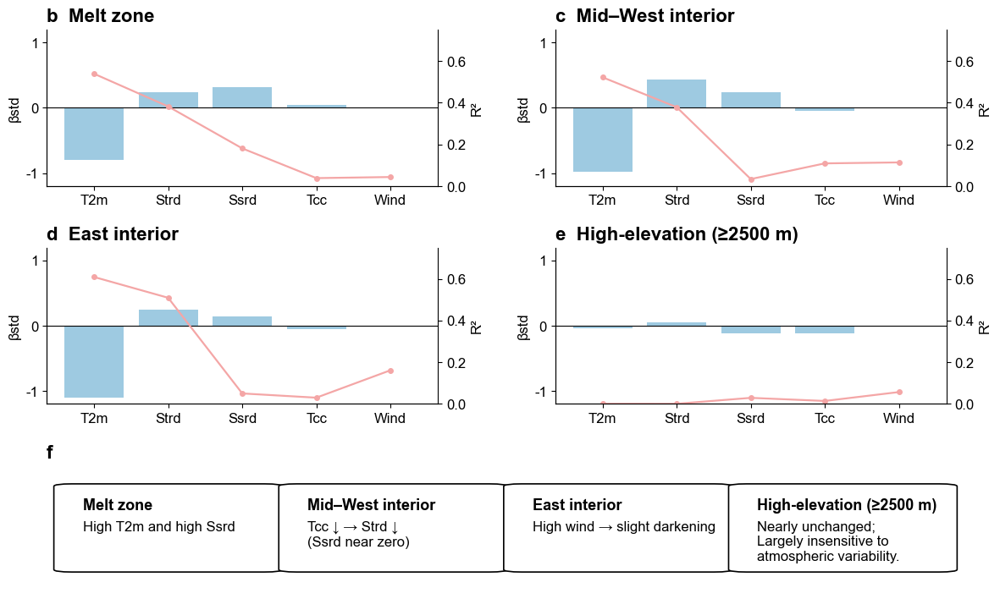

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import FancyBboxPatch

# ===================== Style (统一 Arial) =====================
rcParams["font.family"] = "Arial"
rcParams["font.size"] = 12
rcParams["axes.unicode_minus"] = False  # 负号正常显示

BAR_COLOR  = "#9ecae1"   # light blue
LINE_COLOR = "#f4a6a6"   # pale red

VARS  = ["t2m", "strd", "ssrd", "tcc", "wind"]
XLABS = ["T2m", "Strd", "Ssrd", "Tcc", "Wind"]

def wind_r2_proxy(u10_r2, v10_r2):
    return max(float(u10_r2), float(v10_r2))

def mean_dict(dicts, keys):
    out = {}
    for k in keys:
        out[k] = float(np.mean([d.get(k, 0.0) for d in dicts]))
    return out

# ===================== Basin-level inputs (from your outputs) =====================
basin_melt = dict(
    beta={"t2m": -0.7961, "strd": 0.2365, "ssrd": 0.3225, "tcc": 0.0492},
    r2={"t2m": 0.5384, "strd": 0.3817, "ssrd": 0.1809, "tcc": 0.0384,
        "wind": wind_r2_proxy(0.0436, 0.0072)}
)

basin_sw = dict(
    beta={"t2m": -1.1090, "strd": 0.4647, "ssrd": 0.2366, "tcc": 0.0075},
    r2={"t2m": 0.6971, "strd": 0.4691, "ssrd": 0.0725, "tcc": 0.1046,
        "wind": wind_r2_proxy(0.0698, 0.0119)}
)

basin_w = dict(
    beta={"t2m": -0.7893, "strd": 0.3836, "ssrd": 0.2379, "tcc": -0.0322},
    r2={"t2m": 0.4309, "strd": 0.3130, "ssrd": 0.0119, "tcc": 0.1174,
        "wind": wind_r2_proxy(0.0521, 0.0033)}
)

basin_nw = dict(
    beta={"t2m": -1.0514, "strd": 0.4374, "ssrd": 0.2458, "tcc": -0.1167},
    r2={"t2m": 0.4366, "strd": 0.3528, "ssrd": 0.0170, "tcc": 0.1051,
        "wind": wind_r2_proxy(0.1378, 0.2189)}
)

basin_e = dict(
    beta={"t2m": -1.0085, "strd": 0.1179, "ssrd": 0.1170, "tcc": -0.0585},
    r2={"t2m": 0.5131, "strd": 0.5232, "ssrd": 0.0346, "tcc": 0.0307,
        "wind": wind_r2_proxy(0.0147, 0.1964)}
)

basin_se = dict(
    beta={"t2m": -1.1878, "strd": 0.3872, "ssrd": 0.1744, "tcc": -0.0431},
    r2={"t2m": 0.7040, "strd": 0.4947, "ssrd": 0.0664, "tcc": 0.0297,
        "wind": wind_r2_proxy(0.1265, 0.0097)}
)

high_elev = dict(
    beta={"t2m": -0.0417, "strd": 0.0461, "ssrd": -0.1190, "tcc": -0.1152},
    r2={"t2m": 0.0012, "strd": 0.0010, "ssrd": 0.0294, "tcc": 0.0145,
        "wind": wind_r2_proxy(0.0288, 0.0571)}
)

# ===================== Regime aggregation =====================
melt = dict(
    letter="b", title="Melt zone",
    beta=basin_melt["beta"], r2=basin_melt["r2"]
)

midwest = dict(
    letter="c", title="Mid–West interior",
    beta=mean_dict([basin_sw["beta"], basin_w["beta"], basin_nw["beta"]], ["t2m","strd","ssrd","tcc"]),
    r2=mean_dict([basin_sw["r2"], basin_w["r2"], basin_nw["r2"]], ["t2m","strd","ssrd","tcc","wind"])
)

eastint = dict(
    letter="d", title="East interior",
    beta=mean_dict([basin_e["beta"], basin_se["beta"]], ["t2m","strd","ssrd","tcc"]),
    r2=mean_dict([basin_e["r2"], basin_se["r2"]], ["t2m","strd","ssrd","tcc","wind"])
)

highelev_reg = dict(
    letter="e", title="High-elevation (≥2500 m)",
    beta=high_elev["beta"], r2=high_elev["r2"]
)

REGIMES = [melt, midwest, eastint, highelev_reg]

# ===================== Plot helpers =====================
BETA_YLIM = 1.2
BETA_YTICKS = [-1, 0, 1]

# 标题 bcdef 放大 2 号：原来 14 -> 16
PANEL_TITLE_FS = 16

def plot_panel(ax, reg):
    beta_vals = [float(reg["beta"].get(k, 0.0)) if k != "wind" else 0.0 for k in VARS]
    r2_vals   = [float(reg["r2"].get(k, 0.0)) for k in VARS]
    beta_vals = np.array(beta_vals)
    r2_vals   = np.array(r2_vals)

    x = np.arange(len(VARS))

    ax.bar(x, beta_vals, color=BAR_COLOR, edgecolor="none")
    ax.axhline(0, linewidth=0.8, color="black")
    ax.set_xticks(x)
    ax.set_xticklabels(XLABS)
    ax.set_ylabel("βstd")

    # 统一 βstd y轴：范围 + 刻度
    ax.set_ylim(-BETA_YLIM, BETA_YLIM)
    ax.set_yticks(BETA_YTICKS)

    ax2 = ax.twinx()
    ax2.plot(x, r2_vals, color=LINE_COLOR, marker="o", linewidth=1.6, markersize=4)
    ax2.set_ylabel("R²")
    ax2.set_ylim(0, max(0.75, float(np.nanmax(r2_vals) * 1.10)))

    ax.text(0.0, 1.03, f"{reg['letter']}  {reg['title']}",
            transform=ax.transAxes, ha="left", va="bottom",
            fontweight="bold", fontsize=PANEL_TITLE_FS)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax2.spines["top"].set_visible(False)

def draw_rules_boxes(ax):
    ax.set_axis_off()

    titles = ["Melt zone", "Mid–West interior", "East interior", "High-elevation (≥2500 m)"]
    lines = [
        "High T2m and high Ssrd",
        "Tcc ↓ → Strd ↓\n(Ssrd near zero)",
        "High wind → slight darkening",
        "Nearly unchanged;\nLargely insensitive to \natmospheric variability.",
    ]

    title_fs = 13
    body_fs  = 12

    left, bottom, w, h, gap = 0.02, 0.16, 0.23, 0.68, 0.02
    for i in range(4):
        x0 = left + i * (w + gap)

        # 修复：最后一个框右边“没闭合” -> 明确 joinstyle/capstyle，并确保完整描边
        rect = FancyBboxPatch(
            (x0, bottom), w, h,
            boxstyle="round,pad=0.012,rounding_size=0.02",
            edgecolor="black", facecolor="white",
            transform=ax.transAxes,
            linewidth=1.2,
            joinstyle="miter",
            capstyle="projecting",
            antialiased=True,
            clip_on=False,
            zorder=5
        )
        ax.add_patch(rect)

        ax.text(x0+0.02, bottom+h-0.10, titles[i],
                transform=ax.transAxes, fontsize=title_fs, fontweight="bold",
                ha="left", va="top", zorder=6)
        ax.text(x0+0.02, bottom+h-0.28, lines[i],
                transform=ax.transAxes, fontsize=body_fs,
                ha="left", va="top", zorder=6)

    # 可选兜底：给规则区整体再加一个外框（不影响四个小框），避免渲染器裁切造成“断线”
    outer = FancyBboxPatch(
        (0.01, 0.10), 0.98, 0.82,
        boxstyle="round,pad=0.0,rounding_size=0.02",
        edgecolor="none", facecolor="none",
        transform=ax.transAxes,
        linewidth=0.0,
        clip_on=False
    )
    ax.add_patch(outer)

# ===================== Layout =====================
fig = plt.figure(figsize=(12.5, 7.8))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.80], hspace=0.42, wspace=0.30)

axes = [
    fig.add_subplot(gs[0,0]),
    fig.add_subplot(gs[0,1]),
    fig.add_subplot(gs[1,0]),
    fig.add_subplot(gs[1,1]),
]
ax_rules = fig.add_subplot(gs[2,:])

for ax, reg in zip(axes, REGIMES):
    plot_panel(ax, reg)

draw_rules_boxes(ax_rules)

# 如果你想在 f 面板也加字母（标题放大同样 +2）
ax_rules.text(0.0, 1.03, "f",
              transform=ax_rules.transAxes, ha="left", va="bottom",
              fontweight="bold", fontsize=PANEL_TITLE_FS)

fig.subplots_adjust(left=0.08, right=0.93, top=0.93, bottom=0.08)
plt.show()


[OK] saved: C:\Users\11823\Desktop\advanced_box_points_allvars_univariate_R2.png


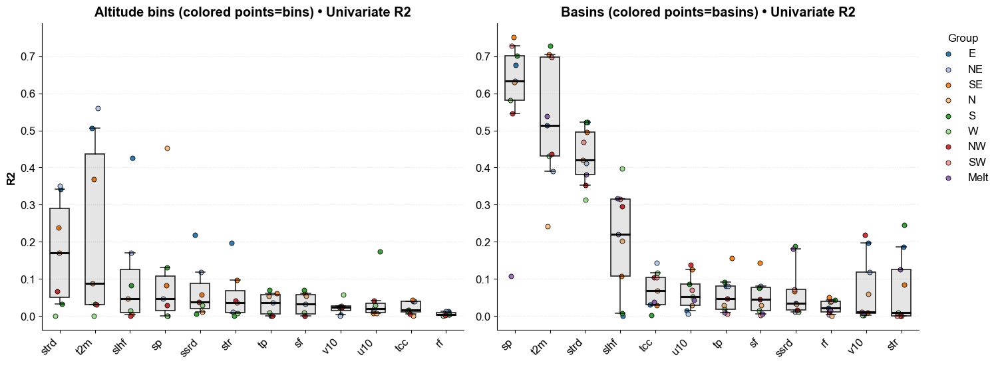

In [38]:
# -*- coding: utf-8 -*-
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TXT_PATH = r"C:\Users\11823\Desktop\regression_output.txt"
OUT_DIR  = r"C:\Users\11823\Desktop"

METRIC = "R2"          # "R2" 或 "r"
ABS_R  = False         # METRIC="r" 时要不要取绝对值
SORT_BY_MEDIAN = True  # 变量按 median(R2) 从大到小排序
PALETTE = "tab20"      # 多颜色

def parse_univariate_blocks(txt: str):
    block_pat = re.compile(
        r"^\[(?P<kind>Altitude|Basin)\s+(?P<group>[^\]]+)\]\s+---\s+Univariate\s*\n"
        r"^变量\s*\|\s*slope\s*\|\s*R2\s*\|\s*r\s*\|\s*n\s*\n"
        r"(?P<body>(?:.*\n)*?)(?=^\[|\Z|^=+|^-{5,})",
        flags=re.MULTILINE
    )
    row_pat = re.compile(
        r"^\s*(?P<var>\S+)\s*\|\s*(?P<slope>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<R2>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<r>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<n>\d[\d,]*)\s*$",
        flags=re.MULTILINE
    )

    rows = []
    for bm in block_pat.finditer(txt):
        kind = bm.group("kind").strip()
        group = bm.group("group").strip()
        body = bm.group("body")
        for rm in row_pat.finditer(body):
            rows.append({
                "kind": kind,
                "group": group,
                "var": rm.group("var").strip(),
                "slope": float(rm.group("slope")),
                "R2": float(rm.group("R2")),
                "r": float(rm.group("r")),
                "n": int(rm.group("n").replace(",", "")),
            })

    df = pd.DataFrame(rows)
    alt = df[df["kind"] == "Altitude"].copy()
    bas = df[df["kind"] == "Basin"].copy()
    return alt, bas

def box_with_colored_points(ax, df, metric="R2", title="", palette="tab20",
                            sort_by_median=True, abs_r=False):
    d = df.copy()
    d["var_l"] = d["var"].str.lower()

    if metric == "r" and abs_r:
        d["_metric"] = d["r"].abs()
        metric_use = "_metric"
    else:
        metric_use = metric

    # 变量排序：median 最大的在最左边（最“matter”）
    if sort_by_median:
        vars_all = list(d.groupby("var_l")[metric_use].median().sort_values(ascending=False).index)
    else:
        vars_all = sorted(d["var_l"].unique())

    # group 配色
    groups = list(pd.unique(d["group"]))
    cmap = plt.get_cmap(palette)
    g2c = {g: cmap(i % cmap.N) for i, g in enumerate(groups)}

    # box 数据
    data = [d.loc[d["var_l"] == v, metric_use].dropna().values for v in vars_all]
    bp = ax.boxplot(data, whis=(5,95), widths=0.55, patch_artist=True, showfliers=False)

    for b in bp["boxes"]:
        b.set_facecolor((0,0,0,0.10))
        b.set_edgecolor((0,0,0,0.85))
        b.set_linewidth(1.2)
    for k in ["whiskers","caps"]:
        for it in bp[k]:
            it.set_color((0,0,0,0.85))
            it.set_linewidth(1.1)
    for m in bp["medians"]:
        m.set_color((0,0,0,0.95))
        m.set_linewidth(2.2)

    # 彩色抖动点
    x_positions = np.arange(1, len(vars_all)+1)
    rng = np.random.default_rng(42)

    for g in groups:
        subg = d[d["group"] == g]
        xs, ys = [], []
        for xi, v in enumerate(vars_all):
            vv = subg.loc[subg["var_l"] == v, metric_use]
            if len(vv) == 0:
                continue
            xs.append(x_positions[xi])
            ys.append(float(vv.iloc[0]))
        if xs:
            jitter = rng.normal(0, 0.08, size=len(xs))
            ax.scatter(np.array(xs)+jitter, ys,
                       s=26, alpha=0.95, linewidths=0.6,
                       edgecolors=(0,0,0,0.35),
                       color=g2c[g], label=g)

    ax.set_title(title, fontweight="bold", pad=8)
    ax.grid(axis="y", linestyle=":", linewidth=0.8, alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(vars_all, rotation=45, ha="right")

def main():
    with open(TXT_PATH, "r", encoding="utf-8", errors="ignore") as f:
        txt = f.read()

    alt, bas = parse_univariate_blocks(txt)
    if alt.empty or bas.empty:
        raise RuntimeError("没解析到 Univariate 段落。检查 txt 是否包含 '--- Univariate' 与表头。")

    # 输出解析表（可核对）
    alt.to_csv(os.path.join(OUT_DIR, "alt_univariate_parsed.csv"), index=False)
    bas.to_csv(os.path.join(OUT_DIR, "basin_univariate_parsed.csv"), index=False)

    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 12

    fig = plt.figure(figsize=(17, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[1,1], wspace=0.08)
    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1], sharey=ax1)

    box_with_colored_points(
        ax1, alt, metric=METRIC, abs_r=ABS_R, sort_by_median=SORT_BY_MEDIAN,
        palette=PALETTE,
        title=f"Altitude bins (colored points=bins) • Univariate {METRIC}"
    )
    box_with_colored_points(
        ax2, bas, metric=METRIC, abs_r=ABS_R, sort_by_median=SORT_BY_MEDIAN,
        palette=PALETTE,
        title=f"Basins (colored points=basins) • Univariate {METRIC}"
    )

    ax1.set_ylabel(f"{'|r|' if (METRIC=='r' and ABS_R) else METRIC}", fontweight="bold")

    # 图例只放右边（basin）
    handles, labels = ax2.get_legend_handles_labels()
    seen, h2, l2 = set(), [], []
    for h, l in zip(handles, labels):
        if l not in seen:
            seen.add(l); h2.append(h); l2.append(l)
    ax2.legend(h2, l2, title="Group", bbox_to_anchor=(1.02, 1.0),
               loc="upper left", frameon=False)

    out_png = os.path.join(OUT_DIR, f"advanced_box_points_allvars_univariate_{METRIC}.png")
    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    print("[OK] saved:", out_png)
    plt.show()

if __name__ == "__main__":
    main()


[OK] saved: C:\Users\11823\Desktop\final_univariate_boxpoints_alt_basin_v2.png


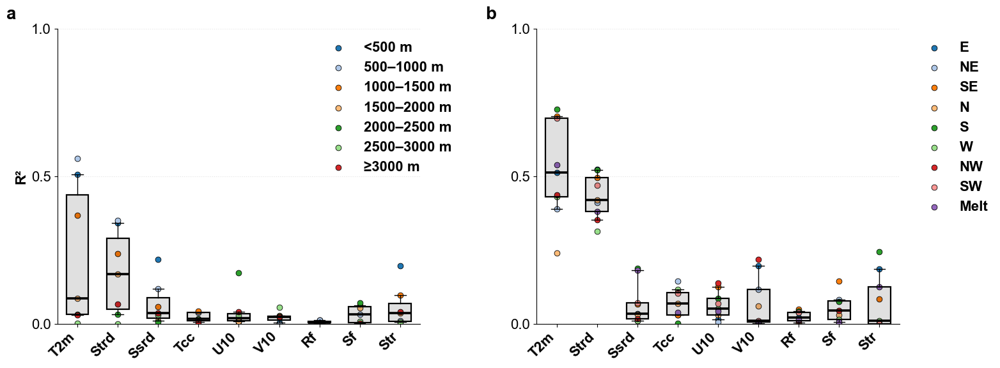

In [48]:
# -*- coding: utf-8 -*-
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TXT_PATH = r"C:\Users\11823\Desktop\regression_output.txt"
OUT_DIR  = r"C:\Users\11823\Desktop"

METRIC = "R2"

# ===================== 只改这一行即可控制删除变量 =====================
DROP_VARS = {"sp", "slhf", "tp"}

PRIORITY = ["t2m", "strd", "ssrd", "tcc", "u10", "v10"]
PALETTE = "tab20"

ALTITUDE_ORDER = [
    "0-500m", "500-1000m", "1000-1500m", "1500-2000m",
    "2000-2500m", "2500-3000m", "3000m+"
]
BASIN_ORDER = ["E", "NE", "SE", "N", "S", "W", "NW", "SW", "Melt"]

# ===================== 解析 Univariate =====================
def parse_univariate_blocks(txt: str):
    block_pat = re.compile(
        r"^\[(?P<kind>Altitude|Basin)\s+(?P<group>[^\]]+)\]\s+---\s+Univariate\s*\n"
        r"^变量\s*\|\s*slope\s*\|\s*R2\s*\|\s*r\s*\|\s*n\s*\n"
        r"(?P<body>(?:.*\n)*?)(?=^\[|\Z|^=+|^-{5,})",
        flags=re.MULTILINE
    )
    row_pat = re.compile(
        r"^\s*(?P<var>\S+)\s*\|\s*(?P<slope>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<R2>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<r>[-+]?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?)\s*\|\s*"
        r"(?P<n>\d[\d,]*)\s*$",
        flags=re.MULTILINE
    )

    rows = []
    for bm in block_pat.finditer(txt):
        kind = bm.group("kind")
        group = bm.group("group")
        for rm in row_pat.finditer(bm.group("body")):
            rows.append({
                "kind": kind,
                "group": group,
                "var": rm.group("var"),
                "R2": float(rm.group("R2"))
            })
    df = pd.DataFrame(rows)
    return df[df.kind=="Altitude"], df[df.kind=="Basin"]

# ===================== 工具 =====================
def build_var_order(df):
    d = df.copy()
    d["var_l"] = d["var"].str.lower()
    d = d[~d["var_l"].isin(DROP_VARS)]
    allv = list(pd.unique(d["var_l"]))
    ordered = [v for v in PRIORITY if v in allv]
    ordered += sorted(v for v in allv if v not in ordered)
    return ordered

def pretty_var(v): 
    return v[0].upper() + v[1:]

def format_altitude_label(g):
    g = g.lower().replace(" ", "")
    if g.endswith("m+"):
        return f"≥{g.replace('m+','')} m"
    a, b = g.replace("m","").split("-")
    return f"<{b} m" if a=="0" else f"{a}–{b} m"

# ===================== 画图函数 =====================
def draw_panel(ax, df, kind, var_order, legend_label_func=None,
               legend_anchor=(0.98,1.0)):   # ★ 左移一点

    d = df.copy()
    d["var_l"] = d["var"].str.lower()
    d = d[~d["var_l"].isin(DROP_VARS)]
    d = d[d["var_l"].isin(var_order)]

    groups = ALTITUDE_ORDER if kind=="Altitude" else BASIN_ORDER
    groups = [g for g in groups if g in d.group.unique()]

    cmap = plt.get_cmap(PALETTE)
    g2c = {g: cmap(i % cmap.N) for i,g in enumerate(groups)}

    data = [d[d.var_l==v].R2.values for v in var_order]
    bp = ax.boxplot(data, whis=(5,95), widths=0.55,
                    patch_artist=True, showfliers=False)

    for b in bp["boxes"]:
        b.set(facecolor=(0,0,0,0.12), edgecolor="black", linewidth=1.6)
    for m in bp["medians"]:
        m.set(color="black", linewidth=2.6)

    xs = np.arange(1,len(var_order)+1)
    for g in groups:
        sg = d[d.group==g]
        for i,v in enumerate(var_order):
            vv = sg[sg.var_l==v].R2
            if len(vv):
                ax.scatter(xs[i], vv.iloc[0], s=40,
                           color=g2c[g], edgecolors="black",
                           linewidths=0.6, label=g)

    ax.set_xticks(xs)
    ax.set_xticklabels([pretty_var(v) for v in var_order],
                       rotation=45, ha="right",
                       fontweight="bold")
    ax.set_yticks([0,0.5,1])
    ax.set_ylim(0,1)
    ax.grid(axis="y", linestyle=":", alpha=0.35)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(zip(labels,handles))
    labels = list(uniq.keys())
    handles = list(uniq.values())
    if legend_label_func:
        labels = [legend_label_func(l) for l in labels]

    leg = ax.legend(handles, labels, frameon=False,
                    bbox_to_anchor=legend_anchor, loc="upper left")
    for t in leg.get_texts():
        t.set_fontweight("bold")

# ===================== 主程序 =====================
def main():
    with open(TXT_PATH,"r",encoding="utf-8",errors="ignore") as f:
        txt = f.read()

    alt, bas = parse_univariate_blocks(txt)
    merged = pd.concat([alt,bas])
    var_order = build_var_order(merged)

    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["font.size"] = 16
    plt.rcParams["axes.labelweight"] = "bold"

    fig = plt.figure(figsize=(17,6))
    gs = fig.add_gridspec(1,2, wspace=0.32)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1], sharey=ax1)

    draw_panel(ax1, alt, "Altitude", var_order,
               legend_label_func=format_altitude_label,
               legend_anchor=(0.70,1.0))   # ★ 海拔图例左移

    draw_panel(ax2, bas, "Basin", var_order,
               legend_label_func=None,
               legend_anchor=(1.02,1.0))

    # ===== 子标题：放在轴外左上角 =====
    ax1.text(-0.14, 1.02, "a",
             transform=ax1.transAxes,
             fontsize=20, fontweight="bold",
             va="bottom", ha="left")

    ax2.text(-0.14, 1.02, "b",
             transform=ax2.transAxes,
             fontsize=20, fontweight="bold",
             va="bottom", ha="left")

    ax1.set_ylabel("R²", fontweight="bold")

    out = os.path.join(OUT_DIR,"final_univariate_boxpoints_alt_basin_v2.png")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print("[OK] saved:", out)
    plt.show()

if __name__ == "__main__":
    main()


Calculating region: East
Calculating region: EastNorth
Calculating region: EastSouth
Calculating region: Melt
Calculating region: North
Calculating region: South
Calculating region: West
Calculating region: WestNorth
Calculating region: WestSouth
Calculating region: The Entire Greenland Area
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.png


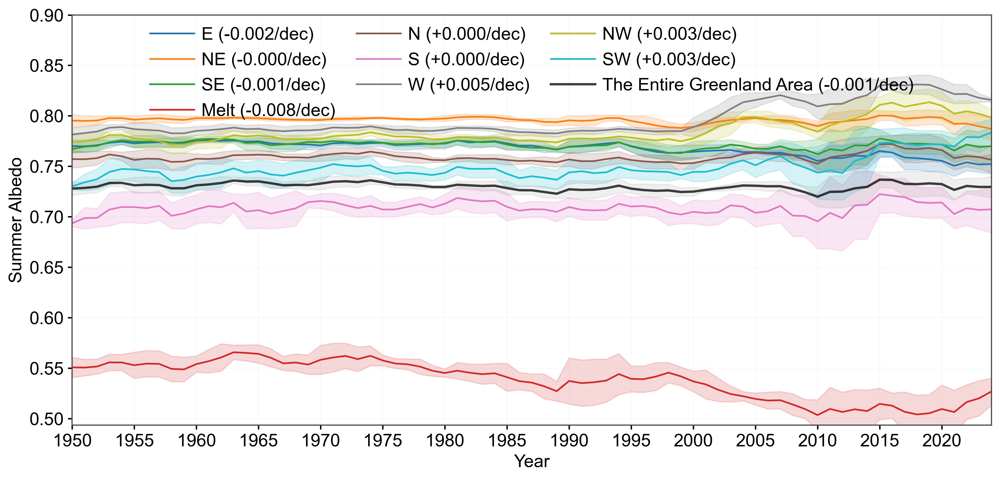

In [ ]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 =========
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
NC_PATH   = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR   = r"C:\greenland\1995bu"
OUT_CSV   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.csv")
OUT_FIG   = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.png")

# ========= 读取数据 =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取9个分区 + 全格陵兰 =========
regions = []
if albedo is not None:
    basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
    try:
        for shp in basin_shps:
            g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
            name = os.path.splitext(os.path.basename(shp))[0]
            regions.append((name, g))
        full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
        regions.append(("The Entire Greenland Area", full))
    except Exception as e:
        print(f"错误：读取Shapefile失败：{e}")

# ========= 计算时间序列 =========
records = []
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        years = ds["time"].values if not np.issubdtype(ts.index.dtype, np.datetime64) else pd.to_datetime(ts.index).year
        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region", "Year"])
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"]  = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        df = None
else:
    print("❌ 未能成功加载区域或反照率数据")
    df = None

# *************************************************************************
# ************************* START OF USER CUSTOMIZATION BLOCK ***************
# *************************************************************************
LEGEND_Y_OFFSET = 1.01 
# *************************************************************************
# ************************* END OF USER CUSTOMIZATION BLOCK ****************
# *************************************************************************

# ======== 新增：附加每个流域趋势 ========
trend_data = {
    "East": -0.002329151,
    "EastNorth": -0.000280762,
    "EastSouth": -0.000768503,
    "Melt": -0.00770941,
    "North": 0.000276715,
    "South": 0.000362804,
    "West": 0.004832396,
    "WestNorth": 0.003325931,
    "WestSouth": 0.003440071,
    "The Entire Greenland Area": -0.000666594
}

# --- 新增: 区域名称缩写映射 (按照用户要求修改) ---
name_map = {
    "East": "E", 
    "EastNorth": "NE", # 北东 (North-East)
    "EastSouth": "SE", # 南东 (South-East)
    "Melt": "Melt", 
    "North": "N", 
    "South": "S",
    "West": "W", 
    "WestNorth": "NW", # 北西 (North-West)
    "WestSouth": "SW", # 南西 (South-West)
    "The Entire Greenland Area": "The Entire Greenland Area" 
}
# ------------------------------------------------

# ========= 绘图 =========
if df is not None:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
    if regions:
        num_basins = len(regions) - 1
        colors = plt.cm.tab10(np.linspace(0,1,num_basins))

        # 绘制9个分区
        for (name, _), col in zip(regions[:-1], colors):
            grp = df[df["Region"] == name]
            
            # 使用缩写和趋势值创建标签
            display_name = name_map.get(name, name)
            trend_val = trend_data.get(name, np.nan)
            label = f"{display_name} ({trend_val:+.3f}/dec)" 
            
            ax.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4, label=label)
            ax.fill_between(grp["Year"],
                            grp["mean_5yr"] - grp["std_5yr"],
                            grp["mean_5yr"] + grp["std_5yr"],
                            color=col, alpha=0.18)

        # 绘制全格陵兰
        gall = df[df["Region"] == "The Entire Greenland Area"]
        # 使用缩写(全称)和趋势值创建全格陵兰标签
        gall_label = f"{name_map['The Entire Greenland Area']} ({trend_data['The Entire Greenland Area']:+.3f}/dec)"
        
        ax.plot(gall["Year"], gall["mean_5yr"], color="k", lw=2.0, alpha=0.75, label=gall_label)
        ax.fill_between(gall["Year"],
                        gall["mean_5yr"] - gall["std_5yr"],
                        gall["mean_5yr"] + gall["std_5yr"],
                        color="gray", alpha=0.12)

    # ======== 图形美化 ========
    ax.set_xlabel("Year", fontsize=15)
    ax.set_ylabel("Summer Albedo", fontsize=15)
    ax.set_xlim(1950, 2024)
    ax.set_xticks(np.arange(1950, 2025, 5))
    min_albedo = df["mean_5yr"].min() if not df.empty else 0.5
    ax.set_ylim(min_albedo - 0.01, 0.9)
    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
        ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
    ax.grid(alpha=0.15, linewidth=0.4)

    # ======== 图例改为3行 ========
    ax.legend(
        frameon=False, fontsize=15, ncol=3, loc="upper center",
        bbox_to_anchor=(0.5, LEGEND_Y_OFFSET),
        handlelength=2.5, handletextpad=0.4, columnspacing=1.2
    )

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成。")

Calculating region: East
Calculating region: EastNorth
Calculating region: EastSouth
Calculating region: Melt
Calculating region: North
Calculating region: South
Calculating region: West
Calculating region: WestNorth
Calculating region: WestSouth
Calculating region: The Entire Greenland Area
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_AlbedoTimeSeries_TrendBar_V1.png


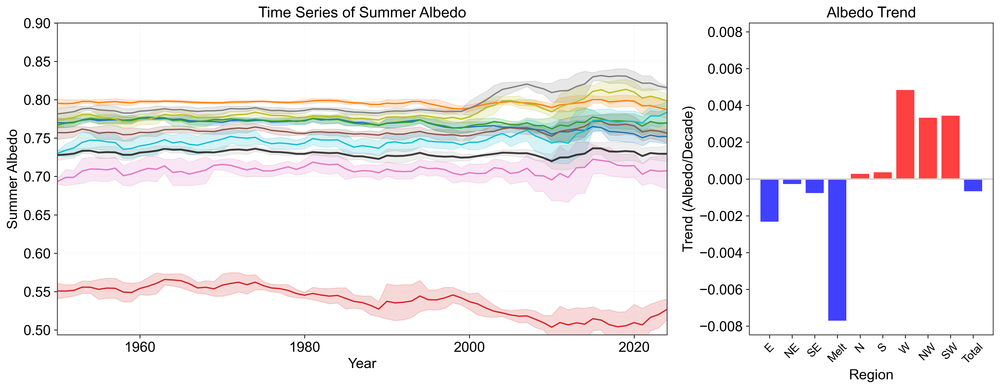

In [ ]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 (使用用户提供的路径，假定它们已存在) =========
# ‼️ 确保这些路径在您的环境中是正确的 ‼️
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP = r"C:\greenland\Greenland_shp\Gboundry.shp"
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR  = r"C:\greenland\1995bu"
OUT_CSV  = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries.csv")
# 输出文件名
OUT_FIG  = os.path.join(OUT_DIR, "Fig_Greenland_9Basin_AlbedoTimeSeries_TrendBar_V1.png")

# ========= 读取数据 (原始代码块) =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取9个分区 + 全格陵兰 (原始代码块) =========
regions = []
if albedo is not None:
    basin_shps = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
    try:
        for shp in basin_shps:
            g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
            name = os.path.splitext(os.path.basename(shp))[0]
            regions.append((name, g))
        full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
        regions.append(("The Entire Greenland Area", full))
    except Exception as e:
        print(f"错误：读取Shapefile失败：{e}")

# ========= 计算时间序列 (原始代码块，已修复语法错误) =========
records = []
df = None # 预先初始化 df
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        # 假设 time 坐标在 xarray 中是年份或可转换为年份
        years = ds["time"].values if not np.issubdtype(ts.index.dtype, np.datetime64) else pd.to_datetime(ts.index).year
        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region", "Year"])
        
        # ⬇️ 修复了不可见字符 U+00A0 导致的 SyntaxError ⬇️
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        print("❌ 未能计算任何时间序列")
        df = None
else:
    print("❌ 未能成功加载区域或反照率数据")
    df = None


# ======== 附加每个流域趋势 (用户数据) ========
trend_data = {
    "East": -0.002329151,
    "EastNorth": -0.000280762,
    "EastSouth": -0.000768503,
    "Melt": -0.00770941,
    "North": 0.000276715,
    "South": 0.000362804,
    "West": 0.004832396,
    "WestNorth": 0.003325931,
    "WestSouth": 0.003440071,
    "The Entire Greenland Area": -0.000666594
}

# --- 区域名称缩写映射 (按最新要求 Total) ---
name_map = {
    "East": "E", 
    "EastNorth": "NE", 
    "EastSouth": "SE", 
    "Melt": "Melt", 
    "North": "N", 
    "South": "S",
    "West": "W", 
    "WestNorth": "NW", 
    "WestSouth": "SW", 
    "The Entire Greenland Area": "Total" 
}

# ========= 绘图 (按 V1 要求修改) =========
if df is not None:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    # 创建包含两个子图的画布: ax1 (折线图), ax2 (柱状图)
    fig, (ax1, ax2) = plt.subplots(
        nrows=1, ncols=2, 
        figsize=(15, 6), 
        dpi=300, 
        sharey=False, 
        gridspec_kw={'width_ratios': [2.5, 1]} # 宽度比例
    )

    if regions:
        # 获取分区名称列表 (不含全格陵兰)
        basin_names = [name for name, _ in regions[:-1]]
        num_basins = len(basin_names)
        colors = plt.cm.tab10(np.linspace(0,1,num_basins))
        
        # --- 1. 绘制左侧折线图 (ax1) ---
        
        # 绘制9个分区
        for name, col in zip(basin_names, colors):
            grp = df[df["Region"] == name]
            ax1.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4)
            ax1.fill_between(grp["Year"],
                             grp["mean_5yr"] - grp["std_5yr"],
                             grp["mean_5yr"] + grp["std_5yr"],
                             color=col, alpha=0.18)

        # 绘制全格陵兰
        gall = df[df["Region"] == "The Entire Greenland Area"]
        ax1.plot(gall["Year"], gall["mean_5yr"], color="k", lw=2.0, alpha=0.75)
        ax1.fill_between(gall["Year"],
                         gall["mean_5yr"] - gall["std_5yr"],
                         gall["mean_5yr"] + gall["std_5yr"],
                         color="gray", alpha=0.12)

        # --- 折线图 (ax1) 美化和修改 ---
        ax1.set_xlabel("Year", fontsize=15)
        ax1.set_ylabel("Summer Albedo", fontsize=15)
        ax1.set_xlim(1950, 2024)
        ax1.set_xticks(np.arange(1960, 2021, 20)) # X轴改为20年一刻度
        
        min_albedo = df["mean_5yr"].min() if not df.empty else 0.5
        ax1.set_ylim(min_albedo - 0.01, 0.9)
        
        ax1.grid(alpha=0.15, linewidth=0.4)
        ax1.set_title("Time Series of Summer Albedo", fontsize=16)


        # --- 2. 绘制右侧柱状图 (ax2) ---
        
        trends_df = pd.Series(trend_data).reset_index()
        trends_df.columns = ['Region', 'Trend']
        trends_df['Region_Short'] = trends_df['Region'].map(name_map)
        
        # 确保柱子顺序正确
        sort_order = [name for name, _ in regions[:-1]] + ["The Entire Greenland Area"]
        trends_df = trends_df.set_index('Region').loc[sort_order].reset_index()
        
        # 设定柱状图颜色：正值红色，负值蓝色
        bar_colors_trends = ['red' if t > 0 else 'blue' for t in trends_df['Trend']]
        
        # 绘制柱状图
        ax2.bar(
            x=trends_df['Region_Short'], 
            height=trends_df['Trend'], 
            color=bar_colors_trends, 
            alpha=0.75
        )
        
        # --- 柱状图 (ax2) 美化 ---
        ax2.axhline(0, color='lightgray', linestyle='-', linewidth=1.5) # 零线
        
        ax2.set_xlabel("Region", fontsize=15)
        ax2.set_ylabel("Trend (Albedo/Decade)", fontsize=15)
        
        ax2.tick_params(axis='x', rotation=45, labelsize=12)
        
        # 调整Y轴范围，使其居中于零点
        max_abs_trend = trends_df['Trend'].abs().max()
        y_lim_pad = max_abs_trend * 0.1
        ax2.set_ylim(-max_abs_trend - y_lim_pad, max_abs_trend + y_lim_pad)
        ax2.set_title("Albedo Trend", fontsize=16)

        # 调整所有子图的边框
        for ax in [ax1, ax2]:
            for spine in ['top', 'bottom', 'left', 'right']:
                ax.spines[spine].set_visible(True)
                ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
                ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
        
    fig.tight_layout()
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成。")

In [4]:
# -*- coding: utf-8 -*-
"""
修正版：添加 albedo 流域时间序列计算 (Greenland_albedo1950-2024.nc)
"""
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import rioxarray
from shapely.geometry import mapping

# ========================= 路径配置 =========================
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"

PATH_HCLCVIMF = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc"
PATH_ALBEDO   = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"

OUT_DIR  = r"C:\greenland\1995bu\OtherVariables"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_CSV  = os.path.join(OUT_DIR, "Fig_Greenland_AllBasin_TimeSeries.csv")

VARIABLE_MAP = {
    'hc': PATH_HCLCVIMF,
    'lc': PATH_HCLCVIMF,
    'vimdf': PATH_HCLCVIMF,
    'alb': PATH_ALBEDO
}

# ========================= 工具函数 =========================

def safe_open_nc(nc_path, var_name):
    print(f"\n--- 正在打开文件: {os.path.basename(nc_path)} → {var_name} ---")

    name_map = {'hc': 'hcc', 'lc': 'lcc', 'vimdf': 'vimdf', 'alb': 'albedo'}
    var_nc = name_map.get(var_name, var_name)

    try:
        ds = xr.open_dataset(nc_path)
    except Exception:
        ds = xr.open_dataset(nc_path, engine="h5netcdf")
        print(f"⚙️ 用 h5netcdf 成功打开 {os.path.basename(nc_path)}")

    if var_nc not in ds:
        print(f"❌ {var_nc} 不在 {os.path.basename(nc_path)} 中, 可用变量: {list(ds.keys())}")
        return None

    da = ds[var_nc]

    # 统一维度
    for cand in ["time", "valid_time"]:
        if cand in da.dims:
            if cand != "time":
                da = da.rename({cand: "time"})
            break

    rename_dict = {}
    if "latitude" in da.dims: rename_dict["latitude"] = "lat"
    if "longitude" in da.dims: rename_dict["longitude"] = "lon"
    if rename_dict:
        da = da.rename(rename_dict)

    # CRS
    try:
        da.rio.set_spatial_dims(x_dim="lon", y_dim="lat", inplace=True)
        if not da.rio.crs:
            da.rio.write_crs("EPSG:4326", inplace=True)
    except Exception as e:
        print(f"⚠️ CRS 设置失败: {e}")

    return da


def process_to_annual_summer_mean(da, var_name):
    """提取夏季 (6,7,8月) 平均并按年聚合"""
    if "time" not in da.dims:
        return None
    try:
        da = da.sel(time=da.time.dt.month.isin([6,7,8]))
        out = da.groupby("time.year").mean("time", skipna=True)
        out = out.rename({"year": "time"})
        print(f"✅ {var_name} 夏季年度平均完成。")
        return out
    except Exception as e:
        print(f"❌ {var_name} 夏季平均出错: {e}")
        return None


def calculate_time_series_for_all_regions(annual_da, regions, var_name):
    """计算每个流域的时间序列"""
    records = []
    print(f"➡️ 计算 {var_name} 的流域时间序列...")
    for name, g in regions:
        try:
            clipped = annual_da.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
            ts = clipped.mean(dim=("lat", "lon"), skipna=True).to_pandas()
            df = pd.DataFrame({
                "Year": ts.index.values,
                "Value": ts.values,
                "Region": name,
                "Variable": var_name
            })
            records.append(df)
        except Exception as e:
            print(f"❌ 区域 {name} 出错: {e}")
    return pd.concat(records, ignore_index=True) if records else None


# ========================= 主流程 =========================

# 读取流域
regions = []
basin_files = sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp")))
for shp in basin_files:
    g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
    name = os.path.splitext(os.path.basename(shp))[0]
    regions.append((name, g))
full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
regions.append(("The Entire Greenland Area", full))
print("✅ 区域 Shapefile 读取完成。")

# 读取已有 CSV
if os.path.exists(OUT_CSV):
    df_existing = pd.read_csv(OUT_CSV)
    df_existing["Year"] = pd.to_numeric(df_existing["Year"], errors="coerce").astype("Int64")
    df_existing["Value"] = pd.to_numeric(df_existing["Value"], errors="coerce")
    existing_vars = set(df_existing["Variable"].dropna().unique())
    print(f"📘 已存在变量: {sorted(existing_vars)}")
else:
    df_existing = pd.DataFrame()
    existing_vars = set()

# 仅计算缺失变量
all_df = []
for var, path in VARIABLE_MAP.items():
    if var in existing_vars:
        print(f"⏩ 跳过已完成变量: {var}")
        continue

    da = safe_open_nc(path, var)
    if da is None:
        continue
    da_summer = process_to_annual_summer_mean(da, var)
    if da_summer is None:
        continue
    df = calculate_time_series_for_all_regions(da_summer, regions, var)
    if df is not None:
        df["Year"] = pd.to_numeric(df["Year"], errors="coerce").astype("Int64")
        df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
        all_df.append(df)

# 合并保存
if all_df:
    df_new = pd.concat(all_df, ignore_index=True)
    df_final = pd.concat([df_existing, df_new], ignore_index=True)
    df_final.to_csv(OUT_CSV, index=False)
    print("\n===================================================")
    print(f"✅ 新变量计算完成并合并保存至: {OUT_CSV}")
    print("===================================================")
else:
    print("⚠️ 无新变量需要计算。")


✅ 区域 Shapefile 读取完成。
📘 已存在变量: ['hc', 'lc', 'rf', 'sf', 'ssrd', 'strd', 't2m', 'tcc', 'tp', 'vimdf']
⏩ 跳过已完成变量: hc
⏩ 跳过已完成变量: lc
⏩ 跳过已完成变量: vimdf

--- 正在打开文件: Greenland_albedo1950-2024.nc → alb ---
✅ alb 夏季年度平均完成。
➡️ 计算 alb 的流域时间序列...

✅ 新变量计算完成并合并保存至: C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv


C:\Users\11823\AppData\Local\Temp\ipykernel_28636\3750265849.py:151: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(region_order, fontsize=10, rotation=0)
C:\Users\11823\AppData\Local\Temp\ipykernel_28636\3750265849.py:169: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


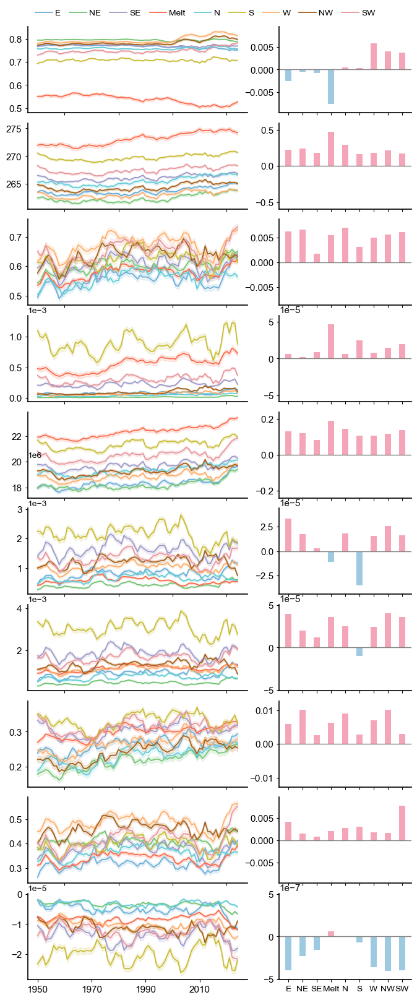

In [2]:
# -*- coding: utf-8 -*-
"""
NPJ-style Greenland Multi-Variable Time Series + Trend Panel (Refined v10)
→ SSRD/STRD 人工 “1e6” 与 Matplotlib 自动科学计数标识位置完全一致；
→ 字号统一、不加粗；布局稳定无死循环。
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import linregress
# 移除 from matplotlib.ticker import ScalarFormatter 和 CustomScalarFormatter

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_AllVar_v10_final_adjust_v7.png" # 更新保存路径

variables = ["albedo", "t2m", "tcc", "rf", "strd", "sf", "tp", "hcc", "lcc", "vimdf"]
# **【修正 U+00A0 错误】** 确保这里只有标准空格
var_labels = {
    'albedo':'ALBEDO','hcc':'HCC','lcc':'LCC','rf':'RF','sf':'SF',
    'strd':'STRD','t2m':'T2M','tcc':'TCC','tp':'TP','vimdf':'VIMDF' 
}
region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Total']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Total':'#969696'
}

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

# ========= 数据 & 函数 (不变) =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW','Total':'Total'
})
def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p

# ========= 绘图 =========
n_var = len(variables)

# 保持宽度 8，高度 n_var * 2.0
fig = plt.figure(figsize=(8, n_var * 2.0)) 
# 保持 width_ratios=[1.2, 0.72]
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.18, hspace=0.12)
handles, labels = [], []


for i, var in enumerate(variables):
    sub = df[df['Variable'] == var].copy()
    
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6

    # ---- 折线图 ----
    ax1 = fig.add_subplot(gs[i, 0])
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty:
            continue
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        if i == 0:
             handles.append(line)
             labels.append(r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                            color=colors[r], alpha=0.15)

    # ---- 轴样式 ----
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    if i < n_var - 1:
        ax1.set_xticklabels([])
    else:
        # **【修改 1】** 注释掉 ax1.set_xlabel("Year")
        # ax1.set_xlabel("Year", fontsize=12) 
        ax1.set_xticks(np.arange(1950, 2030, 20))
    ax1.tick_params(direction='out', length=3)

    # ---- 科学计数法 ----
    if var in ['ssrd', 'strd']: 
        ax1.ticklabel_format(axis='y', style='plain')
    else:
        ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))

    # ---- 调整自动 offset_text 样式 (位置和格式统一) ----
    offset_text = ax1.yaxis.get_offset_text()
    offset_text.set_fontsize(10)
    offset_text.set_fontweight('normal')
    offset_text.set_color('black')
    
    # 保持位置统一下移（统一到上部）
    offset_text.set_y(offset_text.get_position()[1] - 0.05) 

    # **【科学计数法格式修正】** 修正 offset_text 格式 (将 '1e' 替换为 'e' 的核心逻辑)
    if offset_text.get_text():
        # 匹配 Matplotlib 的 LaTeX 格式： 10^{X} 替换为 e^{X}
        text = offset_text.get_text().replace(r'10^{', r'e^{') 
        # 匹配非 LaTeX 格式： 1eX 替换为 eX
        text = text.replace('1e', 'e')
        offset_text.set_text(text)

    # ---- 对 STRD 手动添加与自动 offset 相同位置的 “1e6” ----
    if var in ['ssrd', 'strd']: 
        ref_pos = offset_text.get_position()
        ax1.text(ref_pos[0], ref_pos[1], "1e6",
                    transform=ax1.transAxes,
                    fontsize=10, color='black',
                    ha='left', va='bottom')

    # ---- 柱状趋势 ----
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); pvals.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope); pvals.append(p)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_order, trends, color=cols, width=0.45)
    ax2.axhline(0, color='gray', lw=1)
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        ax2.set_ylim(-lim, lim)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.tick_params(direction='out', length=3)
    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        # 保持 rotation=0
        ax2.set_xticklabels(region_order, fontsize=10, rotation=0) 
        ax2.set_xlabel("")
    ax2.set_title("") 

# **【图例修正】** 图例一行 (ncol=10)，紧贴，缩小间距
ax1_first = fig.axes[0] 
ax1_first.legend(handles, labels, 
                    ncol=10, # 改为一行
                    loc='lower left', 
                    bbox_to_anchor=(0, 1.02), # 紧贴顶部
                    fontsize=10, frameon=False, 
                    columnspacing=1.0, # 缩小列间距
                    handletextpad=0.3) # 缩小文本与标记的间距


# ---- 稳定布局 ----
fig.set_constrained_layout(True) 

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

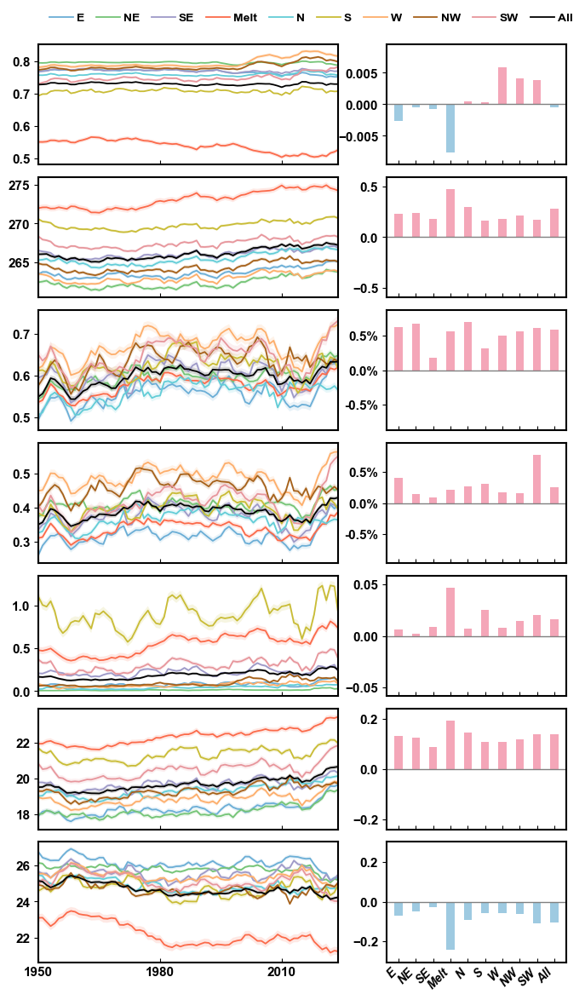

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
from scipy.stats import linregress

# ========= 参数 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_TimeseriesTrend_Final_v17_Bold.png"

VAR_DISPLAY_NAMES_ALL = {
    "albedo": "Albedo", "t2m": "T2m", "z500": "500 hPa Z",
    "z200": "200 hPa Z", "tcc": "Tcc", "lcc": "Lcc",
    "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd"
}
desired_vars_ordered = list(VAR_DISPLAY_NAMES_ALL.keys()) 

region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Entire']
region_display = ['E','NE','SE','Melt','N','S','W','NW','SW','All']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Entire':'#000000'
}

# ========= 样式全局加粗 =========
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'      # 全局字体加粗
plt.rcParams['axes.labelweight'] = 'bold' # 轴标签加粗
plt.rcParams['axes.linewidth'] = 1.5      # 边框稍微加粗以匹配黑体字
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'out'

# ========= 数据处理 =========
df = pd.read_csv(CSV_PATH)
variable_mapping = {
    'alb': 'albedo', 'hc': 'hcc', 'lc': 'lcc', 'rf': 'rf', 'sf': 'sf',
    'ssrd': 'ssrd', 'strd': 'strd', 't2m': 't2m', 'tcc': 'tcc',
    'tp': 'tp', 'vimdf': 'vimdf'
}
df['Variable'] = df['Variable'].replace(variable_mapping)
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW',
    'The Entire Greenland Area':'Entire'
})

present_vars_in_df = df['Variable'].unique()
variables_to_plot = [v for v in desired_vars_ordered if v in present_vars_in_df]

if not variables_to_plot:
    raise SystemExit("CSV文件中未找到任何指定的变量，程序退出。")

def calc_trend(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 5:
        return np.nan, np.nan
    slope, _, _, p, _ = linregress(x[mask], y[mask])
    return slope * 10, p 

# ========= 绘图 =========
n_var = len(variables_to_plot)
fig = plt.figure(figsize=(8, n_var * 2.0)) 

# wspace=0.08: 紧贴布局
gs = GridSpec(n_var, 2, width_ratios=[1.2, 0.72], wspace=0.20, hspace=0.1)

handles, labels = [], []
year_min = df['Year'].min()
year_max = df['Year'].max()

for i, var in enumerate(variables_to_plot):
    sub = df[df['Variable'] == var].copy()
    
    # SSRD/STRD 除以 1e6
    if var in ['ssrd', 'strd']: 
        sub['Value'] = sub['Value'] / 1e6
    
    # RF 乘以 1000
    if var == 'rf':
        sub['Value'] = sub['Value'] * 1000

    # -----------------------
    # Left: Time Series
    # -----------------------
    ax1 = fig.add_subplot(gs[i, 0])
    
    for r in region_order:
        dat = sub[sub['Region'] == r].sort_values('Year')
        if dat.empty: continue
        
        y = dat['Value'].rolling(5, center=True, min_periods=1).mean()
        line, = ax1.plot(dat['Year'], y, color=colors[r], lw=1.3)
        
        if i == 0:
            handles.append(line)
            labels.append('All' if r == 'Entire' else r)
        
        ax1.fill_between(dat['Year'], y - y.std()/3, y + y.std()/3,
                         color=colors[r], alpha=0.15, edgecolor='none')

    ax1.set_xlim(year_min, year_max)
    ax1.ticklabel_format(axis='y', style='sci', scilimits=(-3, 4))
    ax1.yaxis.get_offset_text().set_visible(False)
    
    # 强制刻度字体加粗 (虽然rcParams已设置，但显式刷新更稳妥)
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_fontweight('bold')

    if i < n_var - 1:
        ax1.set_xticklabels([])
        ax1.set_xticks([1950, 1980, 2010])
    else:
        ax1.set_xticks([1950, 1980, 2010])
        ax1.set_xticklabels(['1950', '1980', '2010'])

    # -----------------------
    # Right: Bar Trend
    # -----------------------
    ax2 = fig.add_subplot(gs[i, 1])
    trends, pvals = [], []
    
    for r in region_order:
        dat = sub[sub['Region'] == r]
        if dat.empty:
            trends.append(np.nan); continue
        slope, p = calc_trend(dat['Year'].values, dat['Value'].values)
        trends.append(slope)

    cols = ['#f4a6b8' if t > 0 else '#9ecae1' for t in trends]
    ax2.bar(region_display, trends, color=cols, width=0.45, edgecolor='none')
    ax2.axhline(0, color='gray', lw=1)
    
    if np.isfinite(trends).any():
        lim = np.nanmax(np.abs(trends)) * 1.25
        if lim == 0: lim = 0.1
        ax2.set_ylim(-lim, lim)

    # Tcc / Lcc 显示为百分比 (加粗)
    if var in ['tcc', 'lcc']:
        ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: '{:.1f}%'.format(x*100)))
    else:
        ax2.ticklabel_format(axis='y', style='plain') 

    # 刻度字体加粗
    for label in ax2.get_yticklabels():
        label.set_fontweight('bold')

    if i < n_var - 1:
        ax2.set_xticklabels([])
    else:
        ax2.set_xticks(range(len(region_display)))
        # 45度旋转 + 加粗 + 斜体
        ax2.set_xticklabels(region_display, fontsize=10, rotation=45, ha='right',
                            fontweight='bold', fontstyle='italic')
        ax2.set_xlabel("")

# Legend
if handles and labels:
    ax1_first = fig.axes[0]
    ax1_first.legend(handles, labels, 
                     ncol=10, 
                     loc='lower left', 
                     bbox_to_anchor=(0, 1.08), 
                     fontsize=10, frameon=False, 
                     columnspacing=1.0, 
                     handletextpad=0.3,
                     prop={'weight': 'bold'}) # 图例字体加粗

plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

In [1]:
#===================================拉伸和拼接图象==========================================
from PIL import Image
import os

def stitch_images_horizontal(img_path1, img_path2, output_path):
    """
    水平拼接两个图像，并将较矮的图像拉伸以匹配较高图像的高度。
    """
    try:
        # 打开图像并确保它们支持透明度 (RGBA)
        img1 = Image.open(img_path1).convert("RGBA")
        img2 = Image.open(img_path2).convert("RGBA")

        # 获取图像尺寸
        width1, height1 = img1.size
        width2, height2 = img2.size

        # 确定目标高度（取两者中较高的）
        target_height = max(height1, height2)

        # --- 调整图像大小以匹配目标高度 ---
        # 如果图像1不是目标高度，拉伸它
        if height1 != target_height:
            # 计算新的宽度以保持原始宽高比
            new_width1 = int(width1 * (target_height / height1))
            print(f"正在将 {os.path.basename(img_path1)} 的高度从 {height1} 拉伸到 {target_height}...")
            img1 = img1.resize((new_width1, target_height), Image.LANCZOS)
            width1, height1 = img1.size # 更新尺寸

        # 如果图像2不是目标高度，拉伸它
        if height2 != target_height:
            # 计算新的宽度以保持原始宽高比
            new_width2 = int(width2 * (target_height / height2))
            print(f"正在将 {os.path.basename(img_path2)} 的高度从 {height2} 拉伸到 {target_height}...")
            img2 = img2.resize((new_width2, target_height), Image.LANCZOS)
            width2, height2 = img2.size # 更新尺寸

        # 创建新的空白图像
        total_width = width1 + width2
        new_img = Image.new('RGBA', (total_width, target_height), (0, 0, 0, 0)) # 透明背景

        # 将两图像粘贴到新图像上
        new_img.paste(img1, (0, 0))
        new_img.paste(img2, (width1, 0)) # 粘贴在第一个图像的右侧

        # 保存结果
        new_img.save(output_path)
        print(f"\n成功！图像已拼接并保存到: {output_path}")

    except FileNotFoundError as e:
        print(f"错误：找不到文件 {e.filename}。请检查路径是否正确。")
    except Exception as e:
        print(f"发生错误: {e}")

# --- 你的文件路径 ---

# 请注意：Python中的路径需要使用正斜杠 (/) 或双反斜杠 (\\)
left_image_path = r"C:\greenland\1995bu\fig4\left.png"
right_image_path = r"C:\greenland\1995bu\fig4\right.png"

# 定义你希望保存的输出文件路径
output_image_path = r"C:\greenland\1995bu\fig4\stitched_figure.png"

# 执行拼接
stitch_images_horizontal(left_image_path, right_image_path, output_image_path)

正在将 right.png 的高度从 4694 拉伸到 6691...

成功！图像已拼接并保存到: C:\greenland\1995bu\fig4\stitched_figure.png


In [ ]:
from PIL import Image

def stitch_images_horizontal(img_path1, img_path2, output_path):
    img1 = Image.open(img_path1).convert("RGBA")
    img2 = Image.open(img_path2).convert("RGBA")

    # 获取图像尺寸
    width1, height1 = img1.size
    width2, height2 = img2.size

    # 确定目标高度（取两者中较高的）
    target_height = max(height1, height2)

    # 如果需要拉伸，则调整图像大小
    if height1 != target_height:
        # 计算新的宽度以保持宽高比，如果不是等比例拉伸，则直接设置高度并让宽度变化
        # 为了拉伸到目标高度并保持对齐，我们直接设置高度，宽度会随之改变
        img1 = img1.resize((int(width1 * (target_height / height1)), target_height), Image.LANCZOS)
        width1, height1 = img1.size # 更新尺寸

    if height2 != target_height:
        img2 = img2.resize((int(width2 * (target_height / height2)), target_height), Image.LANCZOS)
        width2, height2 = img2.size # 更新尺寸

    # 创建新的空白图像，宽度为两图像宽度之和，高度为目标高度
    total_width = width1 + width2
    new_img = Image.new('RGBA', (total_width, target_height))

    # 将两图像粘贴到新图像上
    new_img.paste(img1, (0, 0))
    new_img.paste(img2, (width1, 0)) # 第二个图像从第一个图像的宽度之后开始粘贴

    new_img.save(output_path)
    print(f"图像已拼接并保存到: {output_path}")

# 示例用法
# stitch_images_horizontal("image1.png", "image2.png", "stitched_image.png")

# 如果你想垂直拼接
def stitch_images_vertical(img_path1, img_path2, output_path):
    img1 = Image.open(img_path1).convert("RGBA")
    img2 = Image.open(img_path2).convert("RGBA")

    width1, height1 = img1.size
    width2, height2 = img2.size

    target_width = max(width1, width2)

    if width1 != target_width:
        img1 = img1.resize((target_width, int(height1 * (target_width / width1))), Image.LANCZOS)
        width1, height1 = img1.size

    if width2 != target_width:
        img2 = img2.resize((target_width, int(height2 * (target_width / width2))), Image.LANCZOS)
        width2, height2 = img2.size

    total_height = height1 + height2
    new_img = Image.new('RGBA', (target_width, total_height))

    new_img.paste(img1, (0, 0))
    new_img.paste(img2, (0, height1))

    new_img.save(output_path)
    print(f"图像已垂直拼接并保存到: {output_path}")

# 这是一个使用示例：
# 创建两个示例图片
# Image.new('RGBA', (300, 200), (255, 0, 0, 255)).save("red_rect.png")
# Image.new('RGBA', (400, 250), (0, 0, 255, 255)).save("blue_rect.png")
# stitch_images_horizontal("red_rect.png", "blue_rect.png", "stitched_horizontal.png")
# stitch_images_vertical("red_rect.png", "blue_rect.png", "stitched_vertical.png")

In [2]:
# -*- coding: utf-8 -*-
"""
Greenland Basin Time Series Generator (Summer Mean)
---------------------------------------------------
• 支持变量: RF, TCC, T2M, STRD, SSRD
• 自动识别 valid_time / time
• 提取夏季 (JJA, 6–8月) 平均 → 年度序列
• STRD, SSRD 自动单位缩放为 MJ m⁻²
• 输出 CSV + PNG (9 Basins + Whole Greenland)
"""

import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# =============== 基本路径 ===============
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
FULL_SHP  = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_DIR   = r"C:\greenland\1995bu"
os.makedirs(OUT_DIR, exist_ok=True)

# =============== 变量任务列表 ===============
VAR_TASKS = [
    dict(name="RF",    nc=r"C:\greenland\sf_tp_rf.nc", 
         var="rf",   ylabel="Rainfall (m water eq)"),
    dict(name="TCC",   nc=r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc", 
         var="tcc",  ylabel="Total Cloud Cover (0–1)"),
    dict(name="T2M",   nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="t2m",  ylabel="2 m Temperature (K)"),
    dict(name="STRD",  nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="strd", ylabel="Downwelling Longwave (MJ m⁻²)"),
    dict(name="SSRD",  nc=r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc", 
         var="ssrd", ylabel="Downwelling Shortwave (MJ m⁻²)"),
]

# =============== 区域缩写映射 ===============
NAME_MAP = {
    "East": "E", "EastNorth": "NE", "EastSouth": "SE",
    "Melt": "Melt", "North": "N", "South": "S",
    "West": "W", "WestNorth": "NW", "WestSouth": "SW",
    "The Entire Greenland Area": "The Entire Greenland Area"
}

# =============== Matplotlib风格 ===============
FONT = 15
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT,
    "axes.linewidth": 1.0,
    "axes.edgecolor": "0.3",
    "xtick.direction": "out",
    "ytick.direction": "out"
})

# ---------------------------------------------------------------------
# 基础函数
# ---------------------------------------------------------------------
def _ensure_crs(da):
    """写入EPSG:4326 CRS"""
    if not da.rio.crs:
        da.rio.write_crs("EPSG:4326", inplace=True)
    return da

def _read_regions():
    """读取9个流域 + 全格陵兰 shapefile"""
    regions = []
    for shp in sorted(glob.glob(os.path.join(BASIN_DIR, "*.shp"))):
        g = gpd.read_file(shp).to_crs("EPSG:4326").dissolve().reset_index(drop=True)
        name = os.path.splitext(os.path.basename(shp))[0]
        regions.append((name, g))
    full = gpd.read_file(FULL_SHP).to_crs("EPSG:4326")
    regions.append(("The Entire Greenland Area", full))
    return regions

def _trend_per_decade(years, values):
    ok = np.isfinite(values) & np.isfinite(years)
    if ok.sum() < 2: return np.nan
    return np.polyfit(years[ok], values[ok], 1)[0] * 10

# ---------------------------------------------------------------------
# 主计算函数
# ---------------------------------------------------------------------
def compute_basin_series(ncpath, var):
    """读取 NetCDF, 提取 JJA 年度均值, 计算 basin 序列"""
    if not os.path.exists(ncpath):
        print(f"❌ 未找到文件: {ncpath}")
        return pd.DataFrame()

    ds = xr.open_dataset(ncpath)
    # 自动识别时间维
    if "valid_time" in ds:
        ds = ds.rename({"valid_time": "time"})
    if "latitude" in ds:
        ds = ds.rename({"latitude": "lat"})
    if "longitude" in ds:
        ds = ds.rename({"longitude": "lon"})
    da = ds[var].squeeze(drop=True)
    da = _ensure_crs(da)

    # ---- 单位缩放 ----
    if var in ["strd", "ssrd"]:
        da = da / 1e6
        da.attrs["units"] = "MJ m⁻²"

    # ---- 夏季 (JJA) 平均到年度 ----
    if np.issubdtype(da["time"].dtype, np.datetime64):
        da = da.sel(time=da["time"].dt.month.isin([6, 7, 8]))
        da = da.groupby("time.year").mean("time", skipna=True)
        da = da.rename({"year": "time"})

    # ---- 区域均值 ----
    regions = _read_regions()
    recs = []
    for name, g in regions:
        print(f"→ {os.path.basename(ncpath)} | {name}")
        try:
            clip = da.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
            ts = clip.mean(dim=("lat", "lon"), skipna=True).to_pandas()
            recs.append(pd.DataFrame({
                "Year": ts.index.astype(int),
                "Value": ts.values,
                "Region": name
            }))
        except Exception as e:
            print(f"   ⚠️ 裁剪失败 {name}: {e}")

    if not recs:
        return pd.DataFrame()

    df = pd.concat(recs, ignore_index=True)
    df = df.sort_values(["Region", "Year"])
    df["mean_5yr"] = df.groupby("Region")["Value"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
    df["std_5yr"]  = df.groupby("Region")["Value"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
    df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
        lambda g: pd.Series(_trend_per_decade(g["Year"], g["Value"]), index=g.index)
    )
    df["units"] = da.attrs.get("units", "")
    return df

# ---------------------------------------------------------------------
# 绘图函数
# ---------------------------------------------------------------------
def plot_basin_series(df, ylabel, outpng):
    if df.empty:
        print(f"⚠️ 数据为空，跳过绘图: {outpng}")
        return
    fig, ax = plt.subplots(figsize=(12,6), dpi=300)

    regions = [r for r in df["Region"].unique() if r != "The Entire Greenland Area"]
    regions.append("The Entire Greenland Area")
    colors = plt.cm.tab10(np.linspace(0,1,len(regions)-1))

    # 9 Basins
    for (name, col) in zip(regions[:-1], colors):
        sub = df[df["Region"]==name]
        label = f"{NAME_MAP.get(name,name)} ({sub['trend_per_decade'].iloc[0]:+.3g}/dec)"
        ax.plot(sub["Year"], sub["mean_5yr"], lw=1.4, color=col, label=label)
        ax.fill_between(sub["Year"],
                        sub["mean_5yr"]-sub["std_5yr"],
                        sub["mean_5yr"]+sub["std_5yr"],
                        color=col, alpha=0.18)
    # Greenland
    all_df = df[df["Region"]=="The Entire Greenland Area"]
    label_all = f"{NAME_MAP['The Entire Greenland Area']} ({all_df['trend_per_decade'].iloc[0]:+.3g}/dec)"
    ax.plot(all_df["Year"], all_df["mean_5yr"], lw=2.0, color="k", alpha=0.8, label=label_all)
    ax.fill_between(all_df["Year"],
                    all_df["mean_5yr"]-all_df["std_5yr"],
                    all_df["mean_5yr"]+all_df["std_5yr"],
                    color="gray", alpha=0.12)

    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xlim(df["Year"].min(), df["Year"].max())
    ax.set_xticks(np.arange(df["Year"].min(), df["Year"].max()+1, 5))
    ax.grid(alpha=0.15, linewidth=0.4)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5,1.01), frameon=False)

    fig.tight_layout(rect=[0,0,1,0.98])
    fig.savefig(outpng, dpi=300, bbox_inches="tight")
    print(f"✅ Figure saved: {outpng}")
    plt.close(fig)

# ---------------------------------------------------------------------
# 主流程
# ---------------------------------------------------------------------
for t in VAR_TASKS:
    print(f"\n================ {t['name']} ================")
    df = compute_basin_series(t["nc"], t["var"])
    if df.empty: 
        continue
    outcsv = os.path.join(OUT_DIR, f"Fig_Greenland_9Basin_{t['name']}_TimeSeries.csv")
    outpng = os.path.join(OUT_DIR, f"Fig_Greenland_9Basin_{t['name']}_TimeSeries.png")
    df.to_csv(outcsv, index=False)
    print(f"✅ Data saved: {outcsv}")
    plot_basin_series(df, t["ylabel"], outpng)



================ RF ================
→ sf_tp_rf.nc | East
→ sf_tp_rf.nc | EastNorth
→ sf_tp_rf.nc | EastSouth
→ sf_tp_rf.nc | Melt
→ sf_tp_rf.nc | North
→ sf_tp_rf.nc | South
→ sf_tp_rf.nc | West
→ sf_tp_rf.nc | WestNorth
→ sf_tp_rf.nc | WestSouth
→ sf_tp_rf.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_RF_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_RF_TimeSeries.png

================ TCC ================
→ greenland_tcc_full.nc | East
→ greenland_tcc_full.nc | EastNorth
→ greenland_tcc_full.nc | EastSouth
→ greenland_tcc_full.nc | Melt
→ greenland_tcc_full.nc | North
→ greenland_tcc_full.nc | South
→ greenland_tcc_full.nc | West
→ greenland_tcc_full.nc | WestNorth
→ greenland_tcc_full.nc | WestSouth
→ greenland_tcc_full.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_TCC_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_TCC_TimeSeries.png

================ T2M ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


...

✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_T2M_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_T2M_TimeSeries.png

================ STRD ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:183: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.tight_layout(rect=[0,0,1,0.98])
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:184: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.savefig(outpng, dpi=300, bbox_inches="tight")


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_STRD_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_STRD_TimeSeries.png

================ SSRD ================
→ ERA5LANDfeature_greenland.nc | East
→ ERA5LANDfeature_greenland.nc | EastNorth
→ ERA5LANDfeature_greenland.nc | EastSouth
→ ERA5LANDfeature_greenland.nc | Melt
→ ERA5LANDfeature_greenland.nc | North
→ ERA5LANDfeature_greenland.nc | South
→ ERA5LANDfeature_greenland.nc | West
→ ERA5LANDfeature_greenland.nc | WestNorth
→ ERA5LANDfeature_greenland.nc | WestSouth
→ ERA5LANDfeature_greenland.nc | The Entire Greenland Area


C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:139: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["trend_per_decade"] = df.groupby("Region", group_keys=False).apply(
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:183: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.tight_layout(rect=[0,0,1,0.98])
C:\Users\11823\AppData\Local\Temp\ipykernel_9184\739443844.py:184: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.savefig(outpng, dpi=300, bbox_inches="tight")


✅ Data saved: C:\greenland\1995bu\Fig_Greenland_9Basin_SSRD_TimeSeries.csv
✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_9Basin_SSRD_TimeSeries.png


Calculating region: <1500m
Calculating region: 1500-2000m
Calculating region: 2000-2500m
Calculating region: 2500-3000m
✅ Data saved: C:\greenland\1995bu\Fig_Greenland_IsoContour_AlbedoTimeSeries.csv


C:\Users\11823\AppData\Local\Temp\ipykernel_13508\3218693409.py:109: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', num_contoured_regions)


✅ Figure saved: C:\greenland\1995bu\Fig_Greenland_IsoContour_AlbedoTimeSeries.png


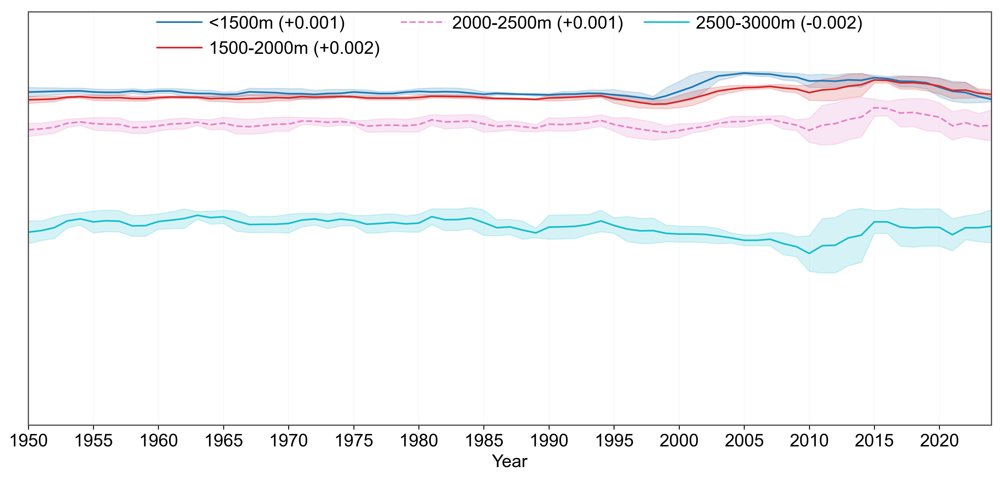

In [71]:
# -*- coding: utf-8 -*-
import os, glob
import xarray as xr
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import mapping
import rioxarray

# ========= 路径 =========
ISO_CONTOUR_SHP = r"C:\greenland\Greenland_shp\等间距等值线.shp"
NC_PATH   = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_DIR   = r"C:\greenland\1995bu"
OUT_CSV   = os.path.join(OUT_DIR, "Fig_Greenland_IsoContour_AlbedoTimeSeries.csv")
OUT_FIG   = os.path.join(OUT_DIR, "Fig_Greenland_IsoContour_AlbedoTimeSeries.png")

# ========= 读取数据 =========
try:
    ds = xr.open_dataset(NC_PATH)
    varname = "albedo"
    albedo = ds[varname]
    if not albedo.rio.crs:
        albedo.rio.write_crs("EPSG:4326", inplace=True)
except FileNotFoundError:
    print(f"错误：未找到NC文件 {NC_PATH}。")
    albedo = None
except Exception as e:
    print(f"读取NC文件时发生错误: {e}")
    albedo = None

# ========= 读取等值线分区 =========
regions = []
CUSTOM_REGION_NAMES = ['<1500m', '1500-2000m', '2000-2500m', '2500-3000m', '>3000m'] 

if albedo is not None:
    try:
        iso_gdf = gpd.read_file(ISO_CONTOUR_SHP).to_crs("EPSG:4326")
        for index, row in iso_gdf.head(len(CUSTOM_REGION_NAMES)).iterrows(): 
            name = CUSTOM_REGION_NAMES[index]
            g = gpd.GeoDataFrame([row], crs=iso_gdf.crs).dissolve().reset_index(drop=True)
            regions.append((name, g))
    except Exception as e:
        print(f"错误：读取等值线Shapefile失败：{e}")

# ========= 计算时间序列 =========
records = []
if regions and albedo is not None:
    for name, g in regions:
        print(f"Calculating region: {name}")
        mask = albedo.rio.clip(g.geometry.apply(mapping), g.crs, drop=False)
        ts = mask.mean(dim=("lat", "lon"), skipna=True).to_pandas()
        
        if not np.issubdtype(ts.index.dtype, np.datetime64):
            years = ds["time"].values
        else:
            years = pd.to_datetime(ts.index).year

        records.append(pd.DataFrame({"Year": years, "Albedo": ts.values, "Region": name}))

    if records:
        df = pd.concat(records, ignore_index=True).sort_values(["Region","Year"])
        df["mean_5yr"] = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).mean())
        df["std_5yr"]  = df.groupby("Region")["Albedo"].transform(lambda x: x.rolling(5, center=True, min_periods=1).std())
        df.to_csv(OUT_CSV, index=False)
        print("✅ Data saved:", OUT_CSV)
    else:
        df = None
        print("❌ 未能成功计算时间序列。")
else:
    print("❌ 未能成功加载区域或反照率数据，跳过时间序列计算和绘图。")
    df = None

# ========= 用户自定义 =========
LEGEND_Y_OFFSET = 1.03  # 图例垂直偏移量

# ======== 附加趋势信息 ========
trend_data = {
    "<1500m": 0.001483404,
    "1500-2000m": 0.001641699,
    "2000-2500m": 0.000724387,
    "2500-3000m": -0.00201562,
    ">3000m": np.nan
}
p_value_data = {
    "<1500m": 0.000193103,
    "1500-2000m": 5.53E-07,
    "2000-2500m": 0.12176295,
    "2500-3000m": 0.003052131,
    ">3000m": np.nan
}

# ========= 绘图 =========
if df is not None and not df.empty:
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 15,
        "axes.linewidth": 1.0,
        "axes.edgecolor": "0.3",
        "xtick.direction": "out",
        "ytick.direction": "out"
    })

    fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

    plotting_order = CUSTOM_REGION_NAMES
    unique_regions = [r for r in plotting_order if r in df["Region"].unique()]
    num_contoured_regions = len(unique_regions)
    colors = plt.cm.get_cmap('tab10', num_contoured_regions)

    for i, name in enumerate(unique_regions):
        col = colors(i)
        grp = df[df["Region"] == name]

        slope = trend_data.get(name, np.nan)
        pval  = p_value_data.get(name, np.nan)

        # ==== 显著性控制 ====
        if np.isnan(pval) or pval >= 0.05:
            linestyle = "--"      # 不显著 → 虚线
            alpha = 0.9
        else:
            linestyle = "-"       # 显著 → 实线
            alpha = 1.0

        label = f"{name} ({slope:+.3f})"
        ax.plot(grp["Year"], grp["mean_5yr"], color=col, lw=1.4, ls=linestyle, alpha=alpha, label=label)
        ax.fill_between(grp["Year"],
                        grp["mean_5yr"] - grp["std_5yr"],
                        grp["mean_5yr"] + grp["std_5yr"],
                        color=col, alpha=0.18)

    # ======== 图形美化 ========
    ax.set_xlabel("Year", fontsize=15)
    ax.set_yticks([])
    ax.set_yticklabels([])

    ax.set_xlim(1950, 2024)
    ax.set_xticks(np.arange(1950, 2025, 5))
    ax.set_ylim(0.50, 0.90)

    for spine in ['top', 'bottom', 'left', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(plt.rcParams['axes.linewidth'])
        ax.spines[spine].set_color(plt.rcParams['axes.edgecolor'])
    ax.grid(alpha=0.15, linewidth=0.4)

    # ======== 图例 (3行, 15号字体, 居中) ========
    ax.legend(frameon=False, fontsize=15, ncol=3, loc="upper center",
              bbox_to_anchor=(0.5, LEGEND_Y_OFFSET),
              handlelength=2.5, handletextpad=0.4, columnspacing=1.2)

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print("✅ Figure saved:", OUT_FIG)
else:
    print("❌ 无法绘图，因为数据帧 `df` 未成功生成或为空。")


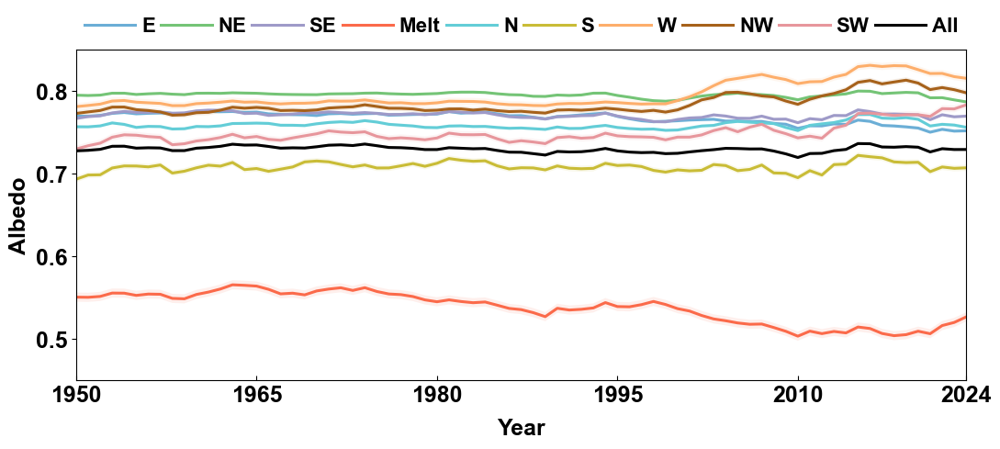

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ========= 参数与路径 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_Albedo_Clean_v18.png"

region_order = ['E','NE','SE','Melt','N','S','W','NW','SW','Entire']
region_display = ['E','NE','SE','Melt','N','S','W','NW','SW','All']
colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Entire':'#000000'
}

# ========= 样式设置 (npj 风格改进) =========
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.linewidth'] = 0.8      # 调细图框
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['xtick.major.width'] = 0.8   # 刻度线同步调细
plt.rcParams['ytick.major.width'] = 0.8

# ========= 数据处理 =========
df = pd.read_csv(CSV_PATH)
df['Variable'] = df['Variable'].replace({'alb': 'albedo'})
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW',
    'The Entire Greenland Area':'Entire'
})
sub = df[df['Variable'] == 'albedo'].copy()

# ========= 绘图 =========
fig, ax = plt.subplots(figsize=(11, 5))

handles = []
for r in region_order:
    dat = sub[sub['Region'] == r].sort_values('Year')
    if dat.empty: continue
    
    y_smooth = dat['Value'].rolling(5, center=True, min_periods=1).mean()
    line, = ax.plot(dat['Year'], y_smooth, color=colors[r], lw=2.2) # 曲线稍粗突出重点
    
    ax.fill_between(dat['Year'], y_smooth - dat['Value'].std()/4, 
                     y_smooth + dat['Value'].std()/4,
                     color=colors[r], alpha=0.1, edgecolor='none')
    handles.append(line)

# --------- 图例: 一行显示, 线长缩短, 左右对齐图框 ---------
ax.legend(handles, region_display, 
          loc='lower left', 
          bbox_to_anchor=(0, 1.02, 1, 0.1), 
          mode="expand", 
          ncol=10, 
          frameon=False, 
          handlelength=2.5,      # 线段更短
          handletextpad=0.3, 
          borderaxespad=0,       # 消除图例与轴的间隙
          prop={'weight': 'bold', 'size': 16}) # 图例字体 12

# --------- 坐标轴设置 ---------
# Y 轴刻度限定
ax.set_yticks([0.5, 0.6, 0.7, 0.8])
ax.set_yticklabels(['0.5', '0.6', '0.7', '0.8'], fontsize=18, fontweight='bold')
ax.set_ylim(0.45, 0.85)

# X 轴刻度 15 年一跳，包含 2024
years = np.arange(1950, 2024, 15).tolist()
if 2024 not in years: years.append(2024)

ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=18, fontweight='bold')
ax.set_xlim(1950, 2024)

# 标签 (Albedo 和 Year 不放大，维持原样或稍微调整)
ax.set_xlabel('Year', fontsize=18, fontweight='bold', labelpad=10)
ax.set_ylabel('Albedo', fontsize=18, fontweight='bold')

plt.tight_layout()
plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()

C:\Users\11823\AppData\Local\Temp\ipykernel_22188\1523227916.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


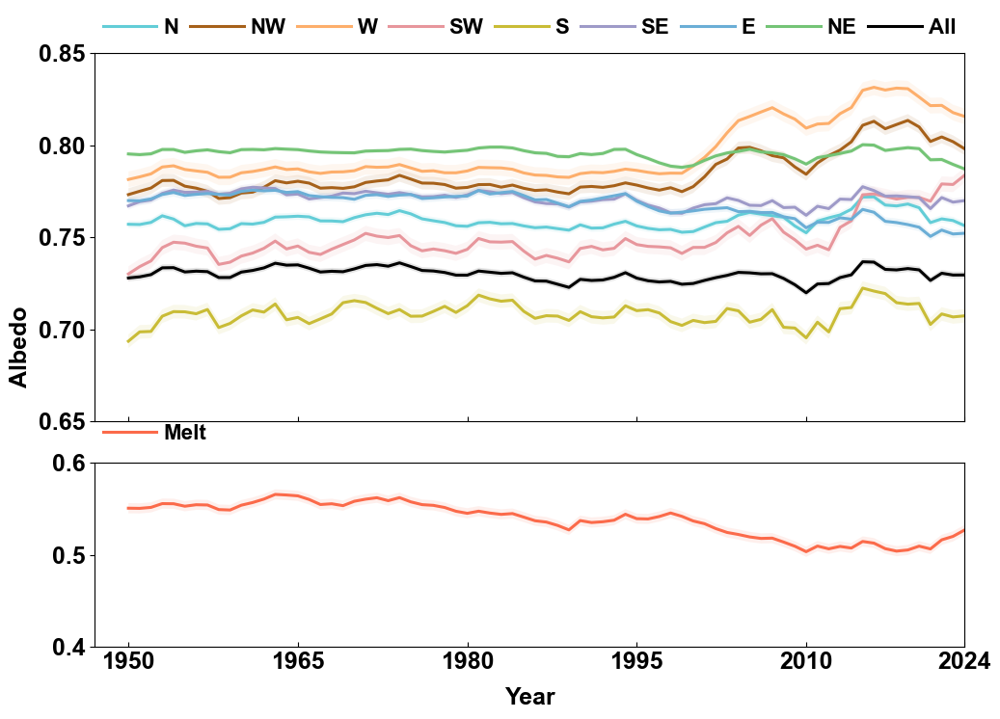

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ========= 参数与路径 =========
CSV_PATH = r"C:\greenland\1995bu\OtherVariables\Fig_Greenland_AllBasin_TimeSeries.csv"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig_Albedo_Clean_v18.png"

# 上图区域顺序
upper_order = ['N', 'NW', 'W', 'SW', 'S', 'SE', 'E', 'NE', 'Entire']
upper_display = ['N', 'NW', 'W', 'SW', 'S', 'SE', 'E', 'NE', 'All']

colors = {
    'E':'#6baed6','NE':'#74c476','SE':'#9e9ac8','Melt':'#fb6a4a','N':'#63cdd7',
    'S':'#c9bc36','W':'#fdae6b','NW':'#a6611a','SW':'#e7969c','Entire':'#000000'
}

# ========= 样式设置 =========
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'out'
plt.rcParams['xtick.major.width'] = 0.8
plt.rcParams['ytick.major.width'] = 0.8

# ========= 数据处理 =========
df = pd.read_csv(CSV_PATH)
df['Variable'] = df['Variable'].replace({'alb': 'albedo'})
df['Region'] = df['Region'].replace({
    'East':'E','EastNorth':'NE','EastSouth':'SE','Melt':'Melt',
    'North':'N','South':'S','West':'W','WestNorth':'NW','WestSouth':'SW',
    'The Entire Greenland Area':'Entire'
})
sub = df[df['Variable'] == 'albedo'].copy()

# ========= 创建子图 =========
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, 
                                gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.15})

# ========= 上图：其他区域 (Y轴 0.65-0.85) =========
handles_upper = []
for r in upper_order:
    dat = sub[sub['Region'] == r].sort_values('Year')
    if dat.empty: continue
    
    y_smooth = dat['Value'].rolling(5, center=True, min_periods=1).mean()
    line, = ax1.plot(dat['Year'], y_smooth, color=colors[r], lw=2.2)
    
    ax1.fill_between(dat['Year'], y_smooth - dat['Value'].std()/4, 
                     y_smooth + dat['Value'].std()/4,
                     color=colors[r], alpha=0.1, edgecolor='none')
    handles_upper.append(line)

# 上图图例
ax1.legend(handles_upper, upper_display, 
          loc='lower left', 
          bbox_to_anchor=(0, 1.02, 1, 0.1), 
          mode="expand", 
          ncol=9, 
          frameon=False, 
          handlelength=2.5,
          handletextpad=0.3, 
          borderaxespad=0,
          prop={'weight': 'bold', 'size': 16})

# 上图Y轴设置
ax1.set_yticks([0.65, 0.70, 0.75, 0.80, 0.85])
ax1.set_yticklabels(['0.65', '0.70', '0.75', '0.80', '0.85'], fontsize=18, fontweight='bold')
ax1.set_ylim(0.65, 0.85)

# ========= 下图：Melt (Y轴 0.4-0.6) =========
dat_melt = sub[sub['Region'] == 'Melt'].sort_values('Year')
if not dat_melt.empty:
    y_smooth = dat_melt['Value'].rolling(5, center=True, min_periods=1).mean()
    line_melt, = ax2.plot(dat_melt['Year'], y_smooth, color=colors['Melt'], lw=2.2, label='Melt')
    
    ax2.fill_between(dat_melt['Year'], y_smooth - dat_melt['Value'].std()/4, 
                     y_smooth + dat_melt['Value'].std()/4,
                     color=colors['Melt'], alpha=0.1, edgecolor='none')

# 下图图例 - 放在子图框上面，增加垂直距离
ax2.legend(['Melt'], 
          loc='lower left', 
          bbox_to_anchor=(0, 1.06, 1, 0.1), 
          mode="expand", 
          ncol=1, 
          frameon=False, 
          handlelength=2.5,
          handletextpad=0.3, 
          borderaxespad=0,
          prop={'weight': 'bold', 'size': 16})

# 下图Y轴设置 - 只显示3个刻度
ax2.set_yticks([0.4, 0.5, 0.6])
ax2.set_yticklabels(['0.4', '0.5', '0.6'], fontsize=18, fontweight='bold')
ax2.set_ylim(0.40, 0.60)

# ========= 共用X轴设置 =========
years = np.arange(1950, 2024, 15).tolist()
if 2024 not in years: years.append(2024)

ax2.set_xticks(years)
ax2.set_xticklabels([str(y) for y in years], fontsize=18, fontweight='bold')
ax2.set_xlim(1947, 2024)  # 左边界左移，避免1950与Y轴重叠
ax2.set_xlabel('Year', fontsize=18, fontweight='bold', labelpad=10)

# 移除上图的X轴刻度标签（保留刻度线）
ax1.tick_params(labelbottom=False)

# ========= 整个图只显示一个Y轴标签 =========
fig.text(0.0, 0.5, 'Albedo', va='center', rotation='vertical', 
         fontsize=18, fontweight='bold')

# 移除各子图自己的Y轴标签
ax1.set_ylabel('')
ax2.set_ylabel('')

plt.tight_layout()
plt.subplots_adjust(left=0.08)  # 为左侧Y轴标签留出空间
plt.savefig(SAVE_PATH, dpi=400, bbox_inches='tight')
plt.show()